# Hospitality CLTV — End-to-end GPU pipeline (notebook version)
Synthetic hotel-loyalty data → leakage-safe features → 5 CLTV paradigms (BG/NBD+Gamma-Gamma, GBDT Tweedie/Hurdle, FT-Transformer ZILN, GRU+Attention ZILN, Weibull survival) → evaluation → plots.
Same code as `src/` (API/screenshot code excluded). Artifacts are written to `output_notebook/`.

In [1]:
import json, time, copy, math, logging, sys
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Callable, Literal
import joblib, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, yaml
from scipy.optimize import minimize
from scipy.special import gammaln, hyp2f1
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
import warnings; warnings.filterwarnings('ignore')
from IPython.display import Image, display
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

torch 2.15.0+cu132 | CUDA True | NVIDIA GeForce RTX 3090


## 0. Config

In [2]:
print(Path('config/config.yaml').read_text())

seed: 42
paths:
  output: output
data:
  n_guests: 50000
  target_bookings: 220000
  start_date: "2023-01-01"
  months_total: 36
  calibration_months: 24
  horizon_months: 12
  seq_len: 16
split: {train: 0.70, val: 0.15, test: 0.15}
gpu: {enabled: true}
models:
  xgboost: {n_estimators: 1500, learning_rate: 0.03, max_depth: 6, subsample: 0.8, colsample_bytree: 0.8, tweedie_variance_power: 1.4, early_stopping_rounds: 60}
  catboost: {iterations: 1500, learning_rate: 0.08, depth: 6, loss_function: "Tweedie:variance_power=1.4", early_stopping_rounds: 60}
  lightgbm_hurdle: {n_estimators: 800, learning_rate: 0.04, num_leaves: 48, early_stopping_rounds: 50}
  ft_ziln: {d_token: 48, n_blocks: 3, n_heads: 4, dropout: 0.15, epochs: 60, batch_size: 512, lr: 0.001, weight_decay: 0.0001, patience: 8}
  seq_ziln: {d_model: 64, n_heads: 4, epochs: 50, batch_size: 512, lr: 0.002, weight_decay: 0.0001, dropout: 0.1, patience: 8}
  survival: {hidden: 128, epochs: 60, batch_size: 512, lr: 0.002, weight

## 1. Logging utilities (`logger.py`)

In [3]:
"""Centralized logging: console + execution.log, JSONL metric/epoch tracking, GPU diagnostics."""

import json
import logging
import sys
import time
from pathlib import Path
from typing import Any

import yaml

ROOT = Path.cwd()
SUBDIRS = ["models", "data", "plots/eda", "plots/features", "plots/training_loss",
           "plots/comparisons", "logs", "api_screenshots"]


def load_config(path: Path | None = None) -> dict[str, Any]:
    """Load YAML config and resolve the output directory to an absolute path."""
    cfg = yaml.safe_load((path or ROOT / "config" / "config.yaml").read_text())
    cfg["out"] = (ROOT / cfg["paths"]["output"]).resolve()
    return cfg


def ensure_dirs(out: Path) -> None:
    for s in SUBDIRS:
        (out / s).mkdir(parents=True, exist_ok=True)


def get_logger(out: Path, name: str = "cltv") -> logging.Logger:
    """Return a logger writing to console and output/logs/execution.log."""
    ensure_dirs(out)
    lg = logging.getLogger(name)
    if lg.handlers:
        return lg
    lg.setLevel(logging.INFO)
    fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    fh = logging.FileHandler(out / "logs" / "execution.log", encoding="utf-8")
    fh.setFormatter(fmt)
    lg.addHandler(sh)
    lg.addHandler(fh)
    return lg


def append_jsonl(path: Path, record: dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps({"ts": time.time(), **record}, default=float) + "\n")


def gpu_memory_mb() -> float:
    try:
        import torch
        return float(torch.cuda.memory_allocated() / 2**20) if torch.cuda.is_available() else 0.0
    except Exception:
        return 0.0


def log_epoch(out: Path, model: str, epoch: int, train_loss: float, val_loss: float, lr: float) -> None:
    """Append one epoch record to training_history.jsonl."""
    append_jsonl(out / "logs" / "training_history.jsonl", dict(
        model=model, epoch=epoch, train_loss=float(train_loss), val_loss=float(val_loss),
        lr=float(lr), gpu_mem_mb=gpu_memory_mb()))


def get_device(cfg: dict[str, Any], lg: logging.Logger | None = None) -> str:
    """Return 'cuda' if available and enabled, else 'cpu'; log hardware details."""
    import torch
    use = cfg["gpu"]["enabled"] and torch.cuda.is_available()
    if lg:
        if use:
            p = torch.cuda.get_device_properties(0)
            lg.info(f"GPU: {p.name} | VRAM {p.total_memory/2**30:.1f} GB | torch {torch.__version__} | CUDA {torch.version.cuda}")
        else:
            lg.info("CUDA unavailable/disabled -> CPU")
    return "cuda" if use else "cpu"


## 2. Synthetic data generator (`data_generator.py`)

In [4]:
"""Synthetic hospitality guest + booking generator (BG/NBD-style latent process with hospitality effects)."""

import numpy as np
import pandas as pd

TIERS = ["Member", "Silver", "Gold", "Platinum", "Titanium"]
CHANNELS = ["Direct Web", "Mobile App", "OTA", "Corporate GDS"]
REGIONS = ["North America", "Europe", "APAC", "Middle East", "LATAM"]
ROOMS = ["Standard", "Deluxe", "Suite", "Club"]
PROP_TIERS = ["Luxury", "Premium", "Select Service"]


def _guests(n: int, rng: np.random.Generator) -> pd.DataFrame:
    tier_p = np.array([0.52, 0.22, 0.14, 0.08, 0.04])
    tier = rng.choice(len(TIERS), n, p=tier_p)
    channel = rng.choice(len(CHANNELS), n, p=[0.30, 0.25, 0.30, 0.15])
    region = rng.choice(len(REGIONS), n, p=[0.35, 0.25, 0.22, 0.08, 0.10])
    card = (rng.random(n) < (0.05 + 0.08 * tier)).astype(int)
    p_biz = np.where(channel == 3, 0.85, 0.25)
    biz = (rng.random(n) < p_biz).astype(int)
    # latent behaviour: purchase rate (stays / month), dropout prob per stay, value multiplier
    lam = rng.gamma(1.6, 0.11, n) * (1 + 0.35 * tier) * (1 + 0.25 * card) * np.where(biz == 1, 1.3, 1.0)
    p_drop = np.clip(rng.beta(1.1, 3.0, n) * (1 - 0.10 * tier), 0.02, 0.9)
    value = rng.lognormal(0.0, 0.35, n) * (1 + 0.18 * tier)
    anc_aff = rng.beta(1.5, 3.5, n) * (1 + 0.10 * tier)
    acq_day = rng.uniform(0, 22 * 30.4, n)
    return pd.DataFrame(dict(
        guest_id=np.arange(n), loyalty_tier=np.array(TIERS)[tier], acquisition_channel=np.array(CHANNELS)[channel],
        home_region=np.array(REGIONS)[region], cobrand_card=card, is_business_guest=biz, acq_day=acq_day,
        _lam=lam, _p_drop=p_drop, _value=value, _anc=anc_aff, _tier_i=tier, _chan_i=channel))


def _simulate_times(g: pd.DataFrame, scale: float, total_days: int, rng: np.random.Generator, kmax: int = 80):
    n = len(g)
    lam_day = (g["_lam"].values * scale / 30.4)[:, None]
    gaps = rng.exponential(1.0, (n, kmax)) / lam_day
    gaps[:, 0] = 0.0
    t = g["acq_day"].values[:, None] + np.cumsum(gaps, axis=1)
    # dropout: after each stay the guest churns w.p. p_drop
    churn_at = rng.geometric(g["_p_drop"].values)[:, None]  # index (1-based) of last alive stay
    alive = np.arange(1, kmax + 1)[None, :] <= churn_at
    return t, alive & (t < total_days)


def generate(cfg: dict, seed: int = 42) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return (guests, bookings). Rate scale is calibrated so total bookings ~ target_bookings."""
    d = cfg["data"]
    rng = np.random.default_rng(seed)
    n = d["n_guests"]
    total_days = int(d["months_total"] * 30.4)
    g = _guests(n, rng)
    target = d["target_bookings"] * n / 50000 * 1.045  # compensates for off-peak thinning
    lo, hi = 0.2, 6.0
    for _ in range(14):  # bisection on the rate scale
        mid = (lo + hi) / 2
        _, m = _simulate_times(g, mid, total_days, np.random.default_rng(seed + 1))
        if m.sum() < target:
            lo = mid
        else:
            hi = mid
    scale = (lo + hi) / 2
    t, mask = _simulate_times(g, scale, total_days, np.random.default_rng(seed + 2))
    gi, ki = np.nonzero(mask)
    b = pd.DataFrame({"guest_id": gi, "checkin_day": t[gi, ki]})
    gg = g.iloc[gi].reset_index(drop=True)
    m = len(b)
    start = pd.Timestamp(d["start_date"])
    b["checkin_date"] = start + pd.to_timedelta(np.floor(b["checkin_day"]).astype(int), unit="D")
    month = b["checkin_date"].dt.month.values
    peak = np.isin(month, [6, 7, 8, 12])
    is_biz = (rng.random(m) < np.where(gg["is_business_guest"] == 1, 0.8, 0.12)).astype(int)
    # leisure stays skew to peak months: thin off-peak leisure stays slightly
    keep = np.where((is_biz == 0) & (~peak) & (ki > 0), rng.random(m) < 0.85, True)
    b, gg, is_biz, peak, month = b[keep].reset_index(drop=True), gg[keep].reset_index(drop=True), is_biz[keep], peak[keep], month[keep]
    m = len(b)
    los = 1 + rng.poisson(np.where(is_biz == 1, 1.2, 2.2), m)
    b["length_of_stay"] = los
    b["checkout_date"] = b["checkin_date"] + pd.to_timedelta(los, unit="D")
    b["is_business"] = is_biz
    b["booking_lead_time"] = np.clip(rng.gamma(np.where(is_biz == 1, 1.5, 2.2), np.where(is_biz == 1, 6, 22)), 0, 365).round().astype(int)
    ti = gg["_tier_i"].values
    prop_p = np.stack([0.12 + 0.07 * ti, 0.38 + 0.0 * ti, 0.50 - 0.07 * ti], 1)
    prop_p = np.clip(prop_p, 0.02, None); prop_p /= prop_p.sum(1, keepdims=True)
    pr = (rng.random(m)[:, None] > prop_p.cumsum(1)).sum(1).clip(0, 2)
    b["property_tier"] = np.array(PROP_TIERS)[pr]
    room = np.clip(rng.choice(4, m, p=[0.45, 0.30, 0.15, 0.10]) + (ti >= 3) * rng.integers(0, 2, m), 0, 3)
    b["room_type"] = np.array(ROOMS)[room]
    base = np.array([320.0, 190.0, 110.0])[pr] * (1 + 0.22 * room) * (1 + 0.20 * peak) * gg["_value"].values
    b["adr"] = (base * rng.lognormal(0, 0.12, m)).round(2)
    # lead-time effect: early bookers get a small discount
    b["adr"] = (b["adr"] * (1 - 0.0006 * np.minimum(b["booking_lead_time"], 120))).round(2)
    room_rev = b["adr"].values * los
    aff = gg["_anc"].values
    lux = (pr == 0) * 1.0 + (pr == 1) * 0.6 + (pr == 2) * 0.25
    b["fb_spend"] = (rng.random(m) < 0.4 + 0.5 * aff) * rng.gamma(2, 22 * los * lux * (1 + aff))
    b["spa_spend"] = (rng.random(m) < 0.05 + 0.5 * aff * lux) * rng.gamma(2, 60 * lux)
    b["golf_spend"] = (rng.random(m) < 0.03 + 0.2 * aff * lux * (is_biz == 0)) * rng.gamma(2, 90 * lux)
    b["parking_spend"] = (rng.random(m) < 0.3) * 18 * los
    for c in ["fb_spend", "spa_spend", "golf_spend", "parking_spend"]:
        b[c] = b[c].round(2)
    p_cancel = np.clip(0.07 + 0.001 * np.minimum(b["booking_lead_time"], 150) - 0.012 * ti + 0.05 * (gg["acquisition_channel"] == "OTA"), 0.01, 0.5)
    b["is_cancelled"] = (rng.random(m) < p_cancel).astype(int)
    b["room_revenue"] = (room_rev * (1 - b["is_cancelled"])).round(2)
    b["ancillary_revenue"] = ((b[["fb_spend", "spa_spend", "golf_spend", "parking_spend"]].sum(1)) * (1 - b["is_cancelled"])).round(2)
    b["total_revenue"] = b["room_revenue"] + b["ancillary_revenue"]
    b["booking_channel"] = np.where(rng.random(m) < 0.65, gg["acquisition_channel"].values, rng.choice(CHANNELS, m))
    b = b.sort_values(["guest_id", "checkin_day"]).reset_index(drop=True)
    b.insert(0, "booking_id", np.arange(len(b)))
    # guest attrs: first stay defines the tenure origin
    guests = g[["guest_id", "loyalty_tier", "acquisition_channel", "home_region", "cobrand_card", "is_business_guest", "acq_day"]].copy()
    guests["first_stay_date"] = start + pd.to_timedelta(np.floor(guests["acq_day"]).astype(int), unit="D")
    guests = guests[guests["guest_id"].isin(b["guest_id"])].reset_index(drop=True)
    return guests, b


## 3. Feature engineering, targets & sequence tensors (`features.py`)

In [5]:
"""Feature engineering: leakage-safe calibration-window features, targets, and sequence tensors."""

from dataclasses import dataclass
from typing import Any

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split


DAYS_PER_MONTH = 30.4
CAT_COLS = ["loyalty_tier", "acquisition_channel", "home_region"]
CAT_LEVELS = {"loyalty_tier": TIERS, "acquisition_channel": CHANNELS, "home_region": REGIONS}
NUM_COLS = [
    "recency_days", "T_days", "frequency", "repeat_x", "t_x", "monetary_mean", "monetary_total", "ia_mean", "ia_std",
    "spend_trend", "adr_expansion", "anc_ratio", "direct_share", "cancel_rate", "weekend_ratio", "peak_affinity",
    "mean_los", "mean_lead", "biz_share", "luxury_share", "stays_6m", "stays_12m", "rev_12m", "mean_adr",
    "tier_ord", "cobrand_card", "is_business_guest", "n_bookings",
]
SEQ_FEATS = ["log_rev", "log_adr", "los", "log_lead", "is_business", "is_cancelled", "anc_ratio", "weekend",
             "peak", "prop_ord", "room_ord", "direct", "log_dt", "log_since"]
BOOKING_COLS = ["guest_id", "checkin_day", "checkin_date", "total_revenue", "room_revenue", "ancillary_revenue", "adr",
                "length_of_stay", "booking_lead_time", "is_business", "is_cancelled", "booking_channel",
                "property_tier", "room_type"]


@dataclass
class Dataset:
    """Container for modelling tables (feature frame, targets, sequences, splits)."""
    df: pd.DataFrame            # index=guest_id; NUM_COLS + CAT_COLS + targets
    seq: np.ndarray             # (N, L, F) float32
    seq_mask: np.ndarray        # (N, L) bool, True=real stay
    seq_dt: np.ndarray          # (N, L) days since previous stay
    seq_abs: np.ndarray         # (N, L) days before cutoff
    split: np.ndarray           # array of 'train'/'val'/'test'
    cutoff_day: float
    horizon_days: float

    def idx(self, name: str) -> np.ndarray:
        return np.where(self.split == name)[0]


def encode_cats(df: pd.DataFrame) -> pd.DataFrame:
    """Integer-code categoricals with fixed level lists (no fitted state)."""
    out = df.copy()
    for c, lv in CAT_LEVELS.items():
        out[c + "_code"] = pd.Categorical(out[c], categories=lv).codes.astype(int)
    return out


def tree_columns() -> list[str]:
    return NUM_COLS + [c + "_code" for c in CAT_COLS]


def _slope(x: np.ndarray, y: np.ndarray, g: np.ndarray, n: int) -> np.ndarray:
    """Per-group OLS slope of y on x (0 where undefined)."""
    cnt = np.bincount(g, minlength=n).astype(float)
    sx, sy = np.bincount(g, x, n), np.bincount(g, y, n)
    sxy, sxx = np.bincount(g, x * y, n), np.bincount(g, x * x, n)
    num = cnt * sxy - sx * sy
    den = cnt * sxx - sx ** 2
    ok = den > 1e-2
    return np.clip(np.where(ok, num / np.where(ok, den, 1), 0.0), -5000, 5000)


def build_features(guests: pd.DataFrame, bookings: pd.DataFrame, cutoff_day: float) -> pd.DataFrame:
    """Build per-guest features using only bookings with checkin_day < cutoff_day."""
    b = bookings[bookings["checkin_day"] < cutoff_day].copy()
    b = b.sort_values(["guest_id", "checkin_day"])
    ids = np.sort(guests["guest_id"].values)
    pos = {g: i for i, g in enumerate(ids)}
    b = b[b["guest_id"].isin(pos)]
    gi = b["guest_id"].map(pos).values
    n = len(ids)
    ok = b["is_cancelled"].values == 0
    day = b["checkin_day"].values

    def safe(a: np.ndarray, c: np.ndarray) -> np.ndarray:
        return np.divide(a, c, out=np.zeros(n), where=c > 0)

    cnt_all = np.bincount(gi, minlength=n).astype(float)
    cnt = np.bincount(gi[ok], minlength=n).astype(float)
    first_any = np.full(n, cutoff_day)
    np.minimum.at(first_any, gi, day)
    first_ok = np.full(n, np.inf)
    np.minimum.at(first_ok, gi[ok], day[ok])
    last_ok = np.full(n, -np.inf)
    np.maximum.at(last_ok, gi[ok], day[ok])
    has = cnt > 0
    first_ok = np.where(has, first_ok, first_any)
    last_ok = np.where(has, last_ok, first_any)
    tot = np.bincount(gi[ok], b["total_revenue"].values[ok], n)

    bo = b[ok]
    gio = gi[ok]
    d_o = bo["checkin_day"].values
    dd = np.diff(d_o, prepend=np.nan)
    first_flag = np.r_[True, gio[1:] != gio[:-1]] if len(gio) else np.array([], bool)
    dd = np.where(first_flag, np.nan, dd)
    v = ~np.isnan(dd)
    ia_n = np.bincount(gio[v], minlength=n).astype(float)
    ia_s = np.bincount(gio[v], dd[v], n)
    ia_ss = np.bincount(gio[v], dd[v] ** 2, n)
    ia_mean = safe(ia_s, ia_n)
    ia_std = np.sqrt(np.maximum(safe(ia_ss, ia_n) - ia_mean ** 2, 0))
    trend = _slope(d_o / DAYS_PER_MONTH, bo["total_revenue"].values, gio, n)
    adr_o = bo["adr"].values
    rank = bo.groupby("guest_id").cumcount().values
    nstay = np.bincount(gio, minlength=n)
    first_adr = np.bincount(gio[rank == 0], adr_o[rank == 0], n)
    last_mask = rank == (nstay[gio] - 1)
    last_adr = np.bincount(gio[last_mask], adr_o[last_mask], n)
    adr_exp = np.where(first_adr > 0, last_adr / np.maximum(first_adr, 1e-9), 1.0)
    room_rev = np.bincount(gio, bo["room_revenue"].values, n)
    anc_rev = np.bincount(gio, bo["ancillary_revenue"].values, n)
    ci = pd.to_datetime(bo["checkin_date"])
    weekend = ci.dt.dayofweek.isin([4, 5]).values.astype(float)
    peak = ci.dt.month.isin([6, 7, 8, 12]).values.astype(float)
    lux = (bo["property_tier"] == "Luxury").values.astype(float)
    ball_direct = b["booking_channel"].isin(["Direct Web", "Mobile App"]).values.astype(float)
    r12 = d_o >= cutoff_day - 12 * DAYS_PER_MONTH

    f = pd.DataFrame(index=ids)
    f["recency_days"] = cutoff_day - last_ok
    f["T_days"] = cutoff_day - first_any
    f["frequency"] = cnt
    f["repeat_x"] = np.maximum(cnt - 1, 0)
    f["t_x"] = np.where(cnt > 1, last_ok - first_ok, 0.0)
    f["monetary_mean"] = safe(tot, cnt)
    f["monetary_total"] = tot
    f["ia_mean"], f["ia_std"], f["spend_trend"], f["adr_expansion"] = ia_mean, ia_std, trend, adr_exp
    f["anc_ratio"] = safe(anc_rev, room_rev)
    f["direct_share"] = safe(np.bincount(gi, ball_direct, n), cnt_all)
    f["cancel_rate"] = safe(cnt_all - cnt, cnt_all)
    f["weekend_ratio"] = safe(np.bincount(gio, weekend, n), cnt)
    f["peak_affinity"] = safe(np.bincount(gio, peak, n), cnt)
    f["mean_los"] = safe(np.bincount(gio, bo["length_of_stay"].values, n), cnt)
    f["mean_lead"] = safe(np.bincount(gio, bo["booking_lead_time"].values, n), cnt)
    f["biz_share"] = safe(np.bincount(gio, bo["is_business"].values, n), cnt)
    f["luxury_share"] = safe(np.bincount(gio, lux, n), cnt)
    f["stays_6m"] = np.bincount(gio[d_o >= cutoff_day - 6 * DAYS_PER_MONTH], minlength=n)
    f["stays_12m"] = np.bincount(gio[r12], minlength=n)
    f["rev_12m"] = np.bincount(gio[r12], bo["total_revenue"].values[r12], n)
    f["mean_adr"] = safe(np.bincount(gio, adr_o, n), cnt)
    f["n_bookings"] = cnt_all
    g = guests.set_index("guest_id").loc[ids]
    f["tier_ord"] = pd.Categorical(g["loyalty_tier"], categories=TIERS).codes
    f["cobrand_card"] = g["cobrand_card"].values
    f["is_business_guest"] = g["is_business_guest"].values
    for c in CAT_COLS:
        f[c] = g[c].values
    f.index.name = "guest_id"
    return f


def build_sequences(bookings: pd.DataFrame, ids: np.ndarray, cutoff_day: float, L: int):
    """Right-aligned (most recent last), left-padded chronological stay tensors."""
    b = bookings[bookings["checkin_day"] < cutoff_day].sort_values(["guest_id", "checkin_day"])
    pos = {g: i for i, g in enumerate(ids)}
    b = b[b["guest_id"].isin(pos)].copy()
    gi = b["guest_id"].map(pos).values
    n = len(ids)
    cnt = np.bincount(gi, minlength=n)
    rank = b.groupby("guest_id").cumcount().values
    day_all = b["checkin_day"].values
    newg_all = np.r_[True, gi[1:] != gi[:-1]]
    dt_all = np.where(newg_all, 0.0, day_all - np.r_[np.nan, day_all[:-1]])
    rfe = cnt[gi] - 1 - rank
    keep = rfe < L
    b, gi, rfe, dt = b[keep], gi[keep], rfe[keep], dt_all[keep]
    slot = L - 1 - rfe
    day = b["checkin_day"].values
    ci = pd.to_datetime(b["checkin_date"])
    room_rev, anc = b["room_revenue"].values, b["ancillary_revenue"].values
    feats = np.stack([
        np.log1p(b["total_revenue"].values), np.log(b["adr"].values + 1), b["length_of_stay"].values / 5.0,
        np.log1p(b["booking_lead_time"].values), b["is_business"].values.astype(float),
        b["is_cancelled"].values.astype(float),
        np.minimum(np.divide(anc, np.maximum(room_rev, 1), out=np.zeros_like(anc), where=room_rev > 0), 3.0),
        ci.dt.dayofweek.isin([4, 5]).values.astype(float), ci.dt.month.isin([6, 7, 8, 12]).values.astype(float),
        pd.Categorical(b["property_tier"], categories=PROP_TIERS).codes / 2.0,
        pd.Categorical(b["room_type"], categories=ROOMS).codes / 3.0,
        b["booking_channel"].isin(["Direct Web", "Mobile App"]).values.astype(float),
        np.log1p(dt), np.log1p(cutoff_day - day),
    ], 1).astype(np.float32)
    seq = np.zeros((n, L, len(SEQ_FEATS)), np.float32)
    mask = np.zeros((n, L), bool)
    sdt = np.zeros((n, L), np.float32)
    sabs = np.zeros((n, L), np.float32)
    seq[gi, slot] = feats
    mask[gi, slot] = True
    sdt[gi, slot] = dt
    sabs[gi, slot] = cutoff_day - day
    return seq, mask, sdt, sabs


def build_targets(guests: pd.DataFrame, bookings: pd.DataFrame, cutoff_day: float, horizon_days: float) -> pd.DataFrame:
    """Future-window targets: revenue, #stays, time-to-first-return (censored at horizon), event flag."""
    ids = np.sort(guests["guest_id"].values)
    pos = {g: i for i, g in enumerate(ids)}
    n = len(ids)
    b = bookings[(bookings["checkin_day"] >= cutoff_day) & (bookings["checkin_day"] < cutoff_day + horizon_days)
                 & (bookings["is_cancelled"] == 0) & bookings["guest_id"].isin(pos)]
    gi = b["guest_id"].map(pos).values
    y = np.bincount(gi, b["total_revenue"].values, n)
    ny = np.bincount(gi, minlength=n)
    first = np.full(n, horizon_days)
    np.minimum.at(first, gi, b["checkin_day"].values - cutoff_day)
    return pd.DataFrame({"y": y, "y_n": ny, "y_ret": (ny > 0).astype(int), "y_time": np.maximum(first, 0.5),
                         "y_event": (ny > 0).astype(int)}, index=pd.Index(ids, name="guest_id"))


def build_dataset(guests: pd.DataFrame, bookings: pd.DataFrame, cfg: dict[str, Any], seed: int = 42) -> Dataset:
    """Assemble features, targets, sequences and a stratified guest-level train/val/test split."""
    d = cfg["data"]
    cutoff = d["calibration_months"] * DAYS_PER_MONTH
    horizon = d["horizon_months"] * DAYS_PER_MONTH
    df = build_features(guests, bookings, cutoff).join(build_targets(guests, bookings, cutoff, horizon))
    df = encode_cats(df)
    seq, mask, sdt, sabs = build_sequences(bookings, df.index.values, cutoff, d["seq_len"])
    s = cfg["split"]
    idx = np.arange(len(df))
    tr, rest = train_test_split(idx, test_size=1 - s["train"], random_state=seed, stratify=df["y_ret"])
    va, te = train_test_split(rest, test_size=s["test"] / (s["val"] + s["test"]), random_state=seed,
                              stratify=df["y_ret"].values[rest])
    split = np.empty(len(df), dtype=object)
    split[tr], split[va], split[te] = "train", "val", "test"
    return Dataset(df, seq, mask, sdt, sabs, split, cutoff, horizon)


## 4a. Shared model utilities, ZILN loss, torch trainer (`models/common.py`)

In [6]:
"""Shared model utilities: inputs container, numeric preprocessing, ZILN loss, generic torch trainer."""

import copy
import logging
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F



@dataclass
class Inputs:
    """Model inputs for a set of guests (tabular frame + optional sequence tensors)."""
    df: pd.DataFrame
    seq: np.ndarray | None = None
    mask: np.ndarray | None = None
    sabs: np.ndarray | None = None


def subset(ds: Dataset, name: str) -> tuple[Inputs, pd.DataFrame]:
    idx = ds.idx(name)
    return Inputs(ds.df.iloc[idx], ds.seq[idx], ds.seq_mask[idx], ds.seq_abs[idx]), ds.df.iloc[idx]


class NumPrep:
    """Signed-log1p + standardisation for numeric features (fit on train only)."""

    def __init__(self) -> None:
        self.mean: np.ndarray | None = None
        self.std: np.ndarray | None = None

    @staticmethod
    def _t(x: np.ndarray) -> np.ndarray:
        return np.sign(x) * np.log1p(np.abs(x))

    def fit(self, df: pd.DataFrame) -> "NumPrep":
        x = self._t(df[NUM_COLS].values.astype(np.float64))
        self.mean, self.std = x.mean(0), x.std(0) + 1e-6
        return self

    def transform(self, df: pd.DataFrame) -> np.ndarray:
        x = self._t(df[NUM_COLS].values.astype(np.float64))
        return np.clip((x - self.mean) / self.std, -6, 6).astype(np.float32)

    def codes(self, df: pd.DataFrame) -> np.ndarray:
        return df[[c + "_code" for c in CAT_COLS]].values.astype(np.int64)


def ziln_loss(logit: torch.Tensor, mu: torch.Tensor, raw_sigma: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    """Zero-Inflated Log-Normal loss: BCE(return) + positive-only log-normal NLL (constants dropped)."""
    pos = (y > 0).float()
    sigma = F.softplus(raw_sigma) + 1e-3
    ly = torch.log(y.clamp_min(1e-6))
    nll = torch.log(sigma) + 0.5 * ((ly - mu) / sigma) ** 2
    bce = F.binary_cross_entropy_with_logits(logit, pos, reduction="none")
    return (bce + pos * nll).mean()


def ziln_mean(logit: torch.Tensor, mu: torch.Tensor, raw_sigma: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Return (expected value, return probability)."""
    sigma = F.softplus(raw_sigma) + 1e-3
    p = torch.sigmoid(logit)
    return p * torch.exp((mu + 0.5 * sigma ** 2).clamp(max=14.0)), p


def fit_torch(model: torch.nn.Module, train_t: tuple[torch.Tensor, ...], val_t: tuple[torch.Tensor, ...],
              loss_fn: Callable[[torch.nn.Module, tuple[torch.Tensor, ...]], torch.Tensor], hp: dict, name: str,
              out: Path, lg: logging.Logger) -> dict[str, list[float]]:
    """Generic mini-batch trainer: AdamW, ReduceLROnPlateau, early stopping, best-state restore, JSONL epoch logs."""
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    n, bs = train_t[0].shape[0], hp["batch_size"]
    hist: dict[str, list[float]] = {"train": [], "val": []}
    best, best_state, bad = float("inf"), None, 0
    for ep in range(1, hp["epochs"] + 1):
        model.train()
        perm = torch.randperm(n, device=train_t[0].device)
        tot = 0.0
        for i in range(0, n, bs):
            ix = perm[i:i + bs]
            loss = loss_fn(model, tuple(t[ix] for t in train_t))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tot += loss.item() * len(ix)
        model.eval()
        with torch.no_grad():
            m = val_t[0].shape[0]
            vl = sum(loss_fn(model, tuple(t[j:j + 4096] for t in val_t)).item() * len(val_t[0][j:j + 4096])
                     for j in range(0, m, 4096)) / m
        tl = tot / n
        sched.step(vl)
        hist["train"].append(tl)
        hist["val"].append(vl)
        log_epoch(out, name, ep, tl, vl, opt.param_groups[0]["lr"])
        if vl < best - 1e-5:
            best, bad, best_state = vl, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= hp["patience"]:
                lg.info(f"[{name}] early stop @ epoch {ep} (best val {best:.4f})")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    lg.info(f"[{name}] epochs={len(hist['train'])} best_val={best:.4f}")
    return hist


## 4b. BG/NBD + Gamma-Gamma (`models/probabilistic.py`)

In [7]:
"""BG/NBD + Gamma-Gamma probabilistic CLTV baseline (own vectorised implementation, no `lifetimes` dependency)."""

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import gammaln, hyp2f1


WEEK = 7.0


def _rft(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return (x repeat count, t_x, T) in weeks; T measured from first *completed* stay when one exists."""
    x = df["repeat_x"].values.astype(float)
    tx = df["t_x"].values / WEEK
    has = df["frequency"].values > 0
    T = np.where(has, df["t_x"].values + df["recency_days"].values, df["T_days"].values) / WEEK
    return x, np.minimum(tx, T), np.maximum(T, 1e-3)


class BGNBDGammaGamma:
    """BG/NBD (purchase process) x Gamma-Gamma (monetary value); CLTV = E[#stays in horizon] x E[value/stay]."""

    name = "bgnbd_gg"

    def __init__(self, horizon_days: float = 364.8) -> None:
        self.horizon_weeks = horizon_days / WEEK
        self.bg = np.array([1.0, 10.0, 1.0, 5.0])  # r, alpha, a, b
        self.gg = np.array([2.0, 3.0, 100.0])      # p, q, gamma
        self.global_m = 500.0

    # ---- BG/NBD -------------------------------------------------------------------------------
    @staticmethod
    def _bg_ll(params: np.ndarray, x: np.ndarray, tx: np.ndarray, T: np.ndarray) -> np.ndarray:
        r, al, a, b = params
        a1 = gammaln(r + x) - gammaln(r) + r * np.log(al)
        a2 = gammaln(a + b) + gammaln(b + x) - gammaln(b) - gammaln(a + b + x)
        a3 = -(r + x) * np.log(al + T)
        a4 = np.log(a) - np.log(np.maximum(b + x - 1, 1e-9)) - (r + x) * np.log(al + tx)
        return a1 + a2 + np.logaddexp(a3, np.where(x > 0, a4, -np.inf))

    def _p_alive(self, x: np.ndarray, tx: np.ndarray, T: np.ndarray) -> np.ndarray:
        r, al, a, b = self.bg
        ratio = a / np.maximum(b + x - 1, 1e-9) * ((al + T) / (al + tx)) ** (r + x)
        return 1.0 / (1.0 + np.where(x > 0, ratio, 0.0))

    def _expected_n(self, x: np.ndarray, tx: np.ndarray, T: np.ndarray, t: float) -> np.ndarray:
        r, al, a, b = self.bg
        z = t / (al + T + t)
        h = hyp2f1(r + x, b + x, a + b + x - 1, z)
        first = (a + b + x - 1) / (a - 1)
        second = 1 - ((al + T) / (al + T + t)) ** (r + x) * h
        den = 1 + np.where(x > 0, a / np.maximum(b + x - 1, 1e-9) * ((al + T) / (al + tx)) ** (r + x), 0.0)
        return np.maximum(first * second / den, 0.0)

    # ---- API ----------------------------------------------------------------------------------
    def fit(self, train_df: pd.DataFrame, lg=None) -> dict:
        x, tx, T = _rft(train_df)
        obj = lambda lp: -self._bg_ll(np.exp(lp), x, tx, T).sum() / len(x)
        lb = np.log([1e-3, 1e-3, 1.02, 1e-3])
        ub = np.log([50, 500, 200, 200])
        res = minimize(obj, np.log(self.bg), method="L-BFGS-B", bounds=list(zip(lb, ub)))
        self.bg = np.exp(res.x)
        m = train_df["monetary_mean"].values
        n = train_df["frequency"].values
        k = n > 0
        mk, nk = m[k], n[k]
        self.global_m = float(mk.mean())

        def gg_nll(lp: np.ndarray) -> float:
            p, q, v = np.exp(lp)
            ll = (gammaln(p * nk + q) - gammaln(p * nk) - gammaln(q) + q * np.log(v) + (p * nk - 1) * np.log(mk)
                  + p * nk * np.log(nk) - (p * nk + q) * np.log(nk * mk + v))
            return -ll.mean()

        r2 = minimize(gg_nll, np.log(self.gg), method="L-BFGS-B",
                      bounds=[(np.log(1e-2), np.log(100)), (np.log(1.05), np.log(100)), (np.log(1e-2), np.log(1e5))])
        self.gg = np.exp(r2.x)
        corr = np.corrcoef(nk[nk > 1], mk[nk > 1])[0, 1] if (nk > 1).sum() > 10 else float("nan")
        if lg:
            lg.info(f"[bgnbd_gg] BG/NBD r,alpha,a,b={np.round(self.bg, 4)} | GG p,q,gamma={np.round(self.gg, 3)} "
                    f"| corr(freq,monetary)={corr:.3f} (independence assumption check)")
        return {"train": [float(res.fun)], "val": [float(res.fun)]}

    def predict_full(self, inp: Inputs) -> dict[str, np.ndarray]:
        df = inp.df
        x, tx, T = _rft(df)
        en = self._expected_n(x, tx, T, self.horizon_weeks)
        p, q, v = self.gg
        n = df["frequency"].values.astype(float)
        m = df["monetary_mean"].values
        em = np.where(n > 0, p * (v + n * m) / (p * n + q - 1), self.global_m)
        return {"cltv": en * em, "p_return": 1 - np.exp(-en), "n_stays": en, "p_alive": self._p_alive(x, tx, T)}

    def predict(self, inp: Inputs) -> np.ndarray:
        return self.predict_full(inp)["cltv"]

    def save(self, d: Path) -> None:
        joblib.dump({"bg": self.bg, "gg": self.gg, "gm": self.global_m, "h": self.horizon_weeks}, d / "bgnbd_gg.joblib")

    def load(self, d: Path) -> "BGNBDGammaGamma":
        s = joblib.load(d / "bgnbd_gg.joblib")
        self.bg, self.gg, self.global_m, self.horizon_weeks = s["bg"], s["gg"], s["gm"], s["h"]
        return self


## 4c. XGBoost / CatBoost (GPU Tweedie) and LightGBM hurdle (`models/classical_ml.py`)

In [8]:
"""GBDT CLTV models: GPU XGBoost (Tweedie), GPU CatBoost (Tweedie, native categoricals), two-stage LightGBM hurdle."""

from pathlib import Path

import numpy as np
import pandas as pd



class XGBTweedie:
    name = "xgboost_tweedie"

    def __init__(self, hp: dict, device: str = "cuda") -> None:
        self.hp, self.device, self.model = hp, device, None
        self.cols = tree_columns()

    def fit(self, tr: Inputs, ytr: np.ndarray, va: Inputs, yva: np.ndarray, lg=None) -> dict:
        import xgboost as xgb
        hp = dict(self.hp)
        es = hp.pop("early_stopping_rounds")
        self.model = xgb.XGBRegressor(objective="reg:tweedie", tree_method="hist", device=self.device,
                                      early_stopping_rounds=es, eval_metric="tweedie-nloglik@" + str(hp["tweedie_variance_power"]),
                                      random_state=42, **hp)
        self.model.fit(tr.df[self.cols], ytr, eval_set=[(tr.df[self.cols], ytr), (va.df[self.cols], yva)], verbose=False)
        ev = self.model.evals_result()
        k = list(ev["validation_0"].keys())[0]
        if lg:
            lg.info(f"[{self.name}] device={self.device} best_iter={self.model.best_iteration}")
        return {"train": ev["validation_0"][k], "val": ev["validation_1"][k]}

    def predict(self, inp: Inputs) -> np.ndarray:
        return np.maximum(self.model.predict(inp.df[self.cols]), 0)

    def predict_full(self, inp: Inputs) -> dict[str, np.ndarray]:
        return {"cltv": self.predict(inp)}

    def contribs(self, inp: Inputs) -> np.ndarray:
        """Per-feature SHAP contributions (native TreeSHAP); last column is the bias term."""
        import xgboost as xgb
        return self.model.get_booster().predict(xgb.DMatrix(inp.df[self.cols]), pred_contribs=True)

    def save(self, d: Path) -> None:
        self.model.save_model(str(d / "xgboost_tweedie.json"))

    def load(self, d: Path) -> "XGBTweedie":
        import xgboost as xgb
        self.model = xgb.XGBRegressor()
        self.model.load_model(str(d / "xgboost_tweedie.json"))
        self.model.set_params(device=self.device)
        return self


class CatBoostTweedie:
    name = "catboost_tweedie"

    def __init__(self, hp: dict, device: str = "cuda") -> None:
        self.hp, self.device, self.model = hp, device, None
        self.cols = NUM_COLS + CAT_COLS
        # CatBoost's GPU Tweedie starts from exp(0)=1 and stalls on $-scale targets -> train on y/1000 (deviance is scale-equivariant)
        self.scale = 1000.0

    def fit(self, tr: Inputs, ytr: np.ndarray, va: Inputs, yva: np.ndarray, lg=None) -> dict:
        from catboost import CatBoostRegressor, Pool
        ytr, yva = ytr / self.scale, yva / self.scale
        hp = dict(self.hp)
        es = hp.pop("early_stopping_rounds")
        self.model = CatBoostRegressor(task_type="GPU" if self.device == "cuda" else "CPU", random_seed=42,
                                       early_stopping_rounds=es, verbose=0, allow_writing_files=False, **hp)
        ptr = Pool(tr.df[self.cols], ytr, cat_features=CAT_COLS)
        pva = Pool(va.df[self.cols], yva, cat_features=CAT_COLS)
        self.model.fit(ptr, eval_set=pva, use_best_model=True)
        ev = self.model.get_evals_result()
        k = list(ev["learn"].keys())[0]
        if lg:
            lg.info(f"[{self.name}] task_type={'GPU' if self.device == 'cuda' else 'CPU'} best_iter={self.model.get_best_iteration()}")
        return {"train": ev["learn"][k], "val": ev["validation"][k]}

    def predict(self, inp: Inputs) -> np.ndarray:
        return np.maximum(self.model.predict(inp.df[self.cols]), 0) * self.scale

    def predict_full(self, inp: Inputs) -> dict[str, np.ndarray]:
        return {"cltv": self.predict(inp)}

    def save(self, d: Path) -> None:
        self.model.save_model(str(d / "catboost_tweedie.cbm"))

    def load(self, d: Path) -> "CatBoostTweedie":
        from catboost import CatBoostRegressor
        self.model = CatBoostRegressor()
        self.model.load_model(str(d / "catboost_tweedie.cbm"))
        return self


class LGBHurdle:
    """Two-stage hurdle: P(return) x E[spend | return]. (LightGBM pip wheels are CPU-only; logged explicitly.)"""
    name = "lightgbm_hurdle"

    def __init__(self, hp: dict) -> None:
        self.hp, self.clf, self.reg = hp, None, None
        self.cols = tree_columns()

    def fit(self, tr: Inputs, ytr: np.ndarray, va: Inputs, yva: np.ndarray, lg=None) -> dict:
        import lightgbm as lgb
        hp = dict(self.hp)
        es = hp.pop("early_stopping_rounds")
        cb = [lgb.early_stopping(es, verbose=False)]
        self.clf = lgb.LGBMClassifier(random_state=42, verbose=-1, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, **hp)
        self.clf.fit(tr.df[self.cols], (ytr > 0).astype(int), eval_set=[(tr.df[self.cols], (ytr > 0).astype(int)),
                     (va.df[self.cols], (yva > 0).astype(int))], callbacks=cb + [lgb.record_evaluation(r1 := {})])
        mtr, mva = ytr > 0, yva > 0
        self.reg = lgb.LGBMRegressor(objective="gamma", random_state=42, verbose=-1, subsample=0.8, subsample_freq=1,
                                     colsample_bytree=0.8, **hp)
        self.reg.fit(tr.df[self.cols][mtr], ytr[mtr], eval_set=[(tr.df[self.cols][mtr], ytr[mtr]),
                     (va.df[self.cols][mva], yva[mva])], callbacks=cb + [lgb.record_evaluation(r2 := {})])
        if lg:
            lg.info(f"[{self.name}] CPU (LightGBM pip wheel has no CUDA) | clf iters={self.clf.best_iteration_} reg iters={self.reg.best_iteration_}")
        a1, a2 = list(r1.values()), list(r2.values())
        k1, k2 = list(a1[0].keys())[0], list(a2[0].keys())[0]
        # plotted curve = stage-1 classifier logloss; stage-2 (gamma deviance) returned separately
        return {"train": a1[0][k1], "val": a1[1][k1], "train_stage2": a2[0][k2], "val_stage2": a2[1][k2]}

    def predict_full(self, inp: Inputs) -> dict[str, np.ndarray]:
        p = self.clf.predict_proba(inp.df[self.cols])[:, 1]
        m = self.reg.predict(inp.df[self.cols])
        return {"cltv": p * m, "p_return": p, "e_spend_given_return": m}

    def predict(self, inp: Inputs) -> np.ndarray:
        return self.predict_full(inp)["cltv"]

    def save(self, d: Path) -> None:
        import joblib
        joblib.dump({"clf": self.clf, "reg": self.reg}, d / "lightgbm_hurdle.joblib")

    def load(self, d: Path) -> "LGBHurdle":
        import joblib
        s = joblib.load(d / "lightgbm_hurdle.joblib")
        self.clf, self.reg = s["clf"], s["reg"]
        return self


## 4d. FT-Transformer + ZILN (`models/deep_tabular.py`)

In [9]:
"""Feature-Tokenizer Transformer (FT-Transformer) trained with Zero-Inflated Log-Normal (ZILN) loss."""

from pathlib import Path

import joblib
import numpy as np
import torch
import torch.nn as nn



class FTNet(nn.Module):
    """Numeric features -> per-feature affine tokens, categoricals -> embeddings, [CLS] -> (logit p, mu, raw sigma)."""

    def __init__(self, n_num: int, cat_sizes: list[int], d: int, blocks: int, heads: int, drop: float) -> None:
        super().__init__()
        self.w = nn.Parameter(torch.randn(n_num, d) * 0.1)
        self.b = nn.Parameter(torch.zeros(n_num, d))
        self.emb = nn.ModuleList([nn.Embedding(s, d) for s in cat_sizes])
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, drop, activation="gelu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, blocks, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.ReLU(), nn.Linear(d, 3))
        with torch.no_grad():
            self.head[2].bias.copy_(torch.tensor([-0.7, 6.5, 0.5]))

    def forward(self, xn: torch.Tensor, xc: torch.Tensor) -> torch.Tensor:
        t_num = xn.unsqueeze(-1) * self.w + self.b
        t_cat = torch.stack([e(xc[:, i]) for i, e in enumerate(self.emb)], 1)
        h = self.enc(torch.cat([self.cls.expand(len(xn), -1, -1), t_num, t_cat], 1))
        return self.head(h[:, 0])


class FTZILN:
    name = "ft_transformer_ziln"

    def __init__(self, hp: dict, device: str = "cuda") -> None:
        self.hp, self.device, self.net, self.prep = hp, device, None, NumPrep()

    def _t(self, inp: Inputs) -> tuple[torch.Tensor, torch.Tensor]:
        return (torch.tensor(self.prep.transform(inp.df), device=self.device),
                torch.tensor(self.prep.codes(inp.df), device=self.device))

    def fit(self, tr: Inputs, va: Inputs, out: Path, lg) -> dict:
        h = self.hp
        torch.manual_seed(42)
        self.prep.fit(tr.df)
        self.net = FTNet(len(NUM_COLS), [len(CAT_LEVELS[c]) for c in CAT_COLS], h["d_token"], h["n_blocks"],
                         h["n_heads"], h["dropout"]).to(self.device)
        ytr = torch.tensor(tr.df["y"].values, dtype=torch.float32, device=self.device)
        yva = torch.tensor(va.df["y"].values, dtype=torch.float32, device=self.device)

        def loss_fn(m, b):
            o = m(b[0], b[1])
            return ziln_loss(o[:, 0], o[:, 1], o[:, 2], b[2])

        return fit_torch(self.net, (*self._t(tr), ytr), (*self._t(va), yva), loss_fn, h, self.name, out, lg)

    @torch.no_grad()
    def predict_full(self, inp: Inputs) -> dict[str, np.ndarray]:
        self.net.eval()
        xn, xc = self._t(inp)
        res = []
        for i in range(0, len(xn), 4096):
            o = self.net(xn[i:i + 4096], xc[i:i + 4096])
            res.append(torch.stack(ziln_mean(o[:, 0], o[:, 1], o[:, 2]), 1).cpu())
        r = torch.cat(res).numpy()
        return {"cltv": r[:, 0], "p_return": r[:, 1]}

    def predict(self, inp: Inputs) -> np.ndarray:
        return self.predict_full(inp)["cltv"]

    def save(self, d: Path) -> None:
        torch.save({"state": self.net.state_dict(), "hp": self.hp}, d / "ft_transformer_ziln.pt")
        joblib.dump(self.prep, d / "num_scaler.joblib")

    def load(self, d: Path) -> "FTZILN":
        ck = torch.load(d / "ft_transformer_ziln.pt", map_location=self.device)
        h = ck["hp"]
        self.net = FTNet(len(NUM_COLS), [len(CAT_LEVELS[c]) for c in CAT_COLS], h["d_token"], h["n_blocks"],
                         h["n_heads"], h["dropout"]).to(self.device)
        self.net.load_state_dict(ck["state"])
        self.prep = joblib.load(d / "num_scaler.joblib")
        return self


## 4e. GRU + Multi-Head Attention, time-aware encodings (`models/deep_sequential.py`)

In [10]:
"""GRU + multi-head self-attention over stay sequences with time-aware positional encodings (ZILN head)."""

import math
from pathlib import Path

import joblib
import numpy as np
import torch
import torch.nn as nn



def time_encoding(t: torch.Tensor, d: int) -> torch.Tensor:
    """Sinusoidal encoding of *continuous* time (days before cut-off), shape (B, L, d)."""
    div = torch.exp(torch.arange(0, d, 2, device=t.device) * (-math.log(1000.0) / d))
    ang = t.unsqueeze(-1) * div
    return torch.cat([torch.sin(ang), torch.cos(ang)], -1)


class SeqNet(nn.Module):
    def __init__(self, n_feat: int, n_num: int, cat_sizes: list[int], d: int, heads: int, drop: float) -> None:
        super().__init__()
        self.d = d
        self.proj = nn.Linear(n_feat, d)
        self.gru = nn.GRU(d, d, batch_first=True)
        self.mha = nn.MultiheadAttention(d, heads, dropout=drop, batch_first=True)
        self.ln = nn.LayerNorm(d)
        self.num = nn.Linear(n_num, d)
        self.emb = nn.ModuleList([nn.Embedding(s, d) for s in cat_sizes])
        self.head = nn.Sequential(nn.Linear(3 * d, 2 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(2 * d, 3))
        self.last_attn: torch.Tensor | None = None
        with torch.no_grad():
            self.head[3].bias.copy_(torch.tensor([-0.7, 6.5, 0.5]))

    def forward(self, seq, mask, sabs, xn, xc):
        x = self.proj(seq) + time_encoding(sabs, self.d)
        h, _ = self.gru(x)
        h = h * mask.unsqueeze(-1)
        a, w = self.mha(h, h, h, key_padding_mask=~mask, need_weights=True)
        a = self.ln(h + a)
        m = mask.float()
        # importance of each stay = mean attention it receives from valid query positions
        imp = (w * m.unsqueeze(-1)).sum(1) / m.sum(1, keepdim=True).clamp_min(1)
        imp = imp * m
        self.last_attn = imp.detach()
        pooled = (a * imp.unsqueeze(-1)).sum(1) / imp.sum(1, keepdim=True).clamp_min(1e-6)
        static = self.num(xn) + sum(e(xc[:, i]) for i, e in enumerate(self.emb))
        return self.head(torch.cat([pooled, a[:, -1], static], -1))


class SeqZILN:
    name = "gru_attention_ziln"

    def __init__(self, hp: dict, device: str = "cuda") -> None:
        self.hp, self.device, self.net, self.prep = hp, device, None, NumPrep()

    def _build(self) -> SeqNet:
        h = self.hp
        return SeqNet(len(SEQ_FEATS), len(NUM_COLS), [len(CAT_LEVELS[c]) for c in CAT_COLS], h["d_model"],
                      h["n_heads"], h["dropout"]).to(self.device)

    def _t(self, inp: Inputs):
        dv = self.device
        return (torch.tensor(inp.seq, device=dv), torch.tensor(inp.mask, device=dv),
                torch.tensor(inp.sabs, device=dv),
                torch.tensor(self.prep.transform(inp.df), device=dv), torch.tensor(self.prep.codes(inp.df), device=dv))

    def fit(self, tr: Inputs, va: Inputs, out: Path, lg) -> dict:
        torch.manual_seed(42)
        self.prep.fit(tr.df)
        self.net = self._build()
        ytr = torch.tensor(tr.df["y"].values, dtype=torch.float32, device=self.device)
        yva = torch.tensor(va.df["y"].values, dtype=torch.float32, device=self.device)

        def loss_fn(m, b):
            o = m(*b[:5])
            return ziln_loss(o[:, 0], o[:, 1], o[:, 2], b[5])

        return fit_torch(self.net, (*self._t(tr), ytr), (*self._t(va), yva), loss_fn, self.hp, self.name, out, lg)

    @torch.no_grad()
    def predict_full(self, inp: Inputs, with_attention: bool = False) -> dict[str, np.ndarray]:
        self.net.eval()
        t = self._t(inp)
        res, att = [], []
        for i in range(0, len(t[0]), 4096):
            o = self.net(*[x[i:i + 4096] for x in t])
            res.append(torch.stack(ziln_mean(o[:, 0], o[:, 1], o[:, 2]), 1).cpu())
            att.append(self.net.last_attn.cpu())
        r = torch.cat(res).numpy()
        out = {"cltv": r[:, 0], "p_return": r[:, 1]}
        if with_attention:
            out["attention"] = torch.cat(att).numpy()
        return out

    def predict(self, inp: Inputs) -> np.ndarray:
        return self.predict_full(inp)["cltv"]

    def save(self, d: Path) -> None:
        torch.save({"state": self.net.state_dict(), "hp": self.hp}, d / "gru_attention_ziln.pt")
        joblib.dump(self.prep, d / "num_scaler_seq.joblib")

    def load(self, d: Path) -> "SeqZILN":
        ck = torch.load(d / "gru_attention_ziln.pt", map_location=self.device)
        self.hp = ck["hp"]
        self.net = self._build()
        self.net.load_state_dict(ck["state"])
        self.prep = joblib.load(d / "num_scaler_seq.joblib")
        return self


## 4f. Neural Weibull survival + monetary head (`models/deep_survival.py`)

In [11]:
"""Neural Weibull cure-model for time-to-next-stay + log-normal stay value -> expected CLTV.

Per guest the network outputs: alive probability q, Weibull (k, lambda) for the time to next stay given alive, and a
log-normal for revenue per stay. Right-censoring at the horizon is handled in the likelihood. Expected stays in the
horizon H = q * (H/lambda)^k (non-homogeneous Poisson with Weibull intensity), CLTV = E[stays] * E[value/stay].
"""

from pathlib import Path

import joblib
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F



class Res(nn.Module):
    def __init__(self, d: int, drop: float = 0.1) -> None:
        super().__init__()
        self.f = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d), nn.GELU(), nn.Dropout(drop), nn.Linear(d, d))

    def forward(self, x):
        return x + self.f(x)


class SurvNet(nn.Module):
    def __init__(self, n_num: int, cat_sizes: list[int], hidden: int) -> None:
        super().__init__()
        self.emb = nn.ModuleList([nn.Embedding(s, 8) for s in cat_sizes])
        self.inp = nn.Linear(n_num + 8 * len(cat_sizes), hidden)
        self.trunk = nn.Sequential(Res(hidden), Res(hidden), Res(hidden))
        self.out = nn.Linear(hidden, 6)  # alive logit, log k, log lambda, mu, raw sigma, (spare)
        with torch.no_grad():
            self.out.bias.copy_(torch.tensor([-0.7, 0.0, 6.0, 6.5, 0.5, 0.0]))

    def forward(self, xn, xc):
        z = torch.cat([xn] + [e(xc[:, i]) for i, e in enumerate(self.emb)], 1)
        return self.out(self.trunk(F.gelu(self.inp(z))))


def _params(o: torch.Tensor, H: float):
    q = torch.sigmoid(o[:, 0])
    k = (F.softplus(o[:, 1]) + 0.3).clamp(max=5.0)
    lam = torch.exp(o[:, 2].clamp(2.0, 9.0))
    lam_cum = ((H / lam) ** k).clamp(max=60.0)  # cumulative intensity over the horizon
    sigma = F.softplus(o[:, 4]) + 1e-3
    return q, k, lam, lam_cum, o[:, 3], sigma


class WeibullSurvival:
    name = "deep_weibull_survival"

    def __init__(self, hp: dict, horizon_days: float, device: str = "cuda") -> None:
        self.hp, self.H, self.device, self.net, self.prep = hp, float(horizon_days), device, None, NumPrep()

    def _t(self, inp: Inputs):
        return (torch.tensor(self.prep.transform(inp.df), device=self.device),
                torch.tensor(self.prep.codes(inp.df), device=self.device))

    def _loss(self, m: nn.Module, b) -> torch.Tensor:
        xn, xc, t, ev, n, rev = b
        o = m(xn, xc)
        q, k, lam, lam_cum, mu, sig = _params(o, self.H)
        eps = 1e-8
        z = (t / lam).clamp_min(1e-6)
        ll_event = torch.log(q + eps) + torch.log(k) - torch.log(lam) + (k - 1) * torch.log(z) - z ** k
        ll_cens = torch.logaddexp(torch.log(1 - q + eps), torch.log(q + eps) - lam_cum)
        surv = -(ev * ll_event + (1 - ev) * ll_cens).mean()
        mean_n = q * lam_cum
        pois = (mean_n - n * torch.log(mean_n + eps)).mean()
        pos = (ev > 0).float()
        lv = torch.log((rev / n.clamp_min(1)).clamp_min(1e-6))
        money = (pos * (torch.log(sig) + 0.5 * ((lv - mu) / sig) ** 2)).sum() / pos.sum().clamp_min(1)
        return surv + 0.3 * pois + money

    def fit(self, tr: Inputs, va: Inputs, out: Path, lg) -> dict:
        torch.manual_seed(42)
        self.prep.fit(tr.df)
        self.net = SurvNet(len(NUM_COLS), [len(CAT_LEVELS[c]) for c in CAT_COLS], self.hp["hidden"]).to(self.device)

        def tens(inp: Inputs):
            d = inp.df
            f = lambda c: torch.tensor(d[c].values, dtype=torch.float32, device=self.device)
            return (*self._t(inp), f("y_time"), f("y_event"), f("y_n"), f("y"))

        return fit_torch(self.net, tens(tr), tens(va), self._loss, self.hp, self.name, out, lg)

    @torch.no_grad()
    def predict_full(self, inp: Inputs) -> dict[str, np.ndarray]:
        self.net.eval()
        xn, xc = self._t(inp)
        rows = []
        for i in range(0, len(xn), 4096):
            q, k, lam, lc, mu, sig = _params(self.net(xn[i:i + 4096], xc[i:i + 4096]), self.H)
            en = q * lc
            em = torch.exp((mu + 0.5 * sig ** 2).clamp(max=14.0))
            tenure = q * lam * torch.exp(torch.lgamma(1 + 1 / k))  # E[time-to-next-stay | alive] weighted by alive prob
            rows.append(torch.stack([en * em, q * (1 - torch.exp(-lc)), en, q, tenure.clamp(max=3650.0)], 1).cpu())
        r = torch.cat(rows).numpy()
        return {"cltv": r[:, 0], "p_return": r[:, 1], "n_stays": r[:, 2], "p_alive": r[:, 3], "exp_days_to_next": r[:, 4]}

    def predict(self, inp: Inputs) -> np.ndarray:
        return self.predict_full(inp)["cltv"]

    def save(self, d: Path) -> None:
        torch.save({"state": self.net.state_dict(), "hp": self.hp, "H": self.H}, d / "deep_weibull_survival.pt")
        joblib.dump(self.prep, d / "num_scaler_surv.joblib")

    def load(self, d: Path) -> "WeibullSurvival":
        ck = torch.load(d / "deep_weibull_survival.pt", map_location=self.device)
        self.hp, self.H = ck["hp"], ck["H"]
        self.net = SurvNet(len(NUM_COLS), [len(CAT_LEVELS[c]) for c in CAT_COLS], self.hp["hidden"]).to(self.device)
        self.net.load_state_dict(ck["state"])
        self.prep = joblib.load(d / "num_scaler_surv.joblib")
        return self


## 5. Training orchestrator (`train.py`)

In [12]:
"""Unified training orchestrator: trains all CLTV paradigms, times them, saves artifacts and predictions."""

import json
import time
from typing import Any

import joblib
import numpy as np
import pandas as pd
import torch


MODEL_ORDER = ["bgnbd_gg", "xgboost_tweedie", "catboost_tweedie", "lightgbm_hurdle", "ft_transformer_ziln",
               "gru_attention_ziln", "deep_weibull_survival"]


def _latency_ms_per_1k(model: Any, inp: Inputs, reps: int = 3) -> float:
    """Median wall-clock inference latency scaled to 1,000 guests (includes GPU sync)."""
    ts = []
    for _ in range(reps):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t = time.perf_counter()
        model.predict(inp)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        ts.append(time.perf_counter() - t)
    return float(np.median(ts) / len(inp.df) * 1000 * 1000)


def train_all(cfg: dict, ds: Dataset, lg) -> dict[str, Any]:
    """Train every model; returns {'predictions': DataFrame, 'timing': {...}, 'histories': {...}}."""
    out = cfg["out"]
    mdir = out / "models"
    dev = get_device(cfg, lg)
    torch.manual_seed(42)
    np.random.seed(42)
    tr, dtr = subset(ds, "train")
    va, dva = subset(ds, "val")
    te, dte = subset(ds, "test")
    m = cfg["models"]
    models = {
        "bgnbd_gg": BGNBDGammaGamma(ds.horizon_days),
        "xgboost_tweedie": XGBTweedie(m["xgboost"], dev),
        "catboost_tweedie": CatBoostTweedie(m["catboost"], dev),
        "lightgbm_hurdle": LGBHurdle(m["lightgbm_hurdle"]),
        "ft_transformer_ziln": FTZILN(m["ft_ziln"], dev),
        "gru_attention_ziln": SeqZILN(m["seq_ziln"], dev),
        "deep_weibull_survival": WeibullSurvival(m["survival"], ds.horizon_days, dev),
    }
    timing: dict[str, dict[str, float]] = {}
    hist: dict[str, dict] = {}
    preds = {"guest_id": np.concatenate([dva.index.values, dte.index.values]),
             "split": ["val"] * len(dva) + ["test"] * len(dte),
             "y": np.concatenate([dva["y"].values, dte["y"].values])}
    extras: dict[str, np.ndarray] = {}
    for name in MODEL_ORDER:
        mod = models[name]
        lg.info(f"=== Training {name} ===")
        t0 = time.perf_counter()
        if name == "bgnbd_gg":
            h = mod.fit(dtr, lg)
        elif name in ("xgboost_tweedie", "catboost_tweedie", "lightgbm_hurdle"):
            h = mod.fit(tr, dtr["y"].values, va, dva["y"].values, lg)
        else:
            h = mod.fit(tr, va, out, lg)
        if dev == "cuda":
            torch.cuda.synchronize()
        tt = time.perf_counter() - t0
        mod.save(mdir)
        lat = _latency_ms_per_1k(mod, te)
        pv, pt = mod.predict(va), mod.predict(te)
        preds[name] = np.concatenate([pv, pt])
        timing[name] = {"train_time_s": tt, "latency_ms_per_1k": lat}
        hist[name] = h
        append_jsonl(out / "logs" / "training_history.jsonl", {"model": name, "event": "done", "train_time_s": tt})
        lg.info(f"[{name}] trained in {tt:.1f}s | latency {lat:.2f} ms/1k guests | saved to {mdir}")
        if name == "gru_attention_ziln":
            extras["attention_test"] = mod.predict_full(te, with_attention=True)["attention"]
    pdf = pd.DataFrame(preds)
    pdf.to_parquet(out / "data" / "predictions.parquet", index=False)
    (out / "logs" / "loss_histories.json").write_text(json.dumps(hist, default=float))
    (out / "logs" / "timing.json").write_text(json.dumps(timing, indent=2))
    np.save(out / "data" / "attention_test.npy", extras["attention_test"])
    joblib.dump(models["xgboost_tweedie"].cols, mdir / "tree_feature_columns.joblib")
    return {"predictions": pdf, "timing": timing, "histories": hist, "models": models}


## 6. Evaluation suite (`evaluate.py`)

In [13]:
"""Evaluation suite: regression + ranking + business metrics, ensemble, best-model selection, tier cut-offs."""

import json

import numpy as np
import pandas as pd
from scipy.stats import spearmanr


def _gini_raw(y: np.ndarray, score: np.ndarray) -> float:
    """Gini from the Lorenz curve of y ordered by descending score."""
    o = np.argsort(-score, kind="stable")
    cum = np.cumsum(y[o]) / max(y.sum(), 1e-12)
    n = len(y)
    return float(cum.sum() / n - (n + 1) / (2 * n))


def normalized_gini(y: np.ndarray, p: np.ndarray) -> float:
    return _gini_raw(y, p) / _gini_raw(y, y)


def decile_capture(y: np.ndarray, p: np.ndarray, frac: float = 0.10) -> float:
    k = max(int(len(y) * frac), 1)
    top = np.argsort(-p, kind="stable")[:k]
    return float(100 * y[top].sum() / max(y.sum(), 1e-12))


def compute_metrics(y: np.ndarray, p: np.ndarray) -> dict[str, float]:
    nz = y > 0
    ss_res, ss_tot = np.sum((y - p) ** 2), np.sum((y - y.mean()) ** 2)
    return {
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))), "MAE": float(np.mean(np.abs(y - p))),
        "R2": float(1 - ss_res / ss_tot), "MAPE_nonzero": float(100 * np.mean(np.abs(y[nz] - p[nz]) / y[nz])),
        "Normalized_Gini": normalized_gini(y, p), "Spearman": float(spearmanr(y, p)[0]),
        "Top10_Revenue_Capture_pct": decile_capture(y, p),
        "Calibration_Ratio": float(p.sum() / max(y.sum(), 1e-12)),
    }


def decile_table(y: np.ndarray, p: np.ndarray, n: int = 10) -> pd.DataFrame:
    d = pd.DataFrame({"y": y, "p": p})
    d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), n, labels=range(1, n + 1))
    return d.groupby("decile", observed=True).agg(actual=("y", "mean"), predicted=("p", "mean"), n=("y", "size")).reset_index()


def evaluate_all(cfg: dict, pdf: pd.DataFrame, timing: dict, lg) -> dict:
    """Score every model (+ ensemble of top-3 by validation Gini) on the held-out test split."""
    out = cfg["out"]
    models = [c for c in pdf.columns if c not in ("guest_id", "split", "y")]
    va, te = pdf[pdf.split == "val"], pdf[pdf.split == "test"]
    val_gini = {m: normalized_gini(va["y"].values, va[m].values) for m in models}
    top3 = sorted(val_gini, key=val_gini.get, reverse=True)[:3]
    pdf = pdf.copy()
    pdf["ensemble_top3"] = pdf[top3].mean(1)
    te = pdf[pdf.split == "test"]
    va = pdf[pdf.split == "val"]
    rows, summary = [], {}
    for m in models + ["ensemble_top3"]:
        met = compute_metrics(te["y"].values, te[m].values)
        t = timing.get(m, {"train_time_s": sum(timing[k]["train_time_s"] for k in top3),
                           "latency_ms_per_1k": sum(timing[k]["latency_ms_per_1k"] for k in top3)})
        met.update(Train_Time_s=t["train_time_s"], Latency_ms_per_1k=t["latency_ms_per_1k"],
                   Val_Normalized_Gini=normalized_gini(va["y"].values, va[m].values))
        summary[m] = met
        rows.append({"model": m, **met})
    report = pd.DataFrame(rows)
    report.to_csv(out / "logs" / "evaluation_report.csv", index=False)
    # best single model chosen on VALIDATION (no test leakage): highest Gini, calibration as tie-break
    cand = report[report.model.isin(models)].copy()
    cand["score"] = cand["Val_Normalized_Gini"] - 0.05 * (np.log(cand["Calibration_Ratio"]).abs())
    best = str(cand.sort_values("score", ascending=False).iloc[0]["model"])
    # tier cut-offs from validation predictions of the best model
    pb = va[best].values
    cut = {"VIP": float(np.quantile(pb, 0.95)), "High": float(np.quantile(pb, 0.80)), "Medium": float(np.quantile(pb, 0.50))}
    (out / "models" / "tier_cutoffs.json").write_text(json.dumps(cut, indent=2))
    meta = {"best_model": best, "ensemble_members": top3, "n_test": int(len(te)), "tier_cutoffs": cut,
            "val_normalized_gini": val_gini, "metrics": summary}
    (out / "logs" / "metrics_summary.json").write_text(json.dumps(meta, indent=2, default=float))
    (out / "models" / "best_model.json").write_text(json.dumps({"best_model": best, "ensemble_members": top3}, indent=2))
    pdf.to_parquet(out / "data" / "predictions.parquet", index=False)
    lg.info("Evaluation report:\n" + report.round(3).to_string(index=False))
    lg.info(f"Best model (validation-selected): {best} | ensemble = {top3}")
    return {"report": report, "best": best, "top3": top3, "predictions": pdf, "meta": meta}


## 7. Visualisation (`visualize.py`)

In [14]:
"""Publication-quality (300 DPI) plots: EDA, features/SHAP/attention, training curves, model comparisons."""

import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


DPI = 300
# Okabe-Ito colour-blind-safe palette
PAL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#444444"]
LABELS = {"bgnbd_gg": "BG/NBD+GG", "xgboost_tweedie": "XGBoost\nTweedie", "catboost_tweedie": "CatBoost\nTweedie",
          "lightgbm_hurdle": "LightGBM\nHurdle", "ft_transformer_ziln": "FT-Transf.\nZILN",
          "gru_attention_ziln": "GRU+Attn\nZILN", "deep_weibull_survival": "Weibull\nSurvival", "ensemble_top3": "Ensemble\nTop-3"}


def _style() -> None:
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": DPI, "axes.titleweight": "bold", "axes.titlesize": 12,
                         "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def _save(fig: plt.Figure, path: Path) -> None:
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.close(fig)


# ------------------------------------------------------------------------------------------------ EDA
def plot_eda(cfg: dict, ds: Dataset, guests: pd.DataFrame, bookings: pd.DataFrame, lg) -> None:
    _style()
    d = cfg["out"] / "plots" / "eda"
    df = ds.df
    y = df["y"].values
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].hist(y, bins=60, color=PAL[0])
    ax[0].set(title="12-month future CLTV (linear)", xlabel="Revenue ($)", ylabel="Guests")
    ax[0].annotate(f"{(y == 0).mean():.1%} of guests spend $0\n(zero-inflation)", xy=(0.45, 0.8), xycoords="axes fraction")
    ax[1].hist(np.log1p(y[y > 0]), bins=60, color=PAL[2])
    ax[1].set(title="Positive CLTV (log scale)", xlabel="log(1 + revenue)", ylabel="Guests")
    _save(fig, d / "cltv_distribution.png")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    g = df.groupby("loyalty_tier")["y"].agg(["mean", "median", "size"]).reindex(TIERS)
    x = np.arange(len(g))
    b1 = ax.bar(x - 0.2, g["mean"], 0.4, color=PAL[0], label="Mean")
    b2 = ax.bar(x + 0.2, g["median"], 0.4, color=PAL[1], label="Median")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt="$%.0f", fontsize=8, padding=2)
    ax.set_xticks(x, [f"{t}\n(n={int(n):,})" for t, n in zip(g.index, g["size"])])
    ax.set(title="Future 12-month spend by loyalty tier", ylabel="Revenue per guest ($)")
    ax.legend()
    _save(fig, d / "spend_by_loyalty_tier.png")

    fig, ax = plt.subplots(figsize=(8, 5))
    s = bookings.sample(min(40000, len(bookings)), random_state=42)
    for c, (pt, grp) in zip(PAL, s.groupby("property_tier")):
        ax.scatter(grp["booking_lead_time"], grp["adr"], s=3, alpha=0.12, color=c)
        bins = pd.cut(grp["booking_lead_time"], np.arange(0, 181, 15))
        m = grp.groupby(bins, observed=True).agg(x=("booking_lead_time", "mean"), y=("adr", "mean"))
        ax.plot(m["x"], m["y"], color=c, lw=2.5, label=pt)
    ax.set(xlim=(0, 180), ylim=(0, 1200), xlabel="Booking lead time (days)", ylabel="ADR ($)",
           title="Booking lead time vs ADR (lines = binned mean)")
    ax.legend(title="Property tier", markerscale=1)
    _save(fig, d / "leadtime_vs_adr.png")

    fig, ax = plt.subplots(figsize=(8, 4.8))
    b = bookings[bookings["is_cancelled"] == 0].merge(guests[["guest_id", "acq_day", "loyalty_tier"]], on="guest_id")
    b["m"] = np.floor((b["checkin_day"] - b["acq_day"]) / 30.4).astype(int)
    horizon_m = 36 - np.ceil(b.groupby("guest_id")["acq_day"].first() / 30.4)
    tier_of = guests.set_index("guest_id")["loyalty_tier"]
    for c, t in zip(PAL, ["All"] + TIERS):
        ids = guests["guest_id"] if t == "All" else guests.loc[guests["loyalty_tier"] == t, "guest_id"]
        curve = []
        for m in range(0, 25):
            elig = ids[(36 - np.ceil(guests.set_index("guest_id").loc[ids, "acq_day"] / 30.4) > m + 1).values]
            act = b[(b["m"] == m) & b["guest_id"].isin(elig)]["guest_id"].nunique()
            curve.append(100 * act / max(len(elig), 1))
        ax.plot(range(0, 25), curve, color=c, lw=2.8 if t == "All" else 1.8, label=t)
    ax.set(xlabel="Months since first stay", ylabel="% guests with a completed stay in month",
           title="Retention decay (only guests observable for that month)")
    ax.legend(ncol=2)
    _save(fig, d / "retention_decay.png")
    lg.info(f"EDA plots saved to {d}")


# ------------------------------------------------------------------------------------------ features
def plot_features(cfg: dict, ds: Dataset, models: dict, lg) -> None:
    import shap
    _style()
    d = cfg["out"] / "plots" / "features"
    cols = NUM_COLS + ["y"]
    corr = ds.df[cols].corr()
    fig, ax = plt.subplots(figsize=(14, 11))
    sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Pearson r"},
                annot=True, fmt=".1f", annot_kws={"size": 6})
    ax.set_title("Feature correlation matrix (incl. 12m target `y`)")
    _save(fig, d / "correlation_matrix.png")

    xgbm = models["xgboost_tweedie"]
    te_idx = ds.idx("test")
    samp = te_idx[np.random.default_rng(42).permutation(len(te_idx))[:3000]]
    X = ds.df.iloc[samp]
    inp = Inputs(X)
    sv = xgbm.contribs(inp)[:, :-1]
    Xs = X[xgbm.cols]
    plt.figure(figsize=(9, 8))
    shap.summary_plot(sv, Xs, show=False, max_display=18)
    plt.title("SHAP summary (XGBoost Tweedie, log-link contributions)")
    _save(plt.gcf(), d / "shap_beeswarm.png")
    imp = pd.Series(np.abs(sv).mean(0), index=xgbm.cols).sort_values().tail(18)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(imp.index, imp.values, color=PAL[0])
    for i, v in enumerate(imp.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    ax.set(title="Mean |SHAP| feature importance (XGBoost)", xlabel="mean |SHAP value|")
    _save(fig, d / "shap_importance_bar.png")

    # permutation importance (RMSE increase) on the test sample
    rng = np.random.default_rng(42)
    base = np.sqrt(np.mean((xgbm.predict(inp) - X["y"].values) ** 2))
    pi = {}
    for c in xgbm.cols:
        inc = []
        for _ in range(3):
            Xp = X.copy()
            Xp[c] = rng.permutation(Xp[c].values)
            inc.append(np.sqrt(np.mean((xgbm.predict(Inputs(Xp)) - X["y"].values) ** 2)) - base)
        pi[c] = np.mean(inc)
    pi = pd.Series(pi).sort_values().tail(18)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(pi.index, pi.values, color=PAL[1])
    ax.set(title="Permutation importance (XGBoost)", xlabel="Increase in RMSE ($) when shuffled")
    _save(fig, d / "permutation_importance.png")

    att = np.load(cfg["out"] / "data" / "attention_test.npy")
    mask = ds.seq_mask[ds.idx("test")]
    tiers = ds.df.iloc[ds.idx("test")]["loyalty_tier"].values
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
    rows = []
    for t in TIERS:
        sel = (tiers == t)
        rows.append(att[sel].sum(0) / np.maximum(mask[sel].sum(0), 1))
    L = att.shape[1]
    sns.heatmap(np.array(rows), cmap="mako_r", ax=ax[0], yticklabels=TIERS, annot=False,
                xticklabels=[f"-{L - 1 - i}" if i < L - 1 else "last" for i in range(L)], cbar_kws={"label": "mean attention"})
    ax[0].set(title="Mean attention per stay position, by loyalty tier", xlabel="Stay position (0=most recent)")
    full = np.argsort(-mask.sum(1), kind='stable')[:12]  # guests with the longest histories
    sns.heatmap(att[full], cmap="mako_r", ax=ax[1], cbar_kws={"label": "attention"}, yticklabels=[f"guest {i+1}" for i in range(len(full))])
    ax[1].set(title="Attention for the 12 guests with longest histories", xlabel="Stay position (oldest -> latest)")
    fig.tight_layout()
    _save(fig, d / "sequence_attention_heatmap.png")
    lg.info(f"Feature plots saved to {d}")


# ----------------------------------------------------------------------------------------- training
def plot_training(cfg: dict, hist: dict, lg) -> None:
    _style()
    d = cfg["out"] / "plots" / "training_loss"
    panels = [("ft_transformer_ziln", "FT-Transformer (ZILN loss)"), ("gru_attention_ziln", "GRU + Attention (ZILN loss)"),
              ("deep_weibull_survival", "Weibull survival (NLL)"), ("xgboost_tweedie", "XGBoost (Tweedie NLL / round)"),
              ("catboost_tweedie", "CatBoost (Tweedie / iteration)"), ("lightgbm_hurdle", "LightGBM hurdle stage 1 (logloss)")]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
    for ax, (k, title) in zip(axes.ravel(), panels):
        h = hist[k]
        ax.plot(range(1, len(h["train"]) + 1), h["train"], color=PAL[0], lw=2, label="train")
        ax.plot(range(1, len(h["val"]) + 1), h["val"], color=PAL[3], lw=2, label="validation")
        bi = int(np.argmin(h["val"]))
        ax.axvline(bi + 1, color="grey", ls="--", lw=1)
        ax.annotate(f"best val {h['val'][bi]:.4f}\n@ {bi + 1}", xy=(bi + 1, h["val"][bi]), xytext=(0.55, 0.65),
                    textcoords="axes fraction", arrowprops=dict(arrowstyle="->", color="grey"), fontsize=9)
        ax.set(title=title, xlabel="epoch" if k in ("ft_transformer_ziln", "gru_attention_ziln", "deep_weibull_survival") else "boosting round",
               ylabel="loss")
        ax.legend()
    fig.suptitle("Training vs validation loss", fontsize=14, fontweight="bold")
    fig.tight_layout()
    _save(fig, d / "training_validation_loss_all_models.png")
    for k, title in panels:  # also individual files
        h = hist[k]
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(h["train"], color=PAL[0], label="train")
        ax.plot(h["val"], color=PAL[3], label="validation")
        ax.set(title=title, xlabel="epoch / round", ylabel="loss")
        ax.legend()
        _save(fig, d / f"loss_{k}.png")
    lg.info(f"Training-loss plots saved to {d}")


# ----------------------------------------------------------------------------------------- compare
def plot_comparisons(cfg: dict, ev: dict, lg) -> None:
    _style()
    d = cfg["out"] / "plots" / "comparisons"
    rep = ev["report"].copy()
    rep["Top10_Lift"] = rep["Top10_Revenue_Capture_pct"] / 10.0
    models = list(rep["model"])
    colors = [PAL[i % len(PAL)] for i in range(len(models))]
    spec = [("RMSE", "RMSE ($) - lower is better", "{:,.0f}"), ("MAE", "MAE ($) - lower is better", "{:,.0f}"),
            ("Normalized_Gini", "Normalized Gini - higher is better", "{:.3f}"),
            ("Top10_Lift", "Top-decile lift (x) - higher is better", "{:.2f}")]
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, (col, title, fmt) in zip(axes.ravel(), spec):
        bars = ax.bar(range(len(models)), rep[col], color=colors)
        for b, v in zip(bars, rep[col]):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v), ha="center", va="bottom", fontsize=9, fontweight="bold")
        ax.set_xticks(range(len(models)), [LABELS[m] for m in models], fontsize=8)
        ax.set_title(title)
        ax.set_ylim(0, rep[col].max() * 1.15)
    fig.suptitle("Model comparison on held-out test guests", fontsize=14, fontweight="bold")
    fig.tight_layout()
    _save(fig, d / "model_comparison_metrics.png")

    # secondary grouped chart: remaining business metrics
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for ax, (col, title, fmt) in zip(axes, [("R2", "R²", "{:.3f}"), ("Spearman", "Spearman rank corr.", "{:.3f}"),
                                           ("Calibration_Ratio", "Calibration ratio (pred sum / actual sum)", "{:.3f}")]):
        bars = ax.bar(range(len(models)), rep[col], color=colors)
        for b, v in zip(bars, rep[col]):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v), ha="center", va="bottom", fontsize=8, fontweight="bold")
        ax.set_xticks(range(len(models)), [LABELS[m] for m in models], fontsize=7)
        ax.set_title(title)
        if col == "Calibration_Ratio":
            ax.axhline(1.0, color="k", ls="--", lw=1)
    fig.tight_layout()
    _save(fig, d / "model_comparison_secondary.png")

    pdf = ev["predictions"]
    te = pdf[pdf.split == "test"]
    y = te["y"].values
    fig, ax = plt.subplots(figsize=(8, 6.5))
    n = len(y)
    for c, m in zip(colors, models):
        o = np.argsort(-te[m].values, kind="stable")
        cum = np.r_[0, np.cumsum(y[o]) / y.sum()]
        ax.plot(np.linspace(0, 100, n + 1), 100 * cum, color=c, lw=2, label=f"{m} (Gini {rep.set_index('model').loc[m, 'Normalized_Gini']:.3f})")
    o = np.argsort(-y, kind="stable")
    ax.plot(np.linspace(0, 100, n + 1), 100 * np.r_[0, np.cumsum(y[o]) / y.sum()], "k:", lw=1.5, label="Perfect")
    ax.plot([0, 100], [0, 100], color="grey", ls="--", label="Random")
    ax.set(xlabel="% of guests targeted (ranked by predicted CLTV)", ylabel="% of future revenue captured",
           title="Cumulative gain / Lorenz curve", xlim=(0, 100), ylim=(0, 101))
    ax.legend(fontsize=7, loc="lower right")
    _save(fig, d / "cumulative_gain_lorenz.png")

    fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
    for ax, c, m in zip(axes.ravel(), colors, models):
        t = decile_table(y, te[m].values)
        ax.plot([1, 3e4], [1, 3e4], "k--", lw=1)
        ax.loglog(t["predicted"].clip(lower=1), t["actual"].clip(lower=1), "o-", color=c, lw=2)
        ax.set_title(LABELS[m].replace("\n", " "), fontsize=10)
        ax.set_xlabel("mean predicted ($)")
        ax.set_ylabel("mean actual ($)")
        ax.set_xlim(left=1)
    fig.suptitle("Predicted vs actual CLTV by predicted-decile (dashed = perfect calibration)", fontsize=13, fontweight="bold")
    fig.tight_layout()
    _save(fig, d / "calibration_by_decile.png")

    best = ev["best"]
    t = decile_table(y, te[best].values)
    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(10)
    b1 = ax.bar(x - 0.2, t["actual"], 0.4, color=PAL[1], label="Actual")
    b2 = ax.bar(x + 0.2, t["predicted"], 0.4, color=PAL[0], label="Predicted")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt="%.0f", fontsize=7, padding=1)
    ax.set_xticks(x, [f"D{i}" for i in range(1, 11)])
    ax.set(title=f"Decile calibration - best model: {best}", xlabel="Predicted CLTV decile (D1 = highest)", ylabel="Mean CLTV ($)")
    ax.legend()
    _save(fig, d / "calibration_best_model.png")
    lg.info(f"Comparison plots saved to {d}")


## 8. Run the pipeline

In [15]:
cfg = load_config()
cfg['out'] = (ROOT / 'output_notebook').resolve()          # keep notebook artifacts separate from the script run
ensure_dirs(cfg['out'])
for f in (cfg['out'] / 'logs').glob('*.jsonl'): f.unlink()
lg = get_logger(cfg['out'], 'cltv_nb')
t0 = time.time(); device = get_device(cfg, lg)

2026-11-20 12:24:41,594 | INFO | GPU: NVIDIA GeForce RTX 3090 | VRAM 24.0 GB | torch 2.15.0+cu132 | CUDA 13.2


In [16]:
guests, bookings = generate(cfg, seed=cfg['seed'])
guests.to_parquet(cfg['out'] / 'data' / 'guests.parquet', index=False)
bookings.to_parquet(cfg['out'] / 'data' / 'bookings.parquet', index=False)
lg.info(f"Data: {len(guests):,} guests | {len(bookings):,} bookings | cancel rate {bookings.is_cancelled.mean():.1%}")
display(bookings.head())

2026-11-20 12:24:42,834 | INFO | Data: 50,000 guests | 219,400 bookings | cancel rate 10.5%


,booking_id,guest_id,checkin_day,checkin_date,length_of_stay,checkout_date,is_business,booking_lead_time,property_tier,room_type,adr,fb_spend,spa_spend,golf_spend,parking_spend,is_cancelled,room_revenue,ancillary_revenue,total_revenue,booking_channel
0,0,0,448.332627,2024-03-24,5,2024-03-29,0,39,Premium,Standard,609.67,0.00,0.00,0.0,90,0,3048.35,90.00,3138.35,Corporate GDS
1,1,0,463.422195,2024-04-08,5,2024-04-13,0,56,Premium,Deluxe,687.05,0.00,31.88,0.0,0,0,3435.25,31.88,3467.13,Corporate GDS
2,2,1,420.682686,2024-02-25,2,2024-02-27,0,50,Select Service,Standard,119.39,26.65,0.00,0.0,0,0,238.78,26.65,265.43,Corporate GDS
3,3,1,587.692900,2024-08-10,5,2024-08-15,0,13,Luxury,Deluxe,512.67,553.24,0.00,0.0,90,0,2563.35,643.24,3206.59,Mobile App
4,4,2,131.800873,2023-05-12,2,2023-05-14,0,125,Premium,Deluxe,314.31,79.09,57.99,0.0,0,0,628.62,137.08,765.70,Corporate GDS


In [17]:
ds = build_dataset(guests, bookings, cfg, seed=cfg['seed'])
lg.info(f"Features {ds.df.shape} | sequences {ds.seq.shape} | splits { {s: int((ds.split == s).sum()) for s in ('train','val','test')} } | zero-spend share {(ds.df.y == 0).mean():.1%}")
display(ds.df[NUM_COLS + ['y']].describe().T.round(2))

2026-11-20 12:24:43,229 | INFO | Features (50000, 39) | sequences (50000, 16, 14) | splits {'train': 34999, 'val': 7500, 'test': 7501} | zero-spend share 68.0%


,count,mean,std,min,25%,50%,75%,max
recency_days,50000.0,263.59,200.94,0.01,89.90,215.48,415.54,729.54
T_days,50000.0,394.14,192.76,60.81,227.36,394.69,560.55,729.57
frequency,50000.0,2.92,3.15,0.00,1.00,2.00,4.00,59.00
repeat_x,50000.0,1.96,3.12,0.00,0.00,1.00,3.00,58.00
t_x,50000.0,124.61,168.35,0.00,0.00,39.79,203.14,726.68
monetary_mean,50000.0,859.80,686.75,0.00,421.84,694.75,1107.12,9129.11
monetary_total,50000.0,2770.96,4250.23,0.00,619.77,1458.28,3239.15,127736.59
ia_mean,50000.0,50.83,79.89,0.00,0.00,21.24,69.94,705.86
ia_std,50000.0,17.05,32.23,0.00,0.00,0.00,23.73,306.28
spend_trend,50000.0,1.40,567.76,-5000.00,-12.60,0.00,14.44,5000.00


In [18]:
res = train_all(cfg, ds, lg)

2026-11-20 12:24:43,275 | INFO | GPU: NVIDIA GeForce RTX 3090 | VRAM 24.0 GB | torch 2.15.0+cu132 | CUDA 13.2


2026-11-20 12:24:43,302 | INFO | === Training bgnbd_gg ===


2026-11-20 12:24:43,648 | INFO | [bgnbd_gg] BG/NBD r,alpha,a,b=[0.4531 6.7427 1.5494 7.052 ] | GG p,q,gamma=[   2.621    4.928 1377.067] | corr(freq,monetary)=0.076 (independence assumption check)


2026-11-20 12:24:43,732 | INFO | [bgnbd_gg] trained in 0.4s | latency 0.20 ms/1k guests | saved to D:\Ramakrishna_D\Python\GitProjects\machinelearning\CLTV\hospitality_cltv\output_notebook\models


2026-11-20 12:24:43,732 | INFO | === Training xgboost_tweedie ===


2026-11-20 12:24:44,361 | INFO | [xgboost_tweedie] device=cuda best_iter=144


... (15 outputs left out)

2026-11-20 12:25:54,030 | INFO | === Training deep_weibull_survival ===


2026-11-20 12:25:57,909 | INFO | [deep_weibull_survival] early stop @ epoch 11 (best val 2.3104)


2026-11-20 12:25:57,910 | INFO | [deep_weibull_survival] epochs=11 best_val=2.3104


2026-11-20 12:25:57,955 | INFO | [deep_weibull_survival] trained in 3.9s | latency 1.06 ms/1k guests | saved to D:\Ramakrishna_D\Python\GitProjects\machinelearning\CLTV\hospitality_cltv\output_notebook\models


In [19]:
ev = evaluate_all(cfg, res['predictions'], res['timing'], lg)
display(ev['report'].round(3))

2026-11-20 12:25:58,032 | INFO | Evaluation report:
                model     RMSE      MAE    R2  MAPE_nonzero  Normalized_Gini  Spearman  Top10_Revenue_Capture_pct  Calibration_Ratio  Train_Time_s  Latency_ms_per_1k  Val_Normalized_Gini
             bgnbd_gg 2192.467 1042.646 0.387        90.352            0.733     0.503                     48.813              0.989         0.419              0.205                0.718
      xgboost_tweedie 2188.396  979.215 0.389        87.318            0.745     0.514                     49.420              0.886         0.629              1.031                0.731
     catboost_tweedie 2378.949 1046.916 0.278        92.696            0.721     0.480                     47.906              0.983        49.521              1.543                0.706
      lightgbm_hurdle 2254.768  991.463 0.351        85.039            0.746     0.506                     49.851              0.857         0.557              1.583                0.731
  ft_transfor

2026-11-20 12:25:58,033 | INFO | Best model (validation-selected): ft_transformer_ziln | ensemble = ['gru_attention_ziln', 'ft_transformer_ziln', 'xgboost_tweedie']


,model,RMSE,MAE,R2,MAPE_nonzero,Normalized_Gini,Spearman,Top10_Revenue_Capture_pct,Calibration_Ratio,Train_Time_s,Latency_ms_per_1k,Val_Normalized_Gini
0,bgnbd_gg,2192.467,1042.646,0.387,90.352,0.733,0.503,48.813,0.989,0.419,0.205,0.718
1,xgboost_tweedie,2188.396,979.215,0.389,87.318,0.745,0.514,49.420,0.886,0.629,1.031,0.731
2,catboost_tweedie,2378.949,1046.916,0.278,92.696,0.721,0.480,47.906,0.983,49.521,1.543,0.706
3,lightgbm_hurdle,2254.768,991.463,0.351,85.039,0.746,0.506,49.851,0.857,0.557,1.583,0.731
4,ft_transformer_ziln,2185.122,1003.599,0.391,88.022,0.749,0.506,49.639,0.977,14.179,3.980,0.733
5,gru_attention_ziln,2177.261,1054.126,0.395,103.356,0.757,0.519,50.690,1.164,4.875,2.007,0.736
6,deep_weibull_survival,2230.868,985.864,0.365,81.424,0.747,0.502,49.354,0.841,3.879,1.059,0.727
7,ensemble_top3,2146.367,1001.983,0.412,91.430,0.757,0.518,49.837,1.009,19.683,7.018,0.740


In [20]:
plot_eda(cfg, ds, guests, bookings, lg)
plot_features(cfg, ds, res['models'], lg)
plot_training(cfg, res['histories'], lg)
plot_comparisons(cfg, ev, lg)
lg.info(f'Notebook pipeline finished in {time.time()-t0:.0f}s')

2026-11-20 12:25:59,733 | INFO | EDA plots saved to D:\Ramakrishna_D\Python\GitProjects\machinelearning\CLTV\hospitality_cltv\output_notebook\plots\eda


2026-11-20 12:26:03,731 | INFO | Feature plots saved to D:\Ramakrishna_D\Python\GitProjects\machinelearning\CLTV\hospitality_cltv\output_notebook\plots\features


2026-11-20 12:26:05,323 | INFO | Training-loss plots saved to D:\Ramakrishna_D\Python\GitProjects\machinelearning\CLTV\hospitality_cltv\output_notebook\plots\training_loss


2026-11-20 12:26:07,988 | INFO | Comparison plots saved to D:\Ramakrishna_D\Python\GitProjects\machinelearning\CLTV\hospitality_cltv\output_notebook\plots\comparisons


2026-11-20 12:26:07,989 | INFO | Notebook pipeline finished in 86s


## 9. Results gallery

eda/cltv_distribution.png


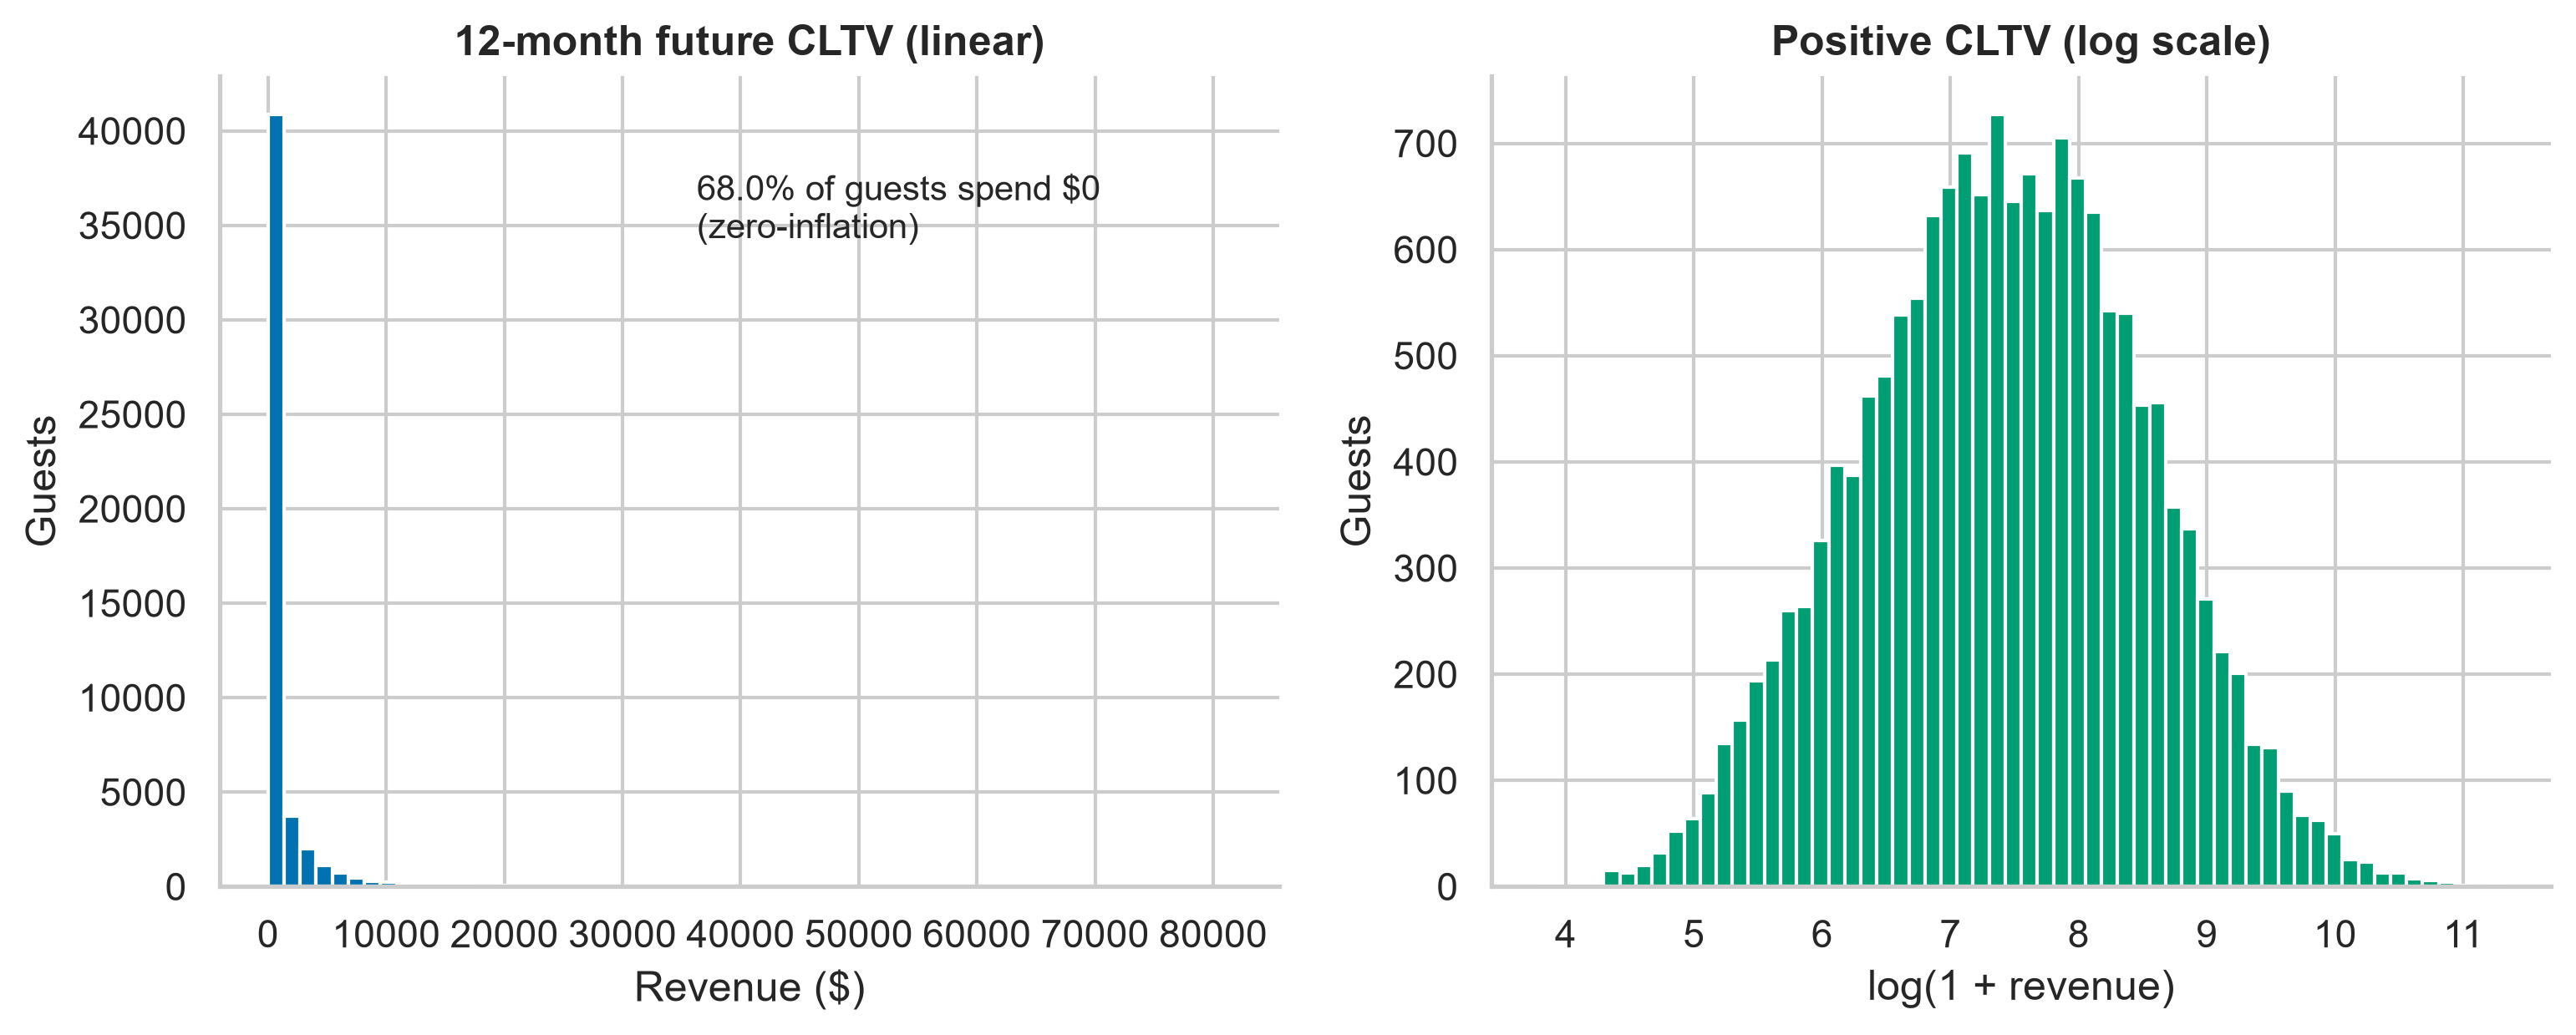

eda/spend_by_loyalty_tier.png


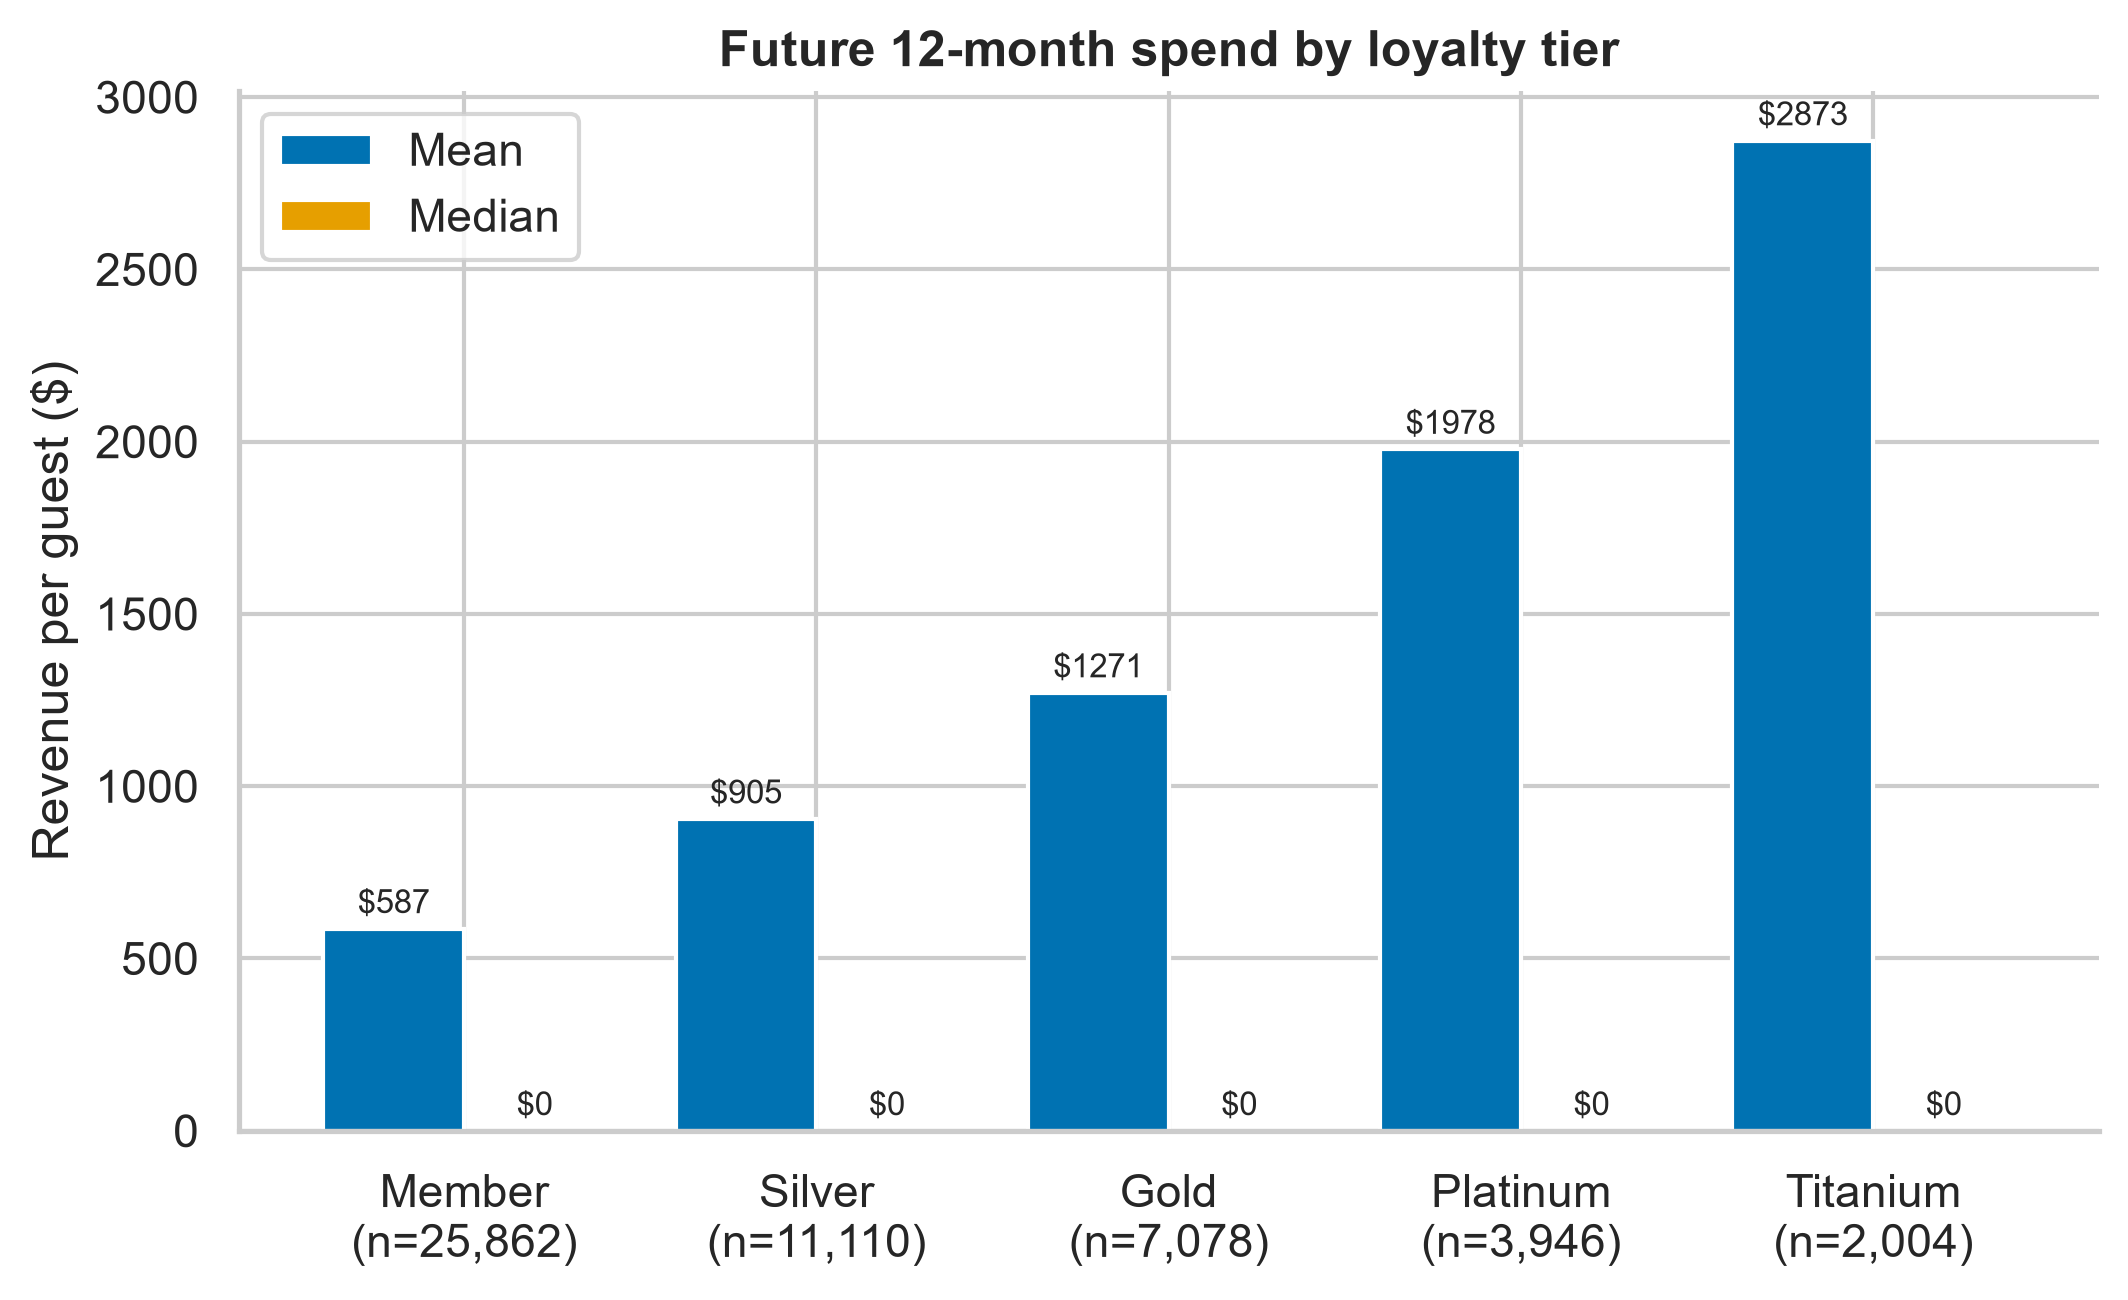

eda/leadtime_vs_adr.png


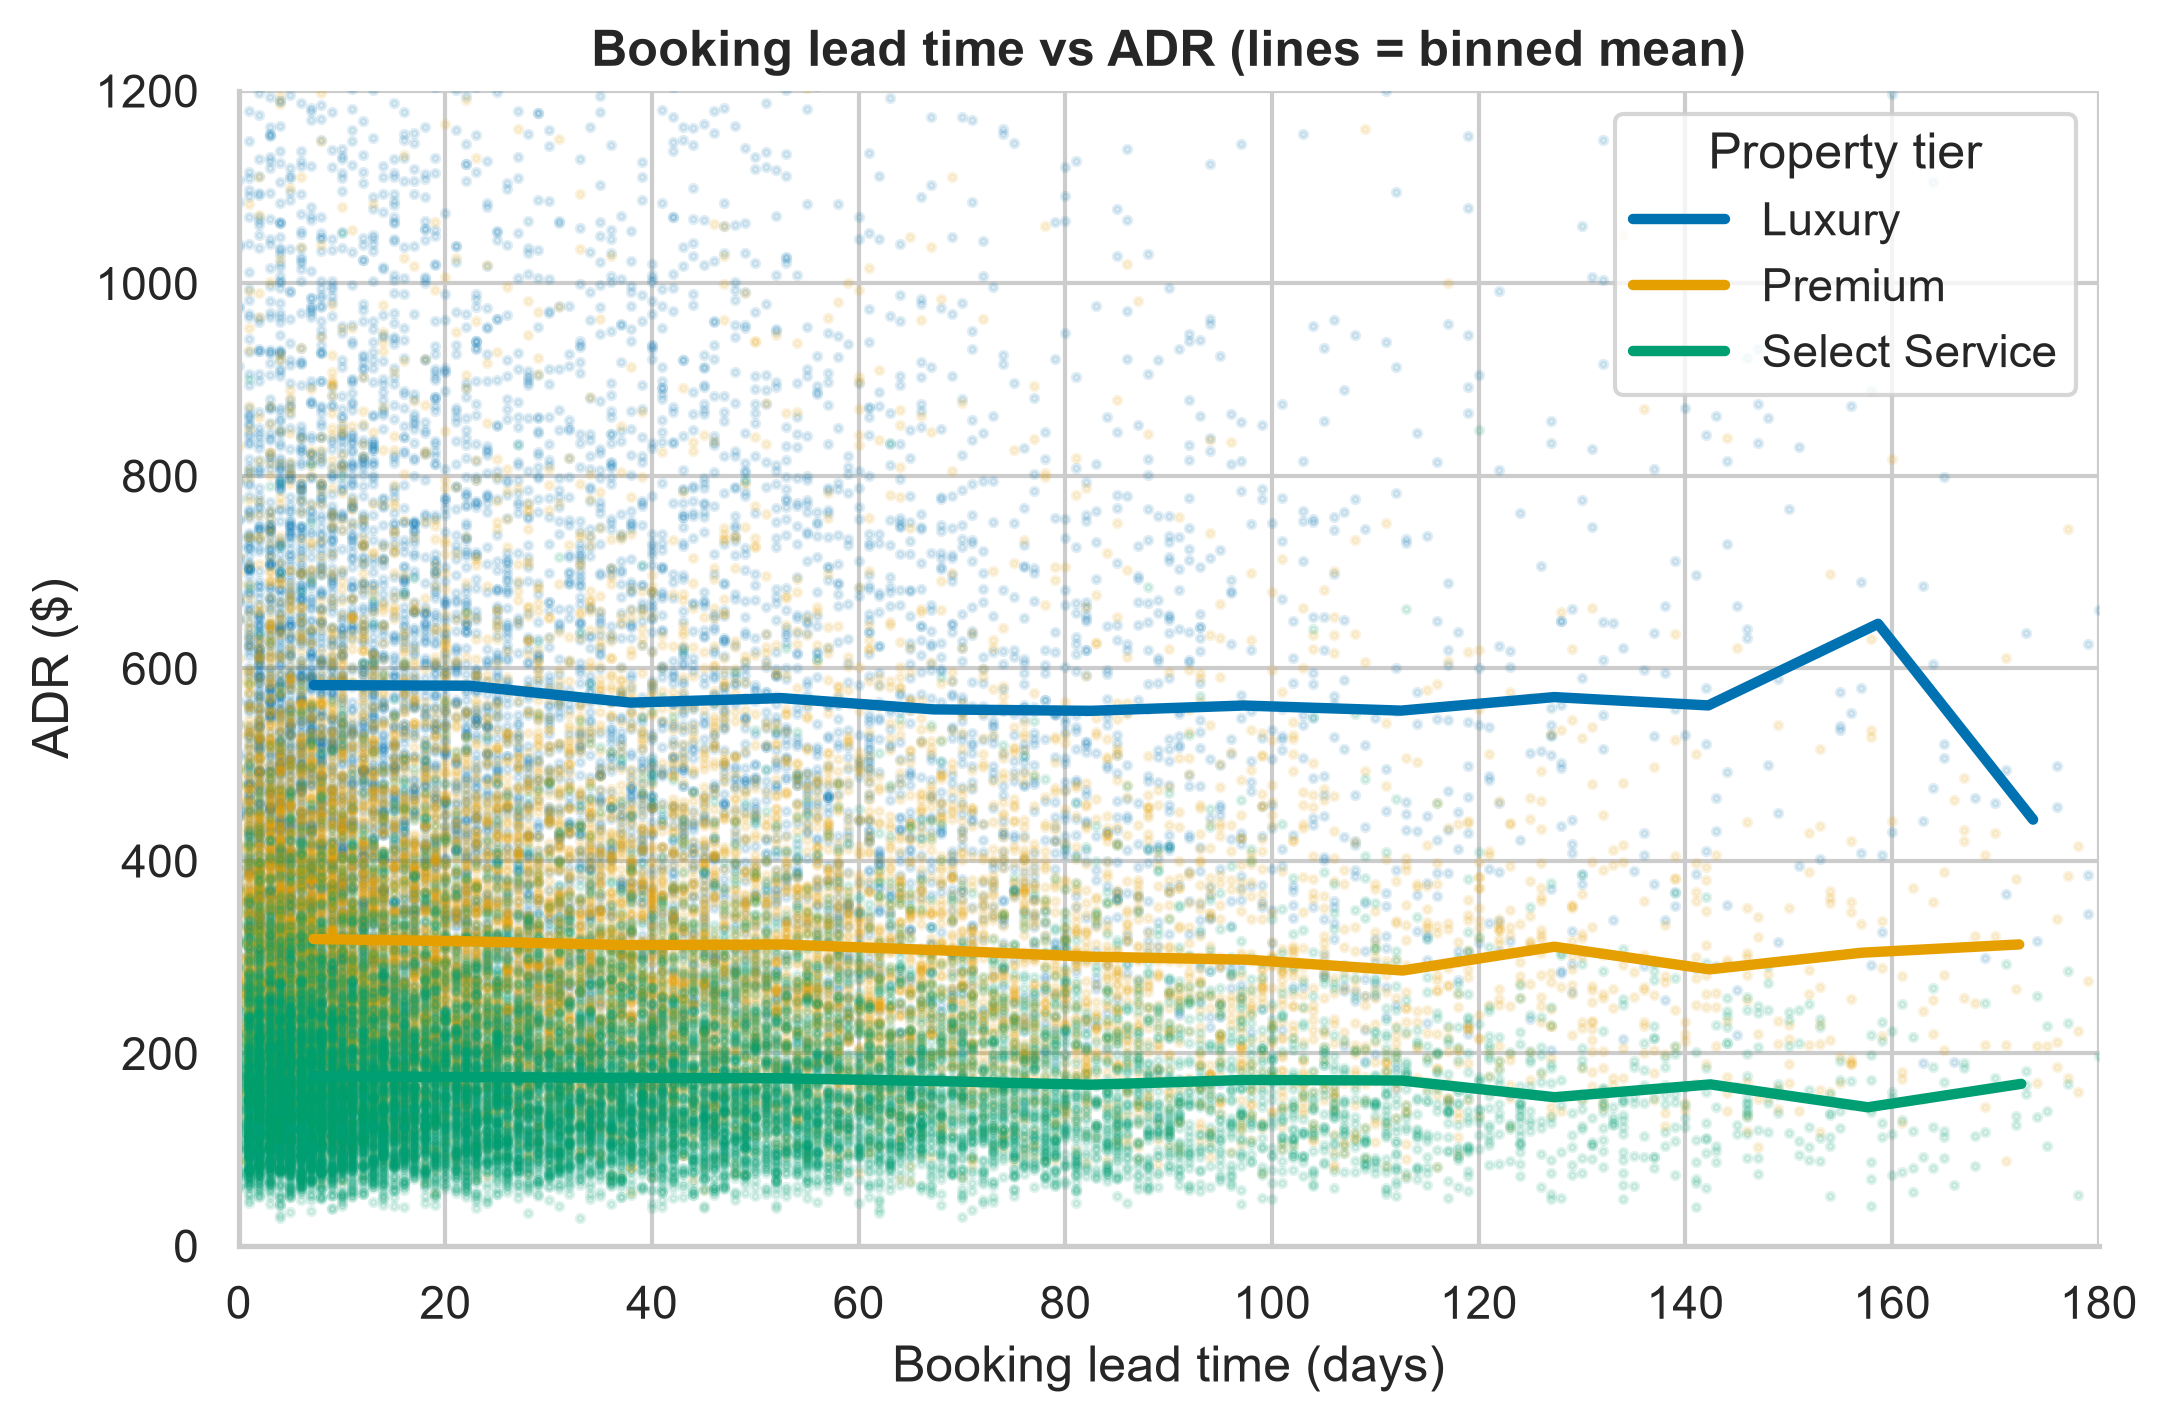

eda/retention_decay.png


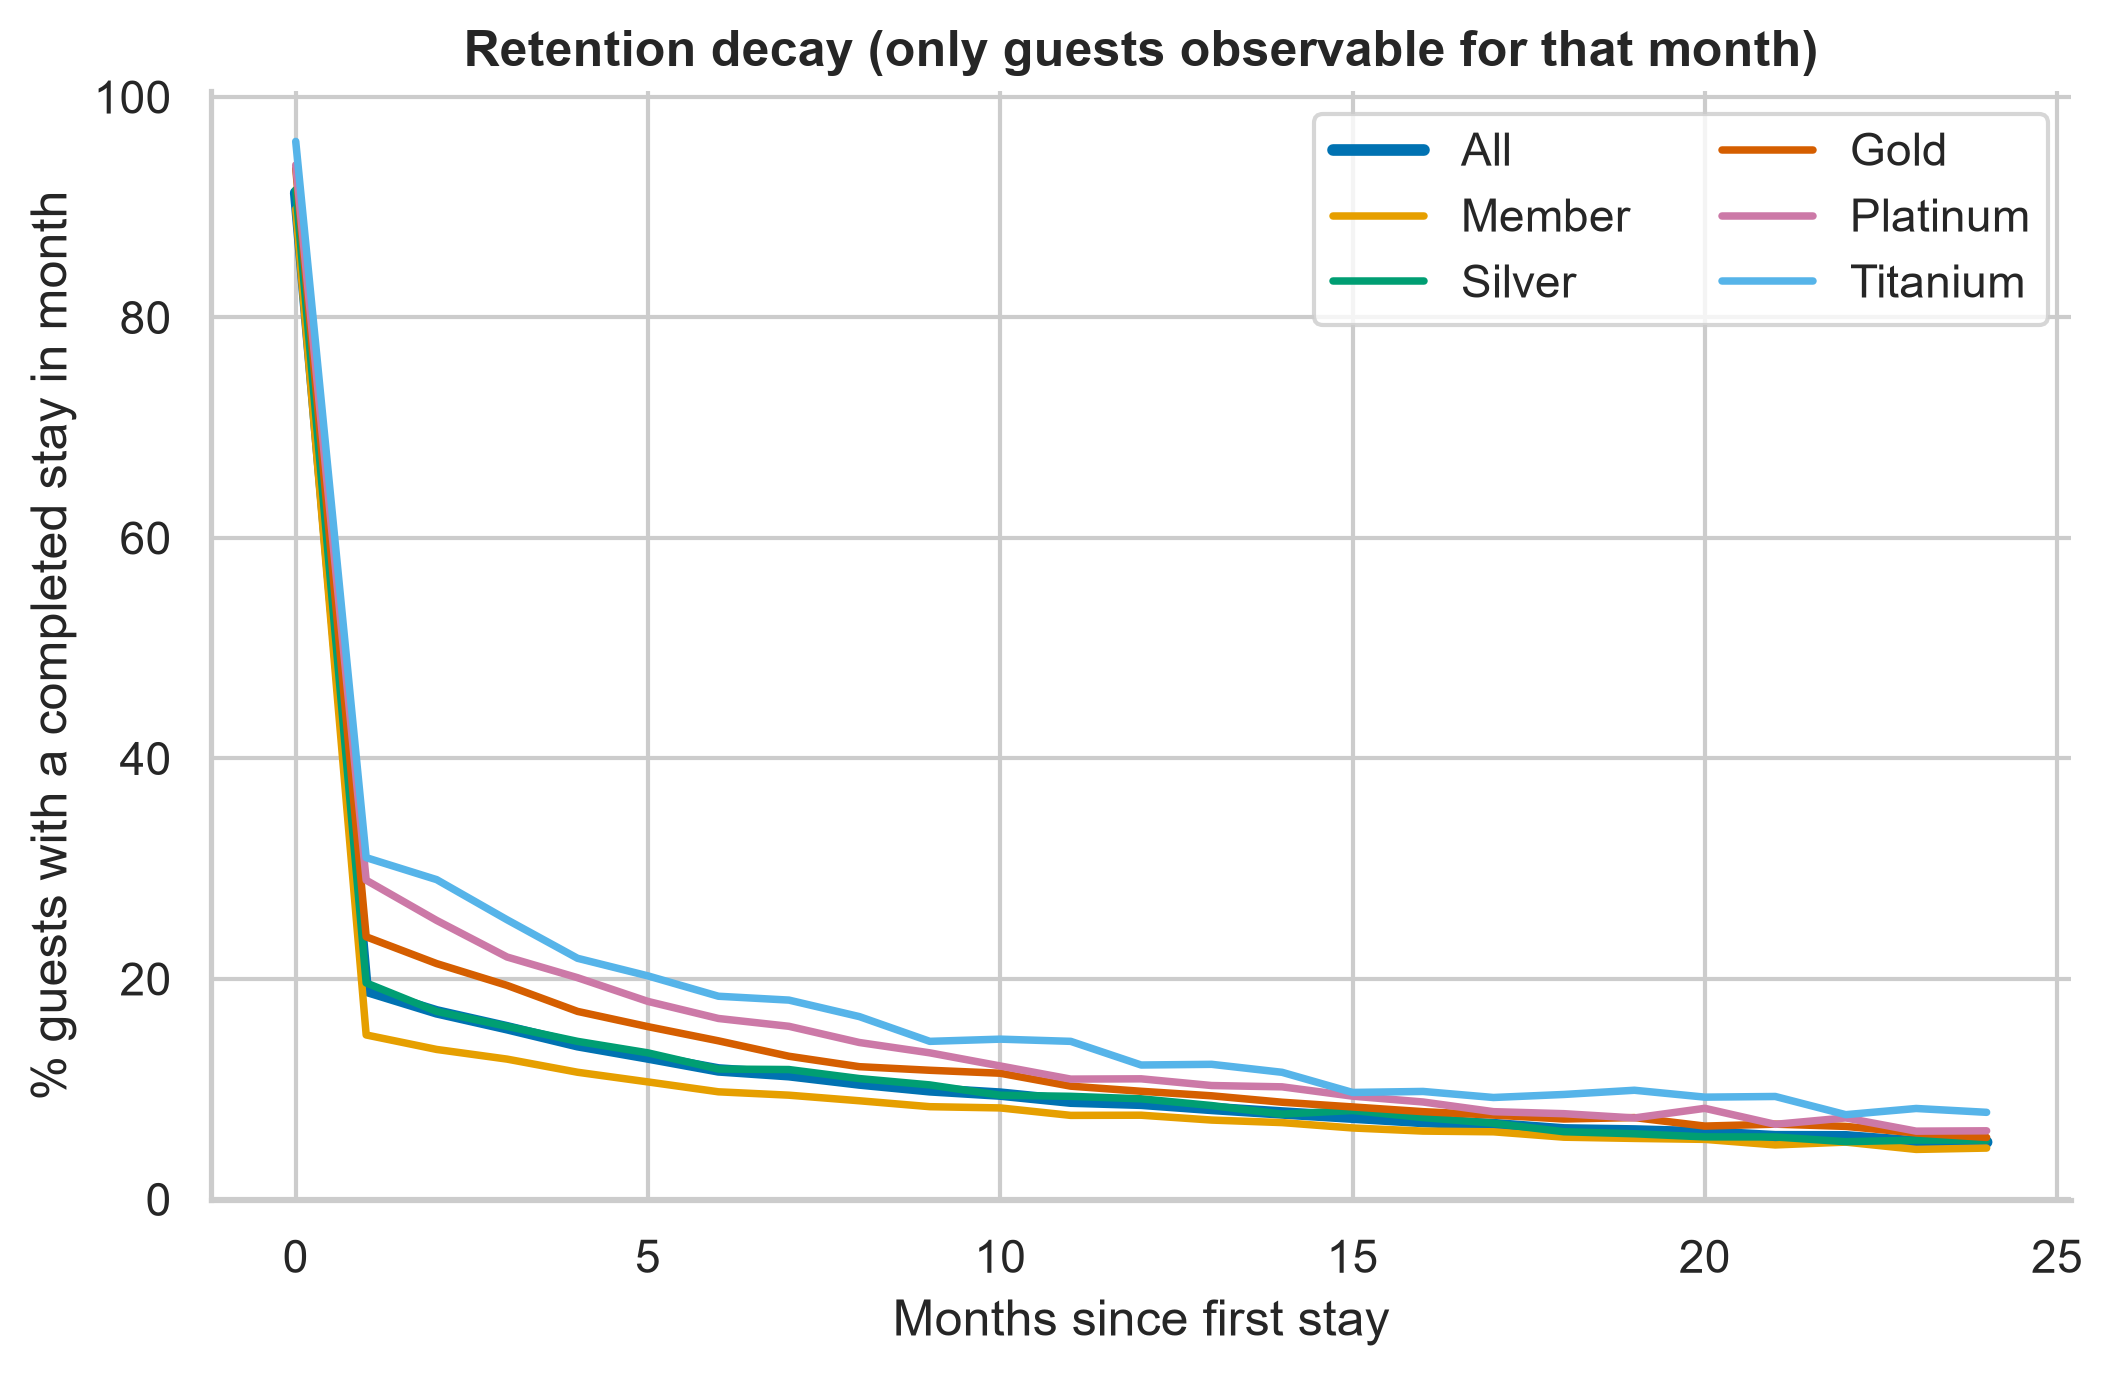

features/correlation_matrix.png


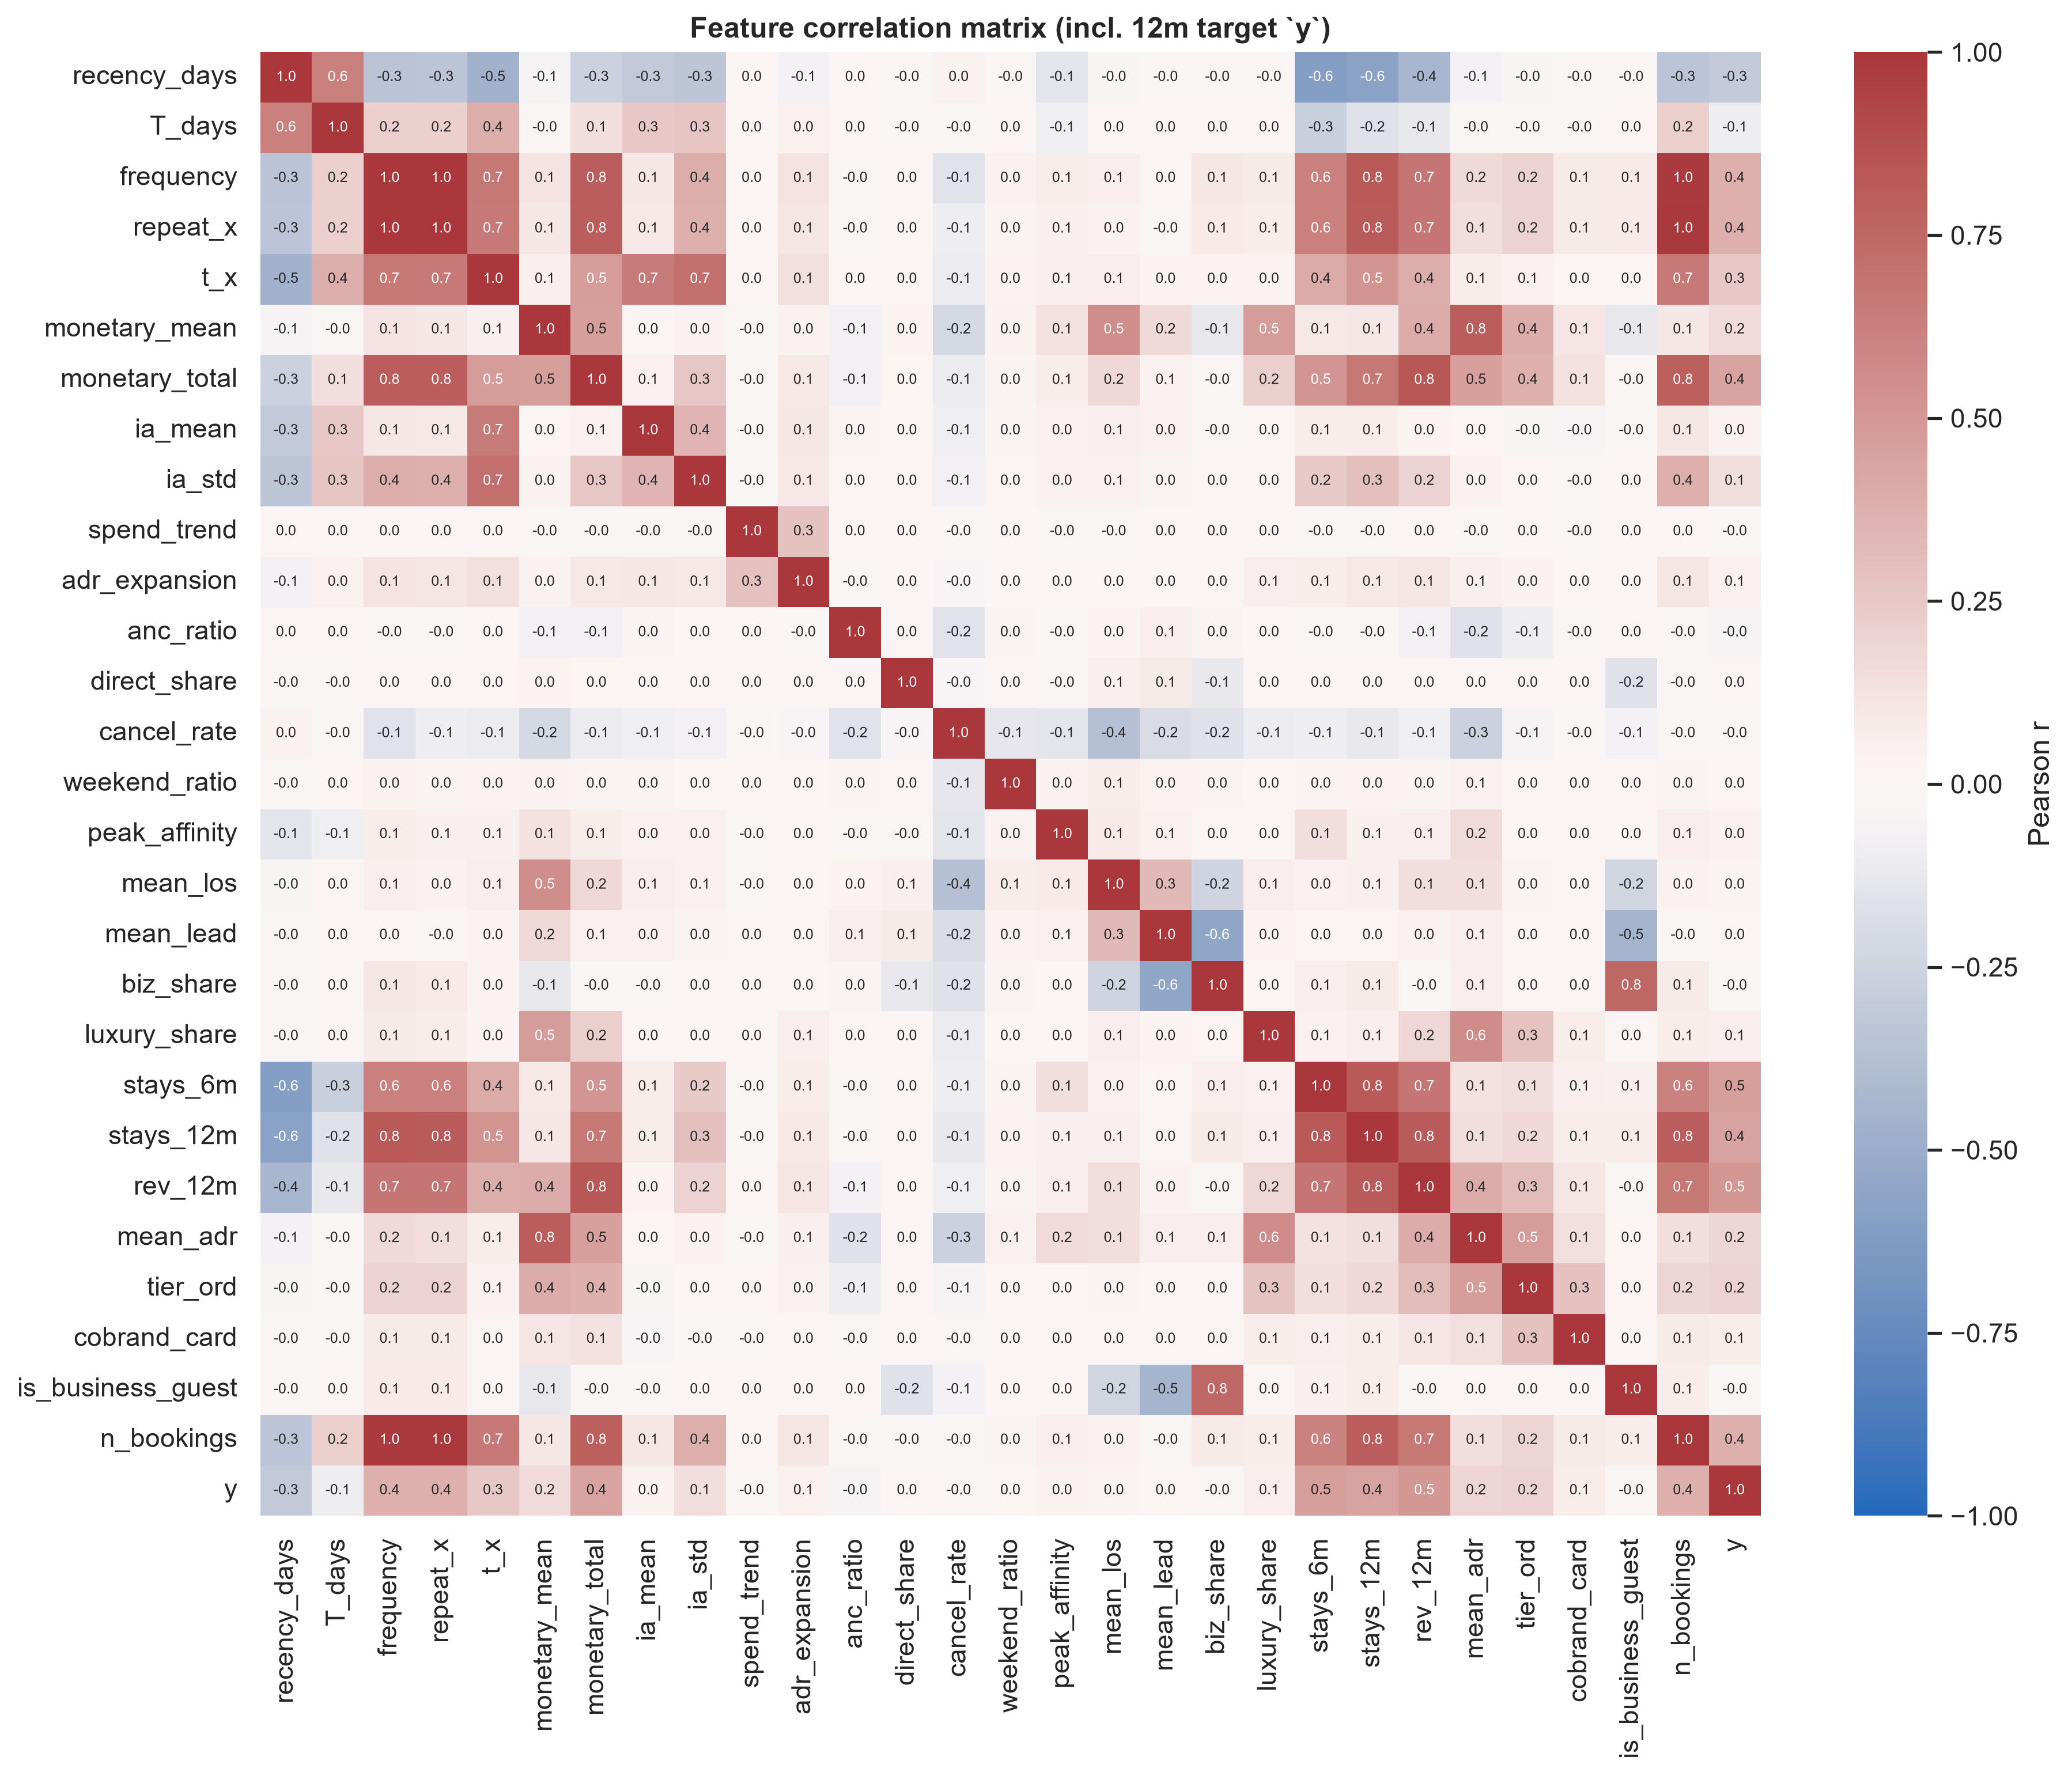

features/shap_beeswarm.png


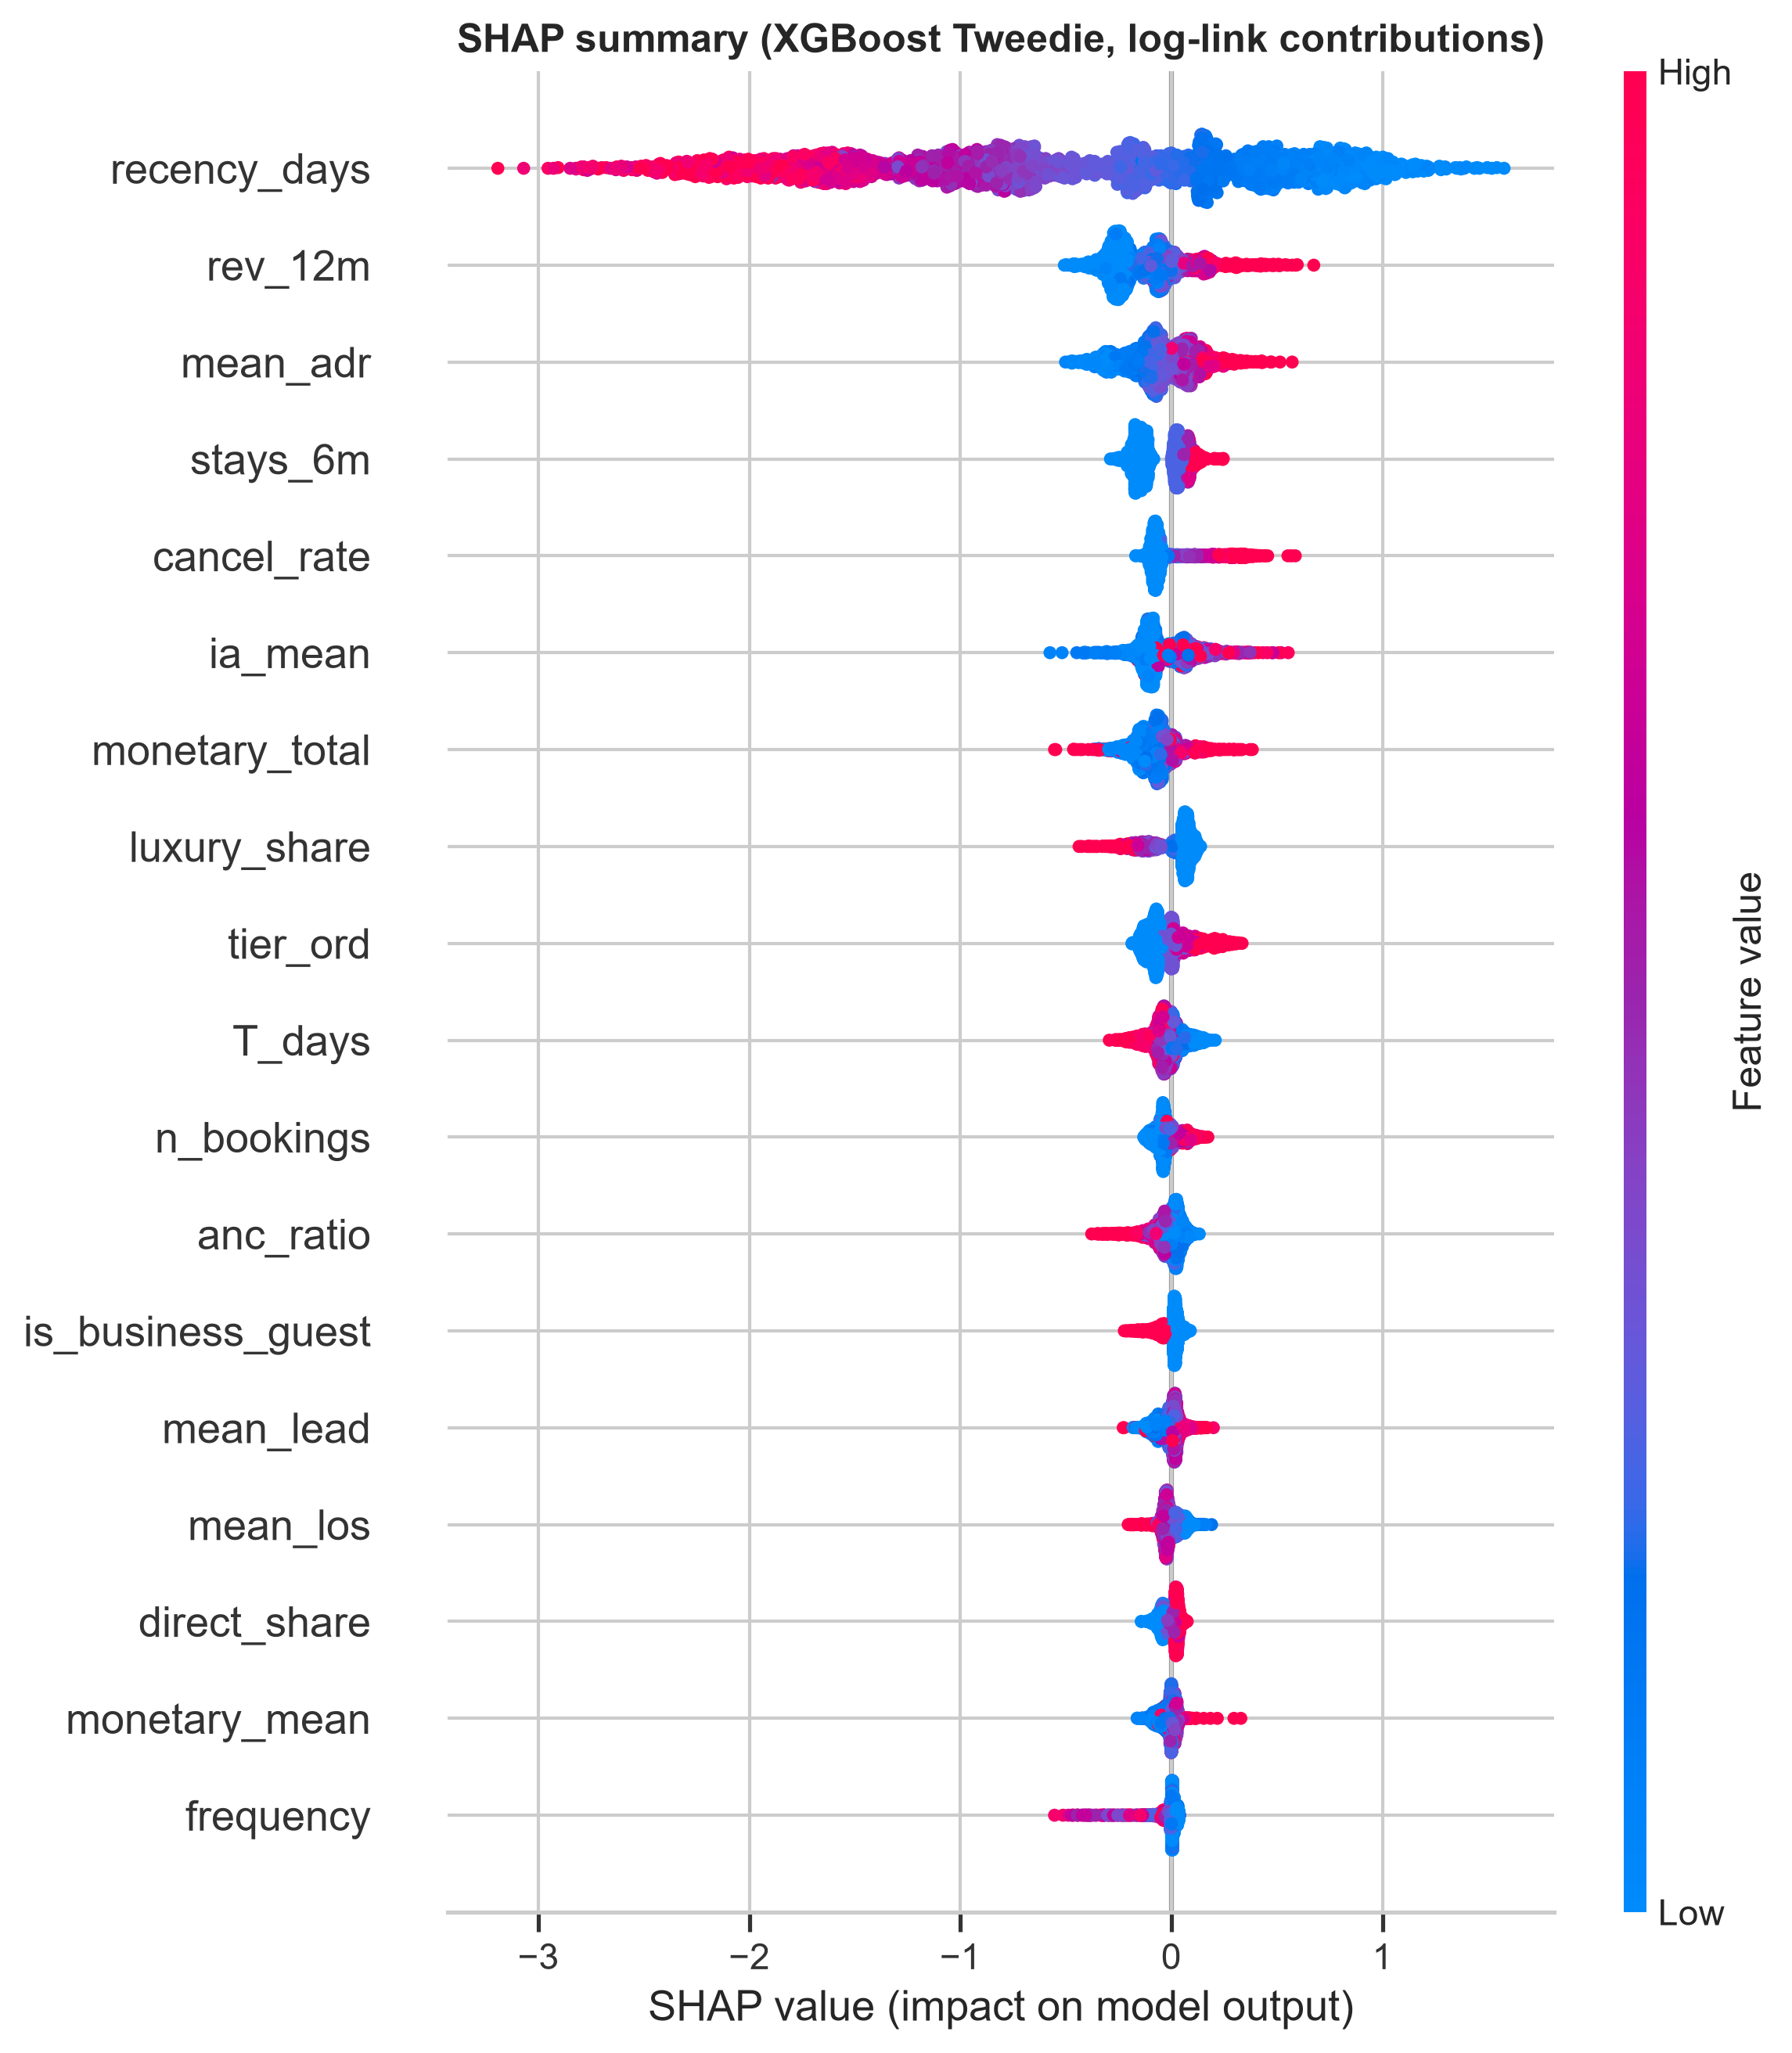

features/shap_importance_bar.png


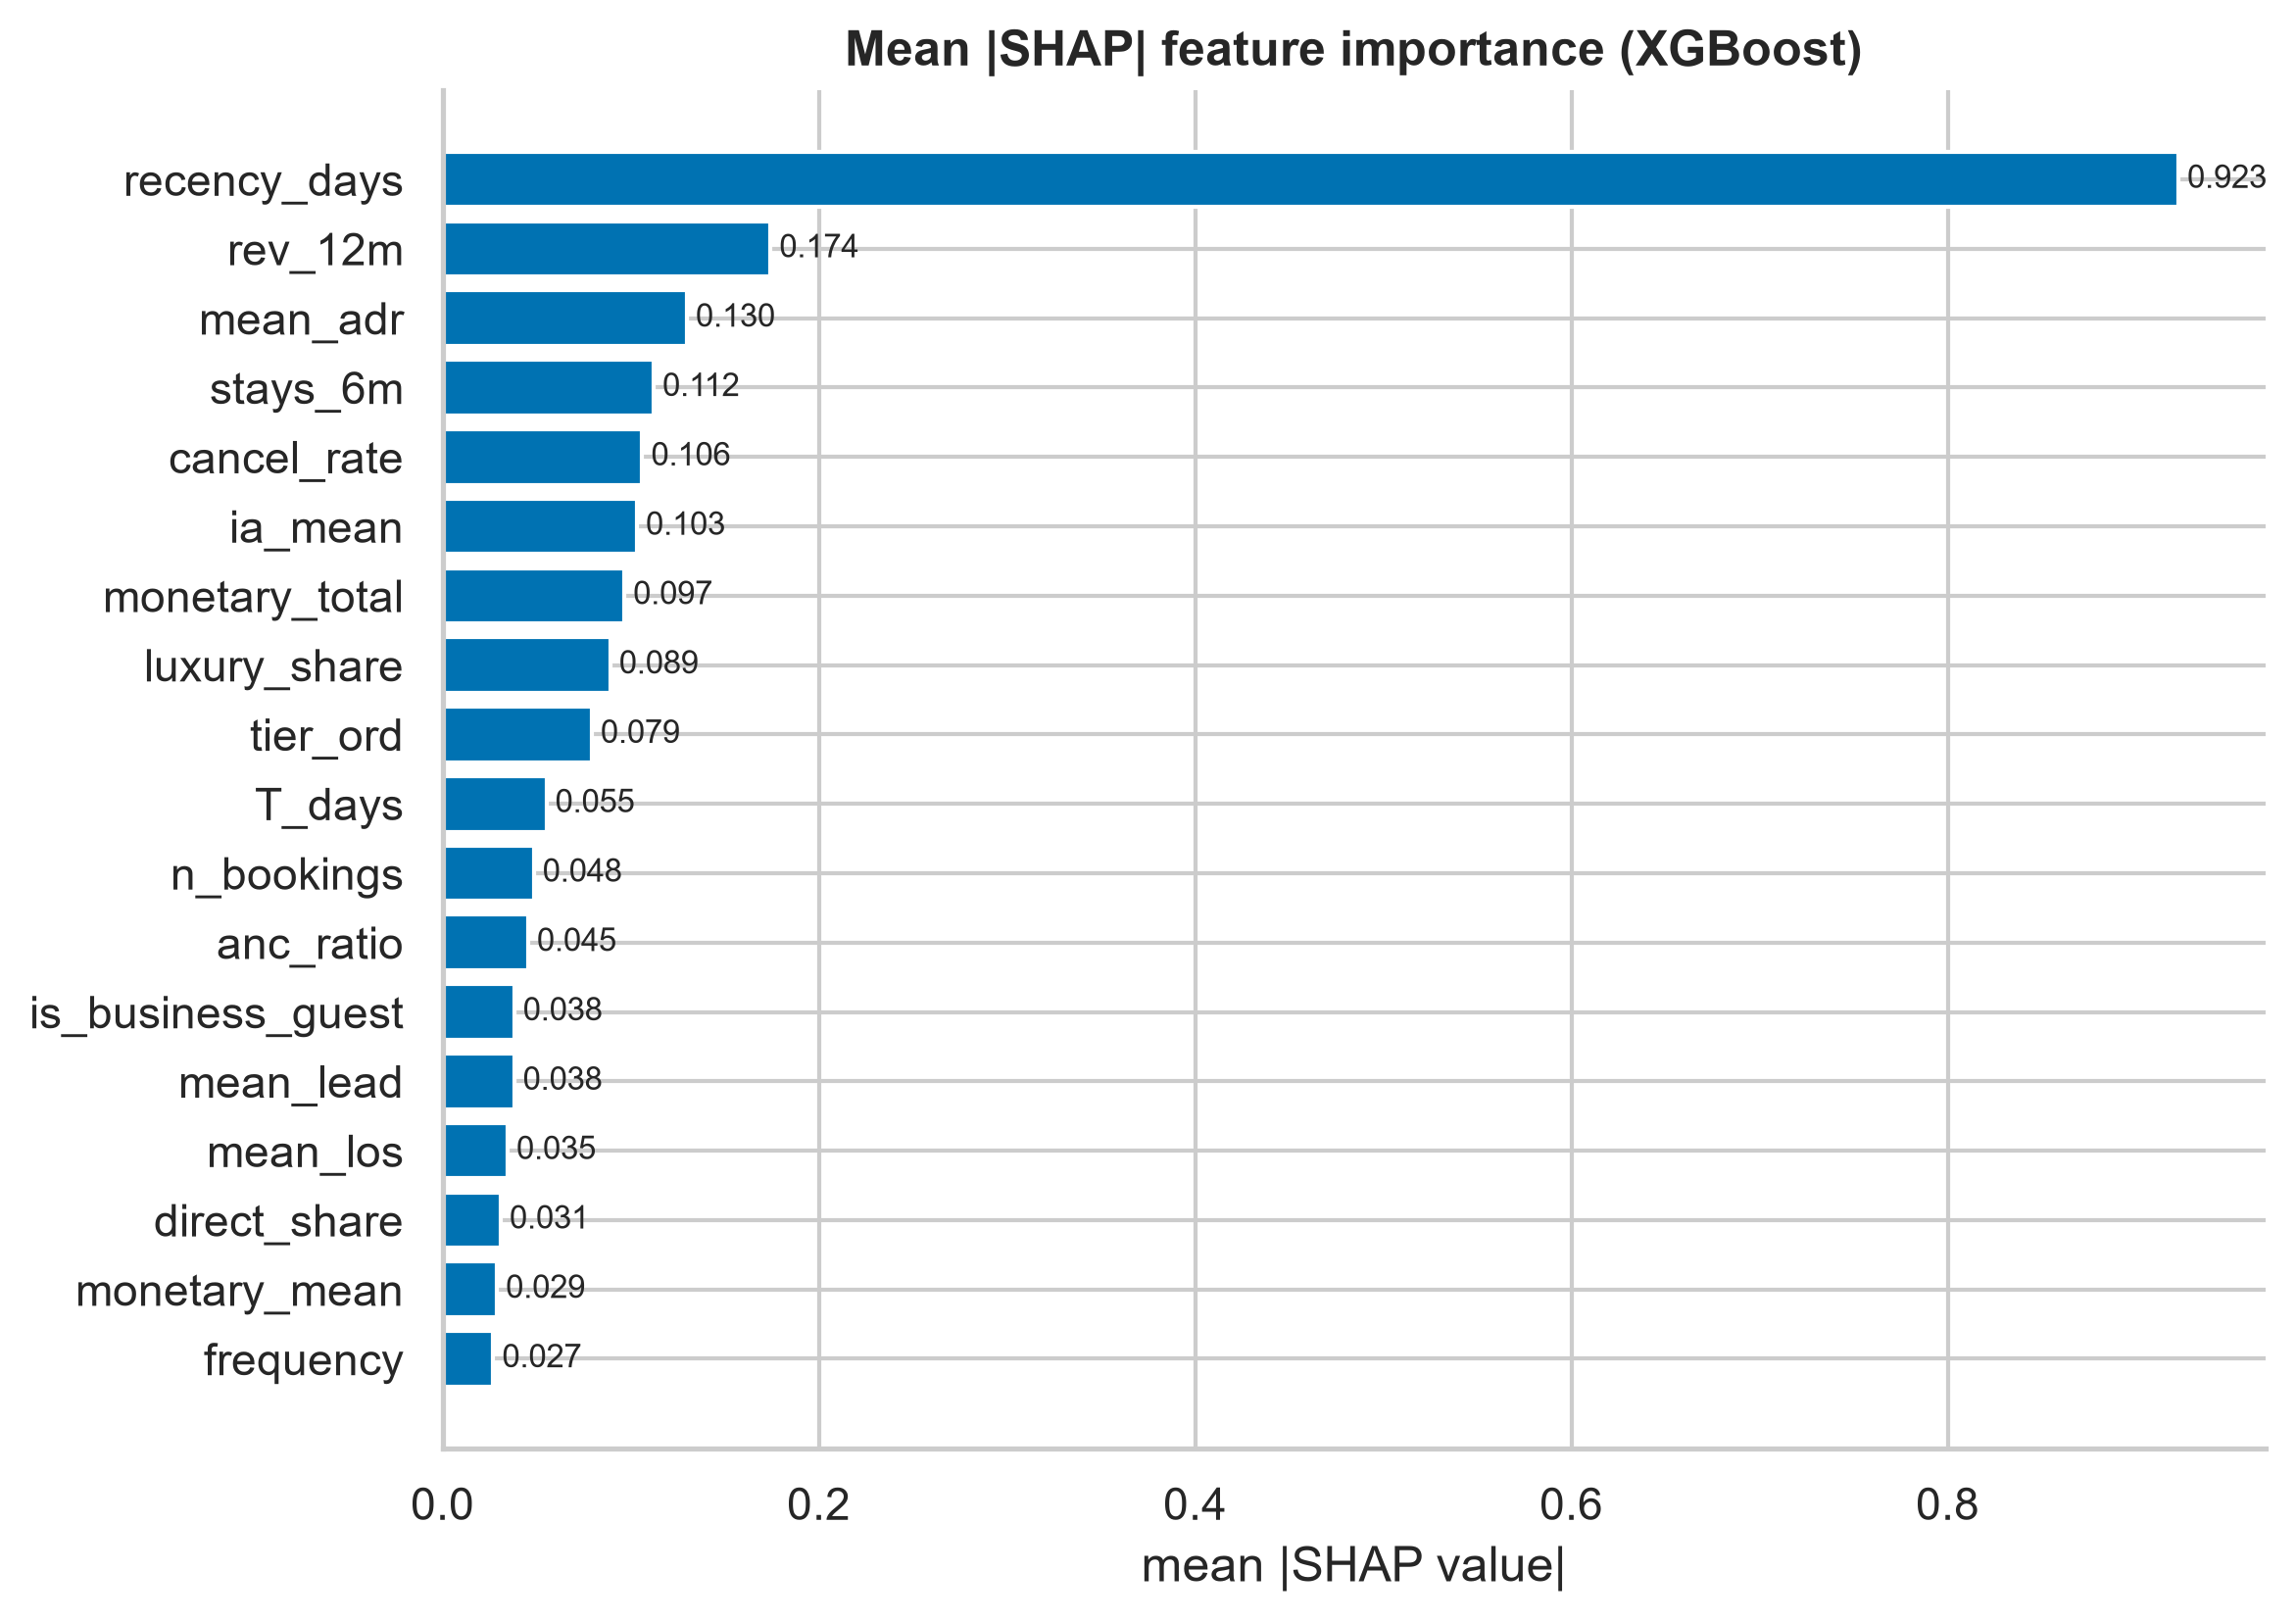

features/permutation_importance.png


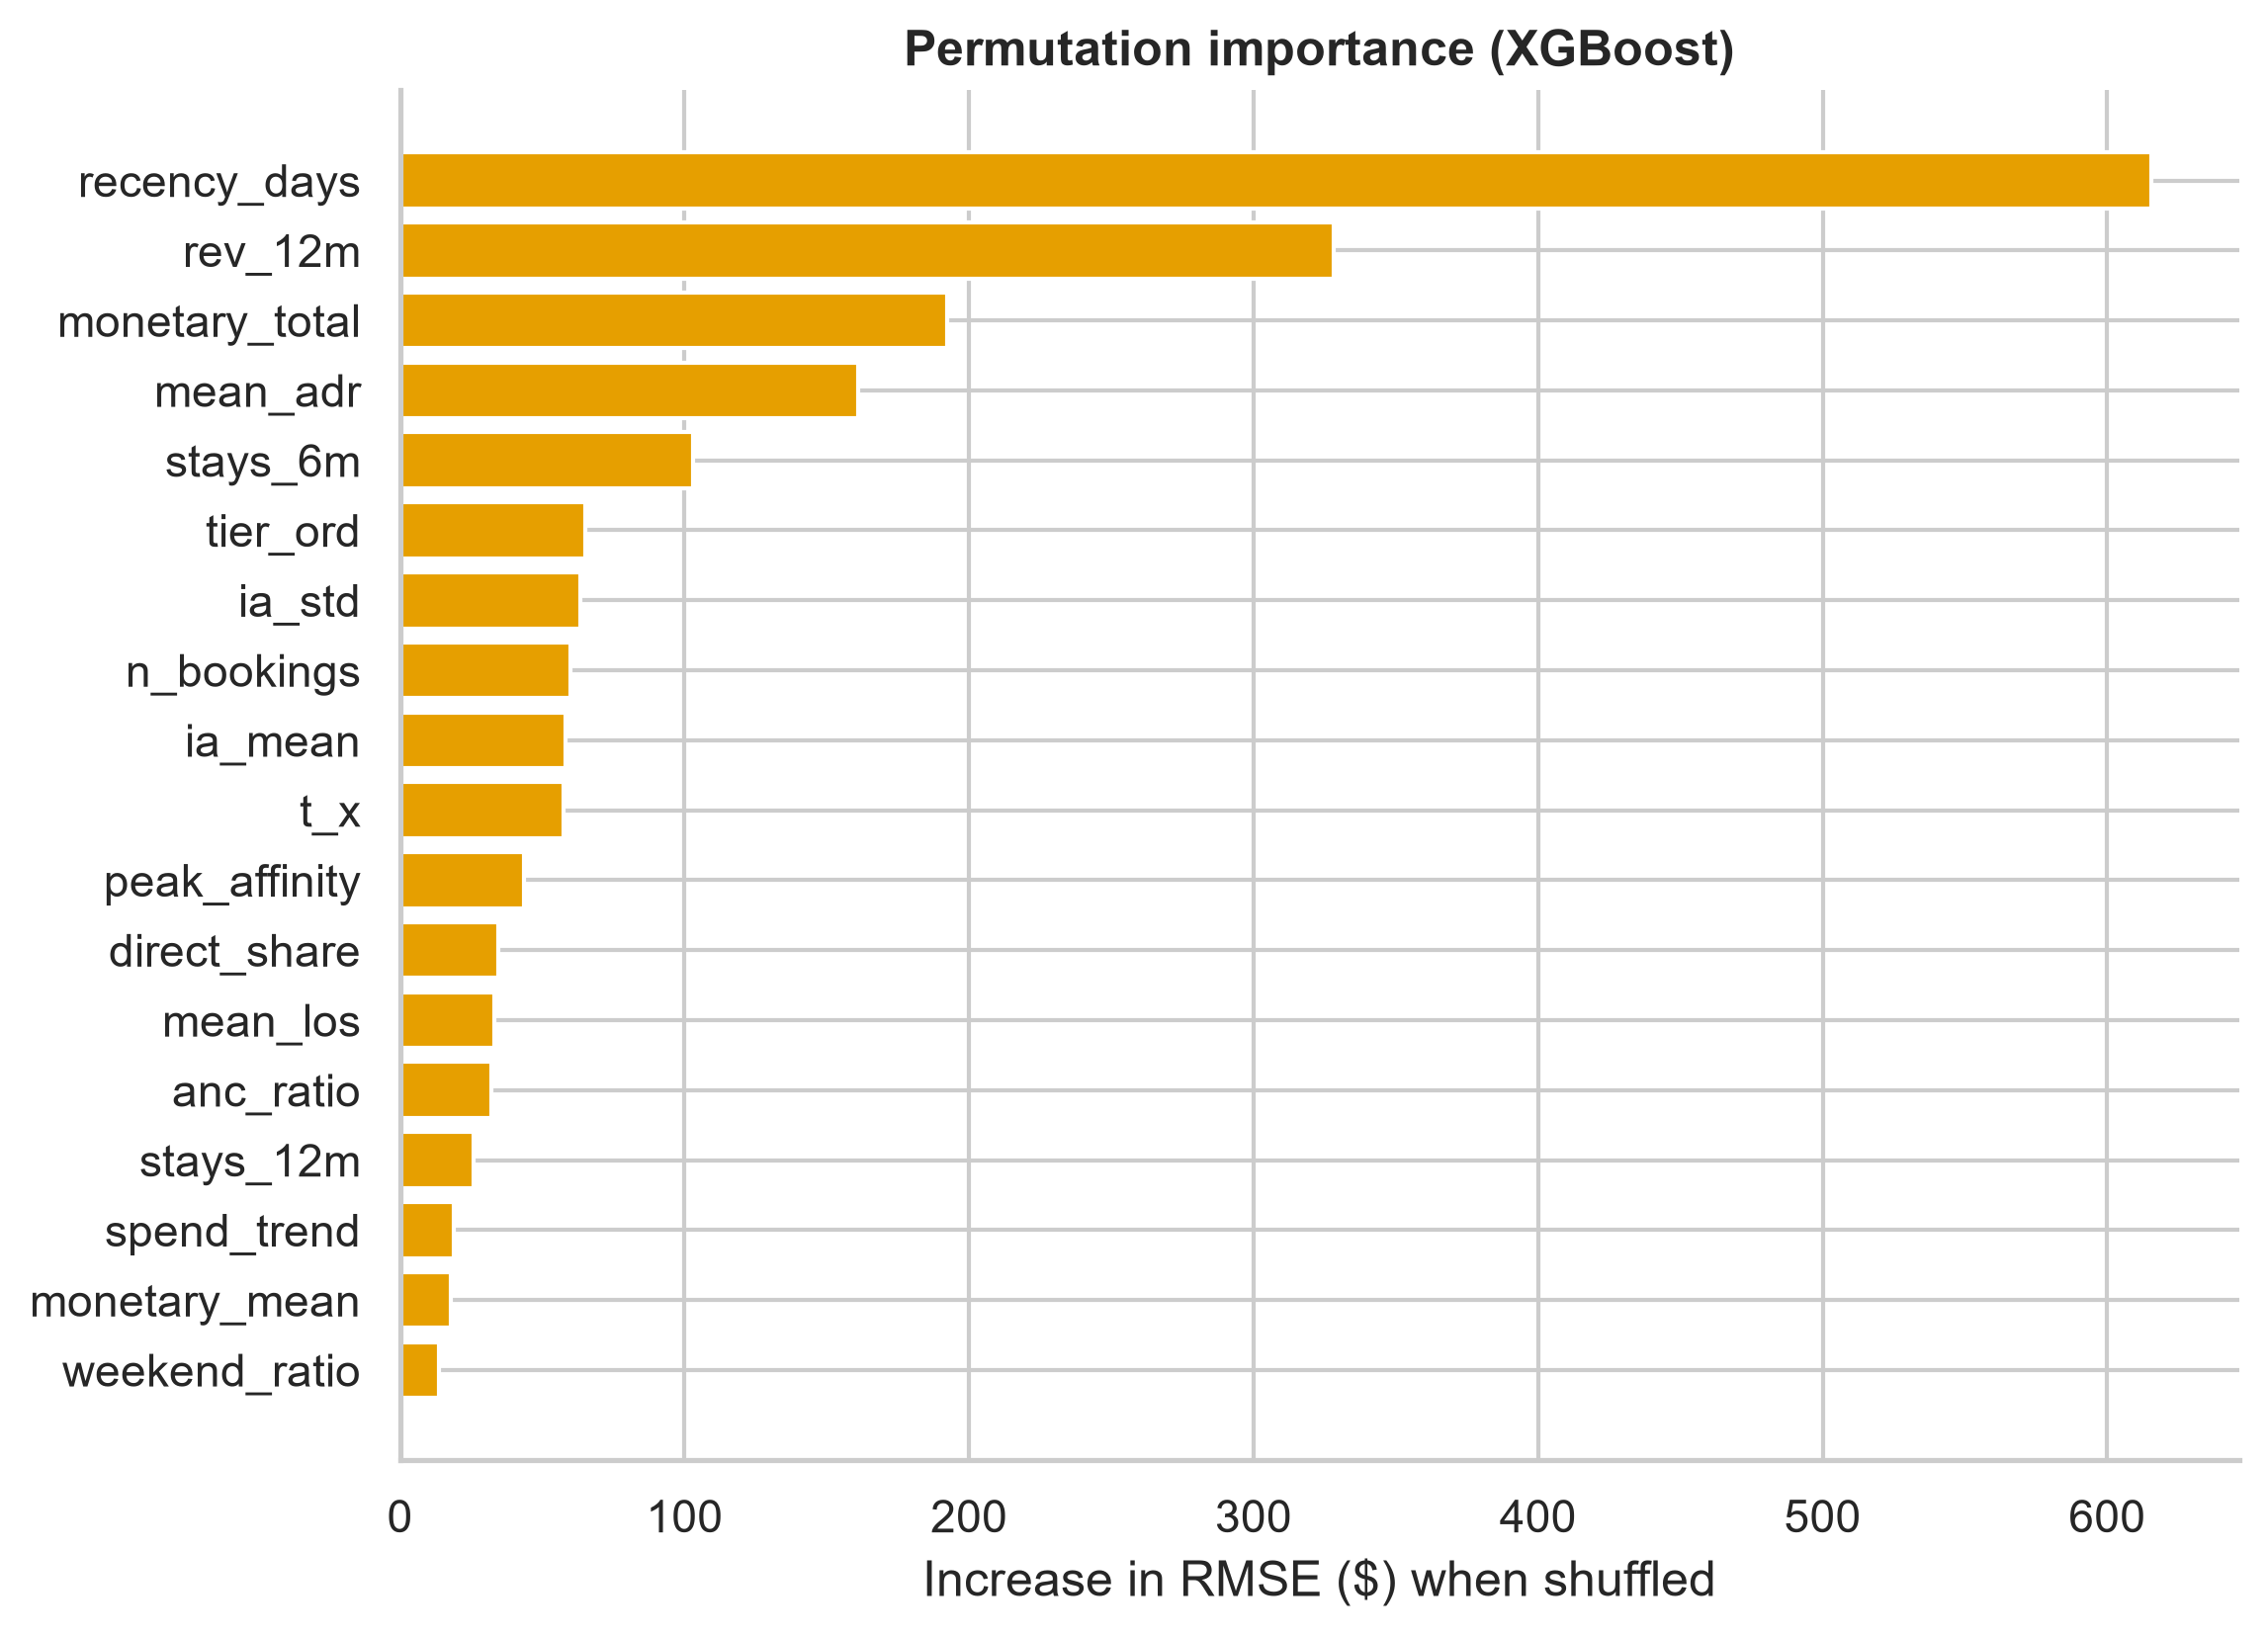

features/sequence_attention_heatmap.png


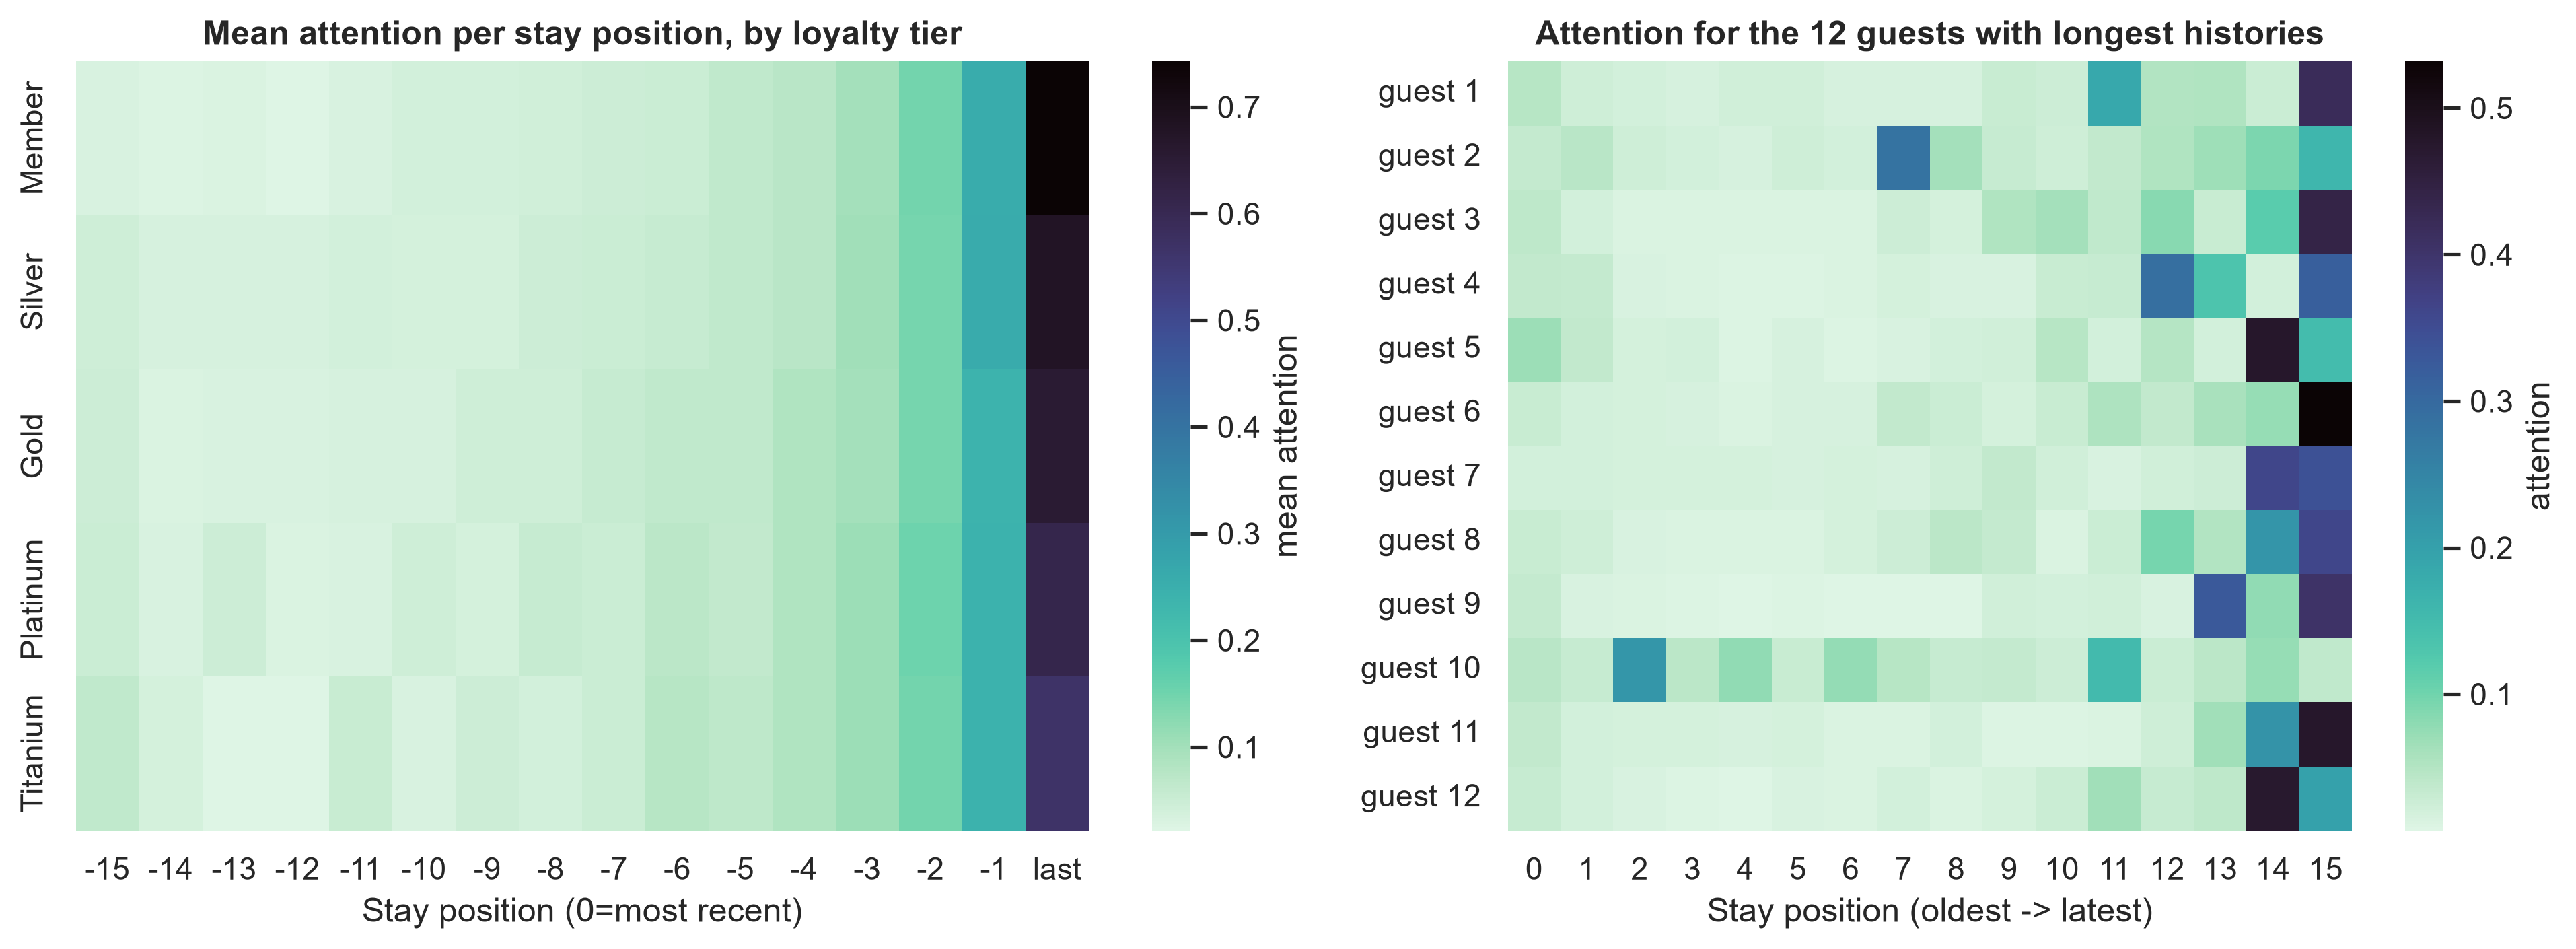

training_loss/training_validation_loss_all_models.png


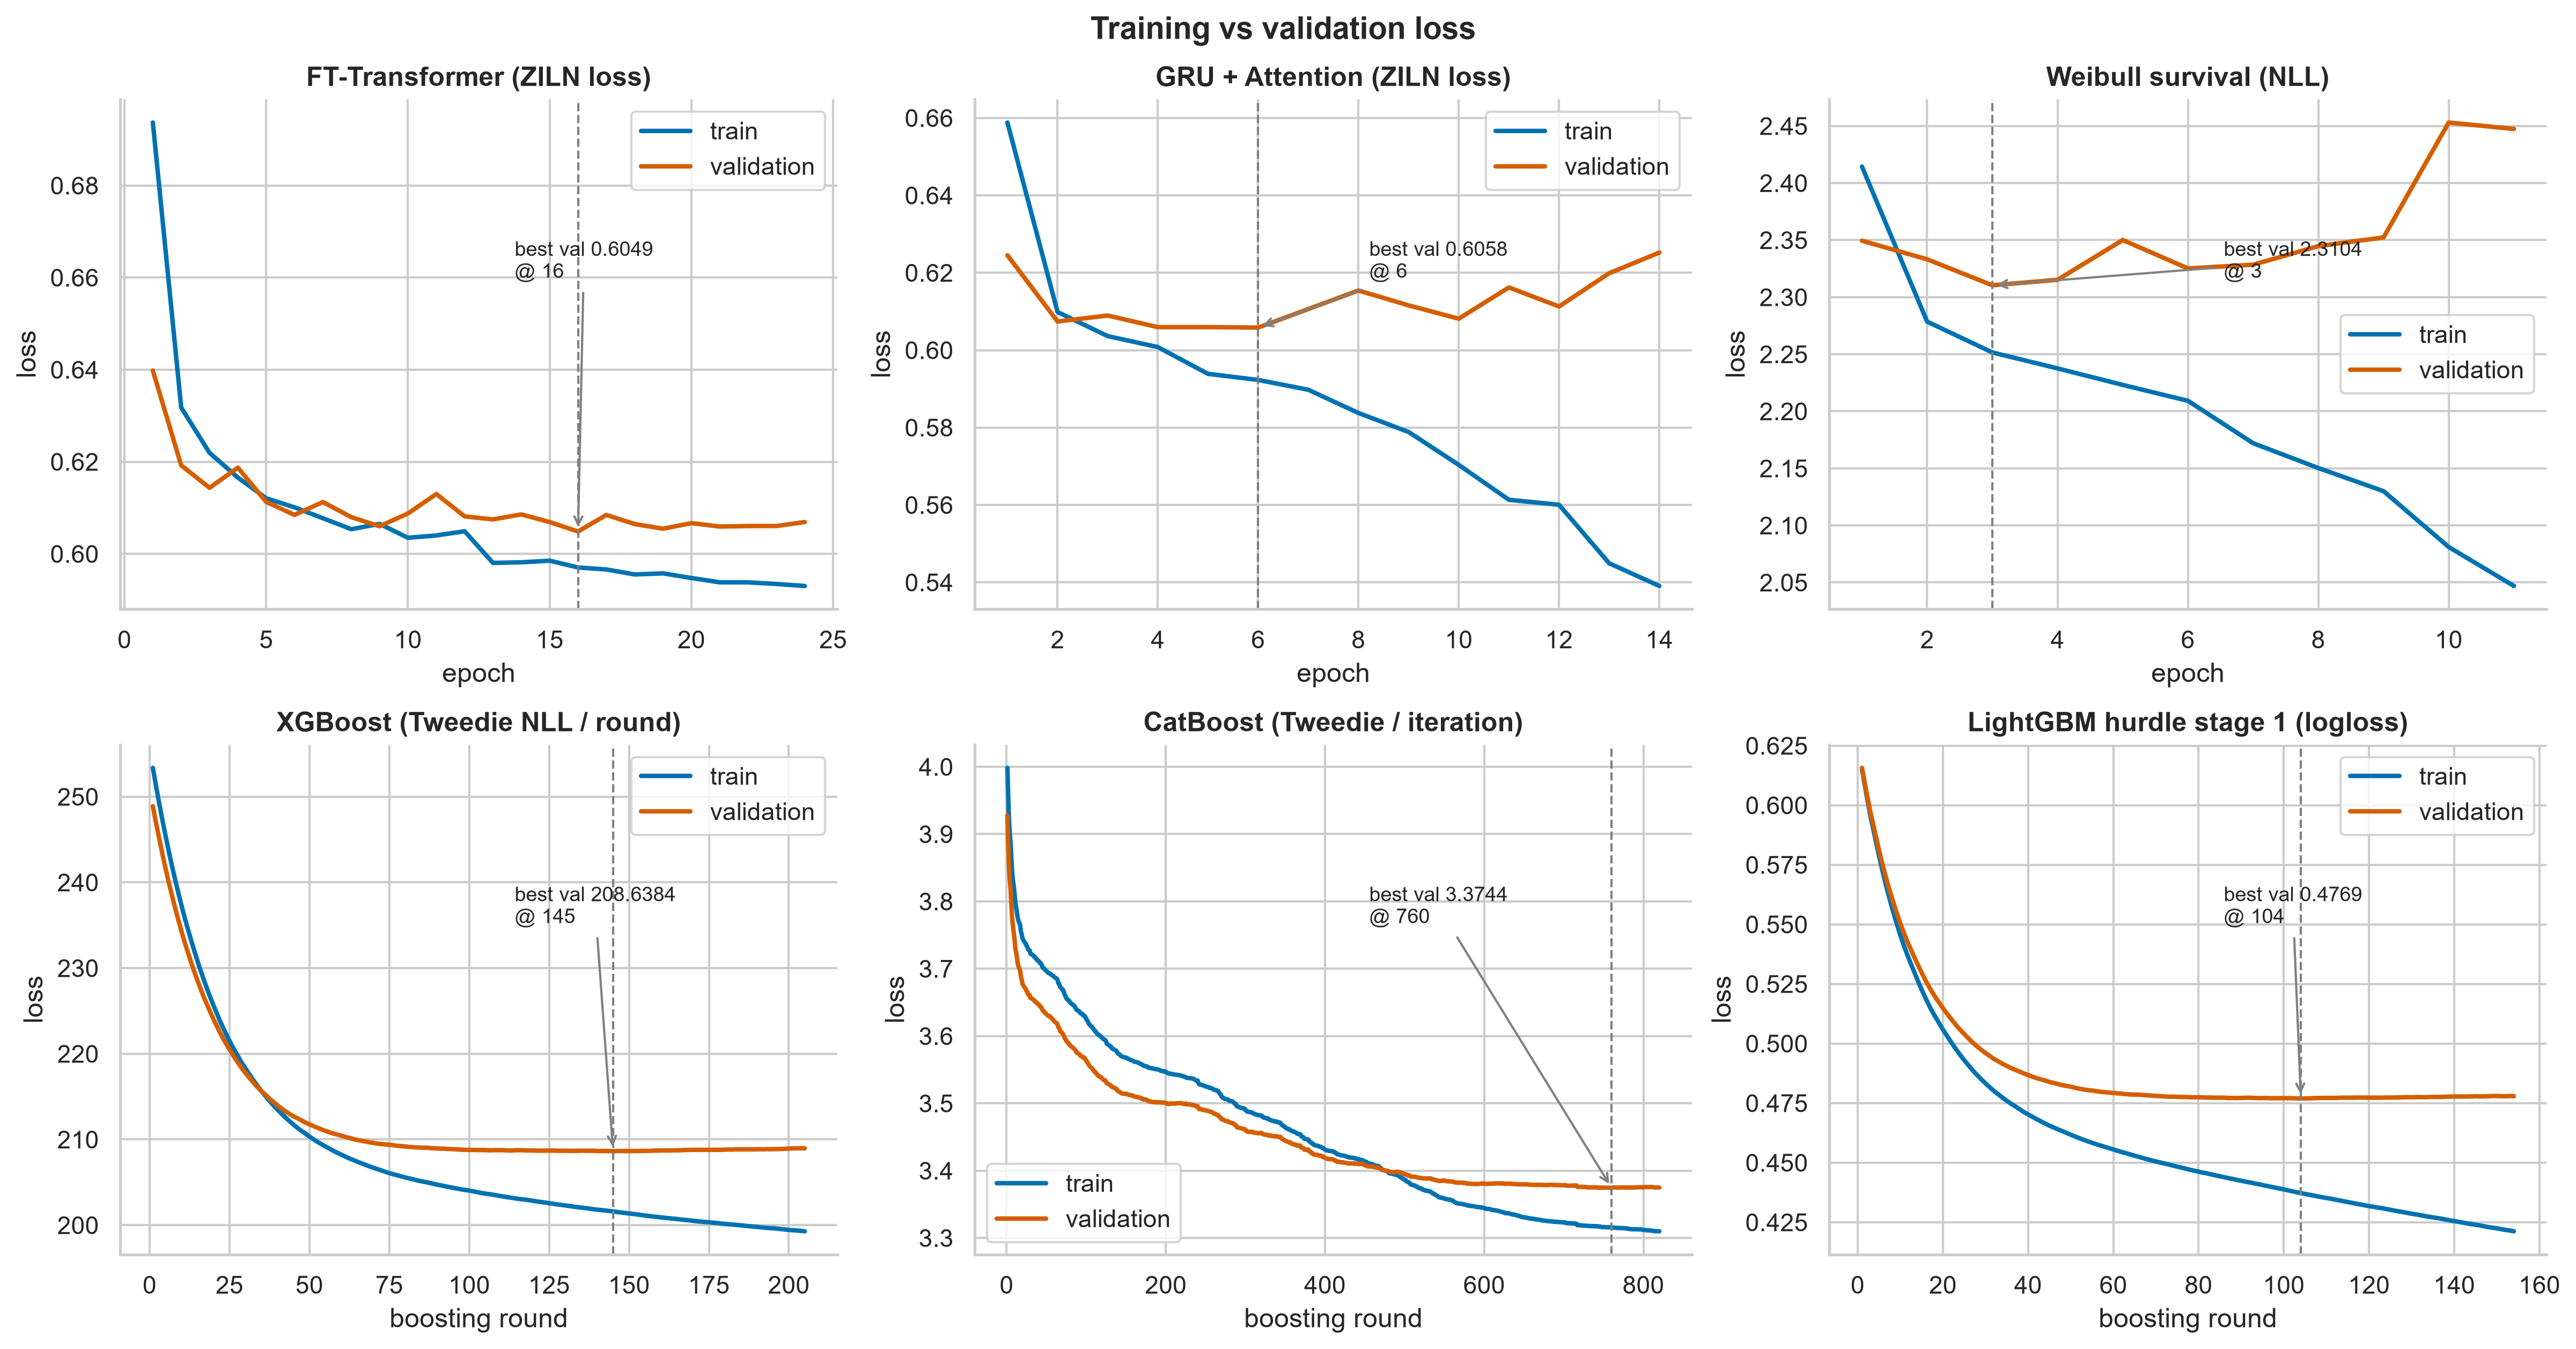

comparisons/model_comparison_metrics.png


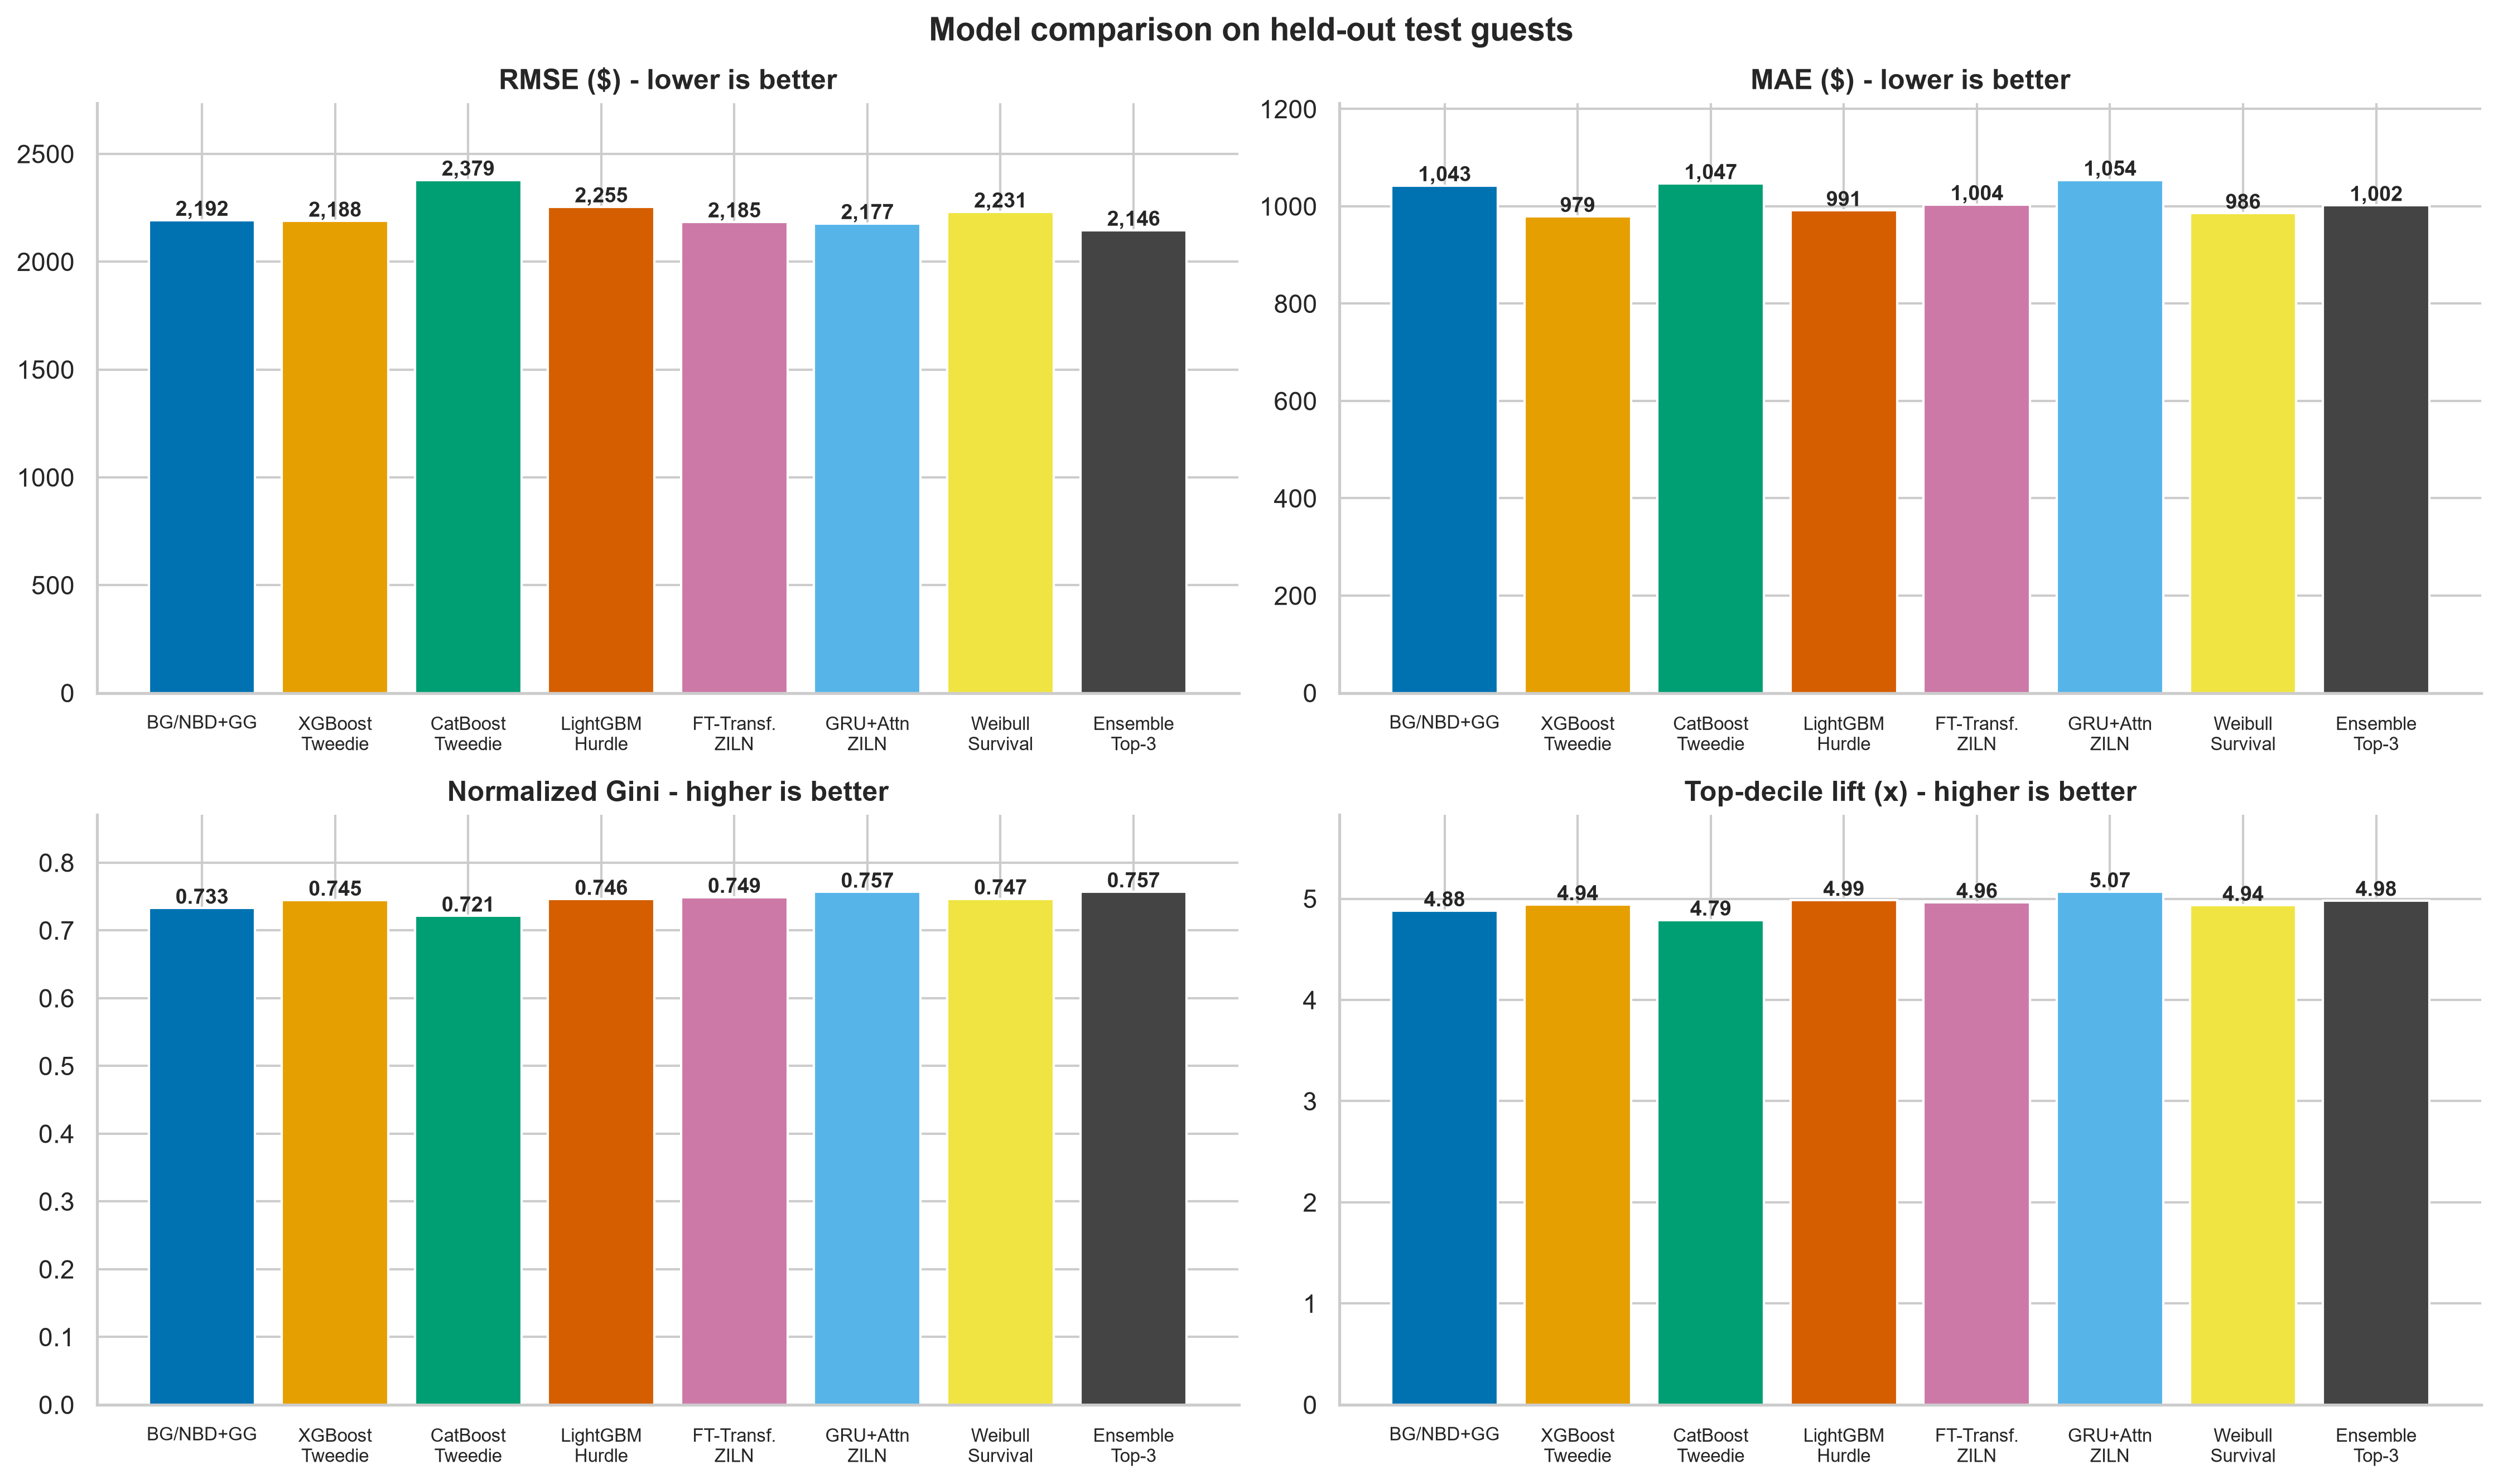

comparisons/model_comparison_secondary.png


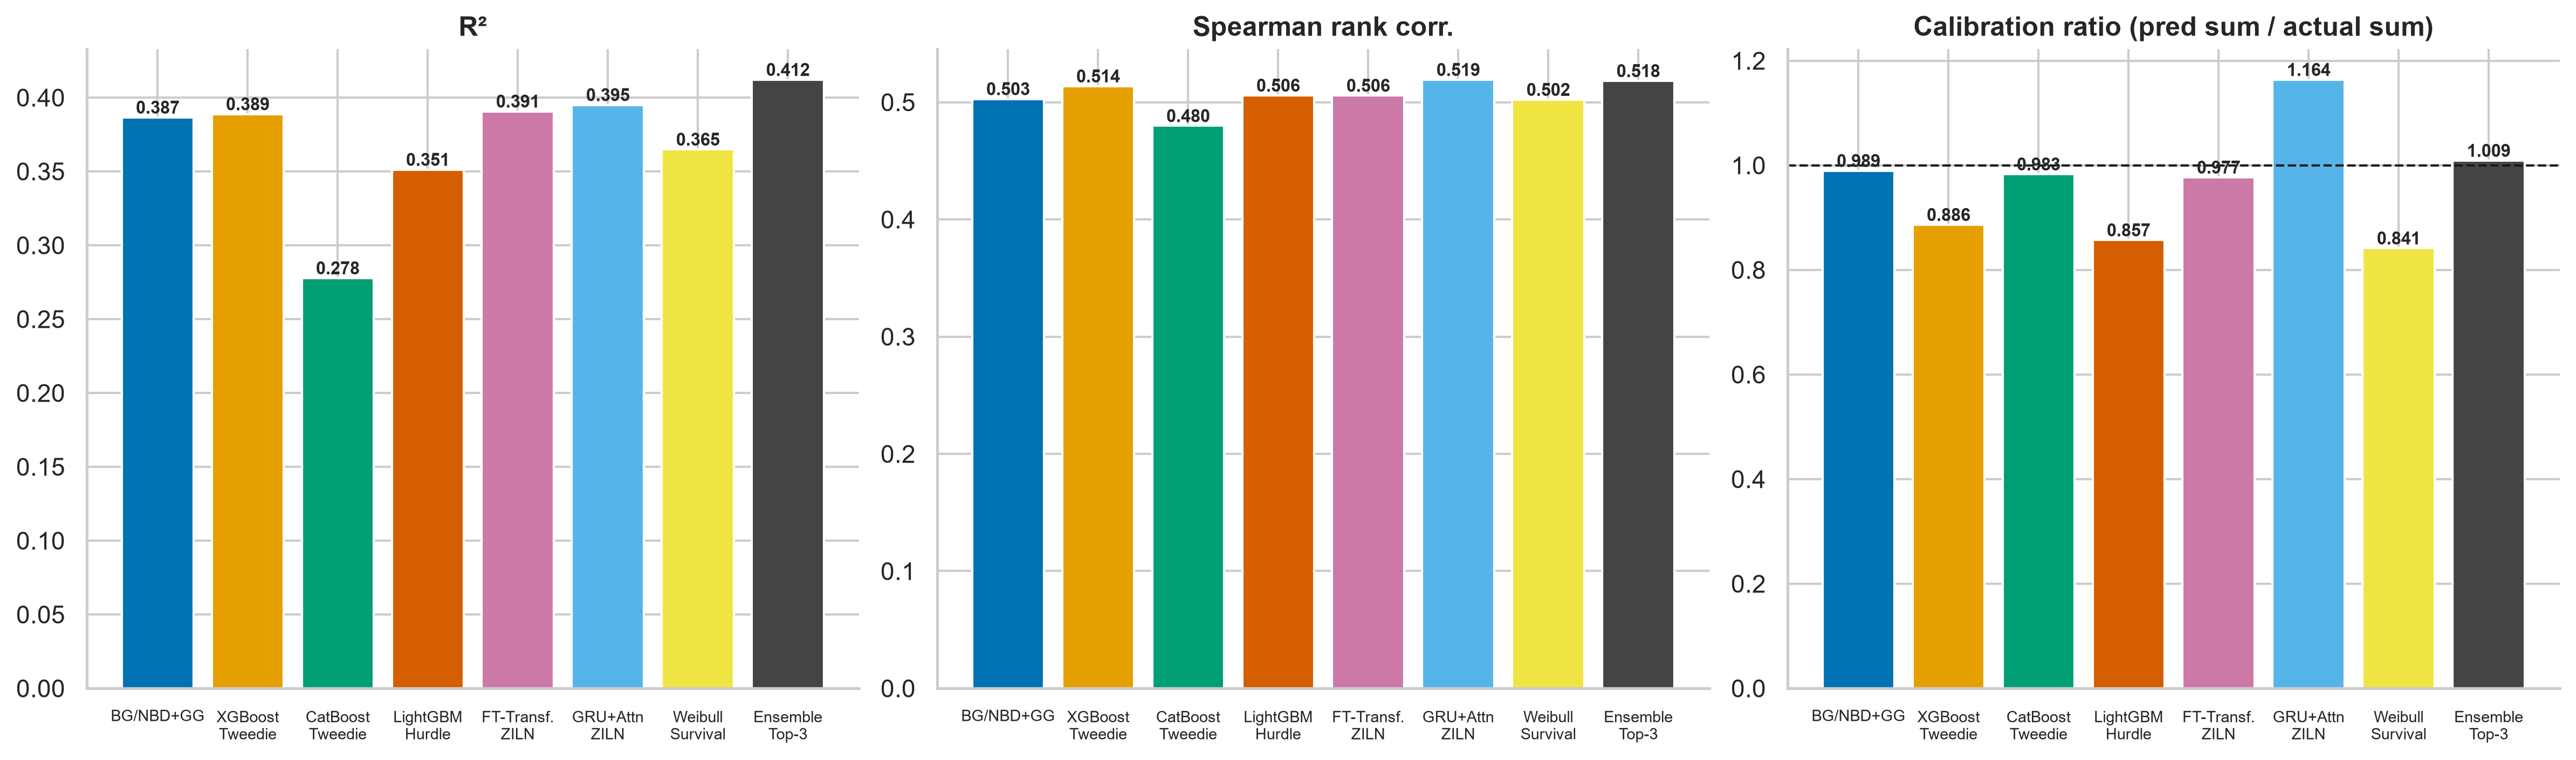

comparisons/cumulative_gain_lorenz.png


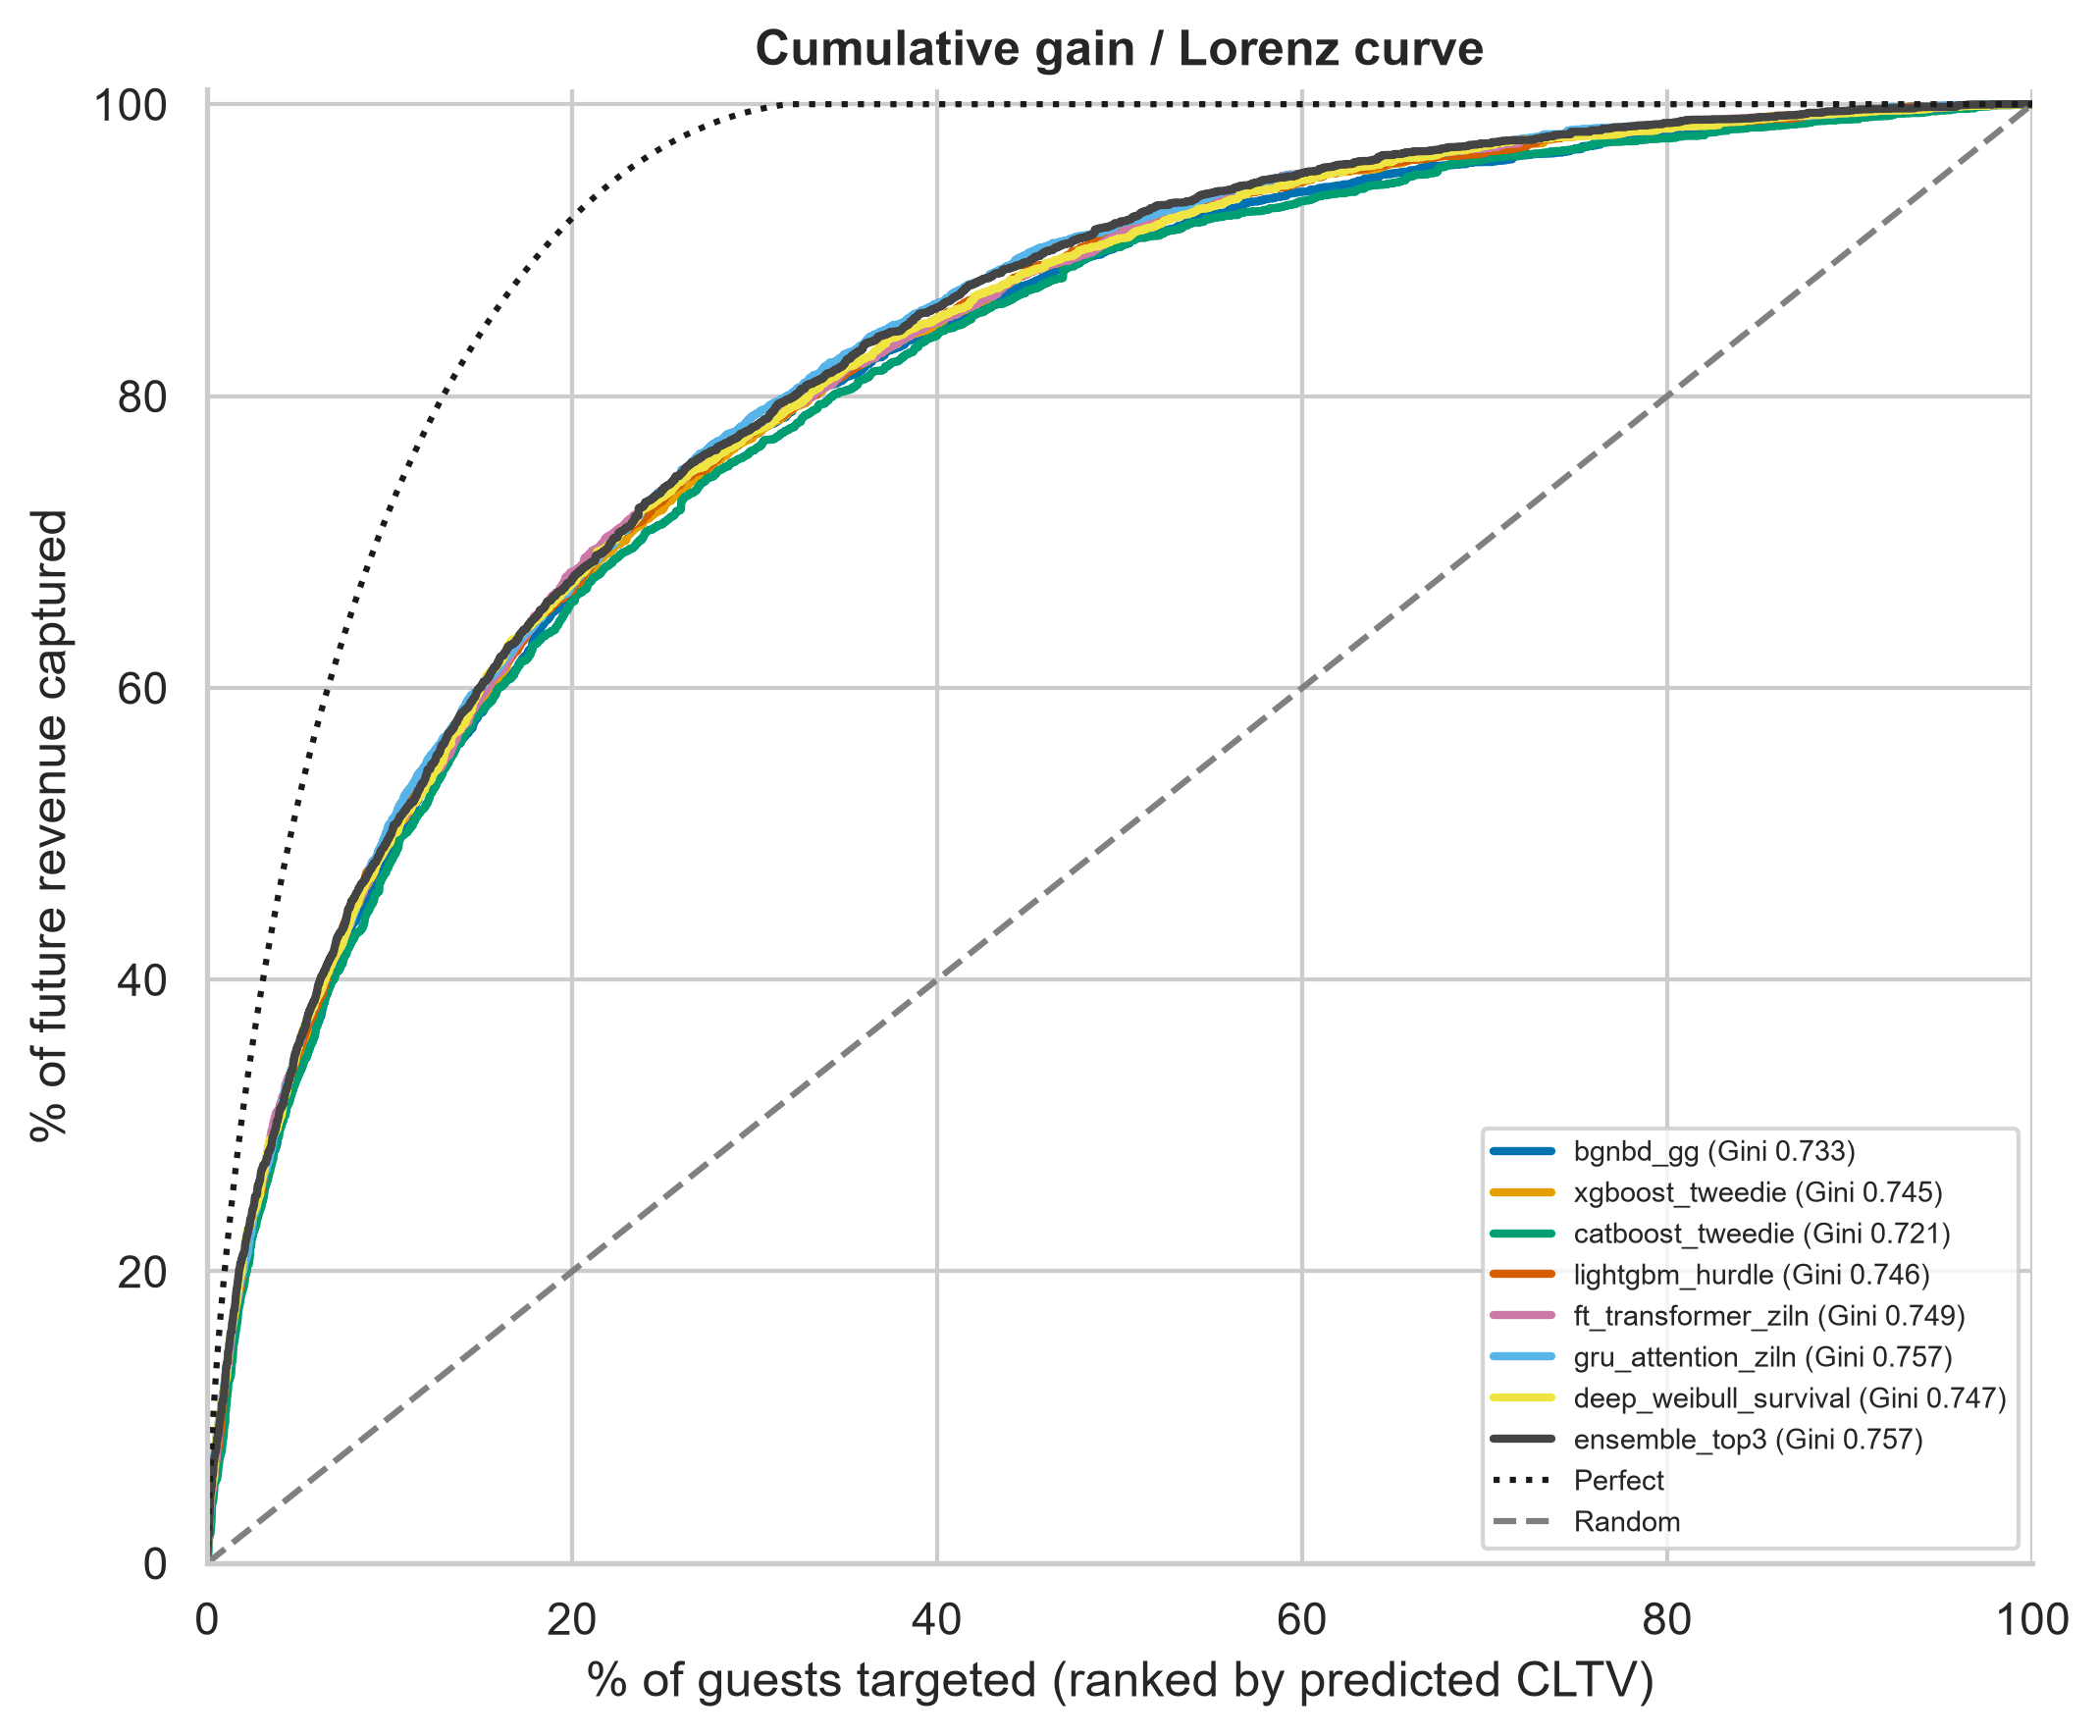

comparisons/calibration_by_decile.png


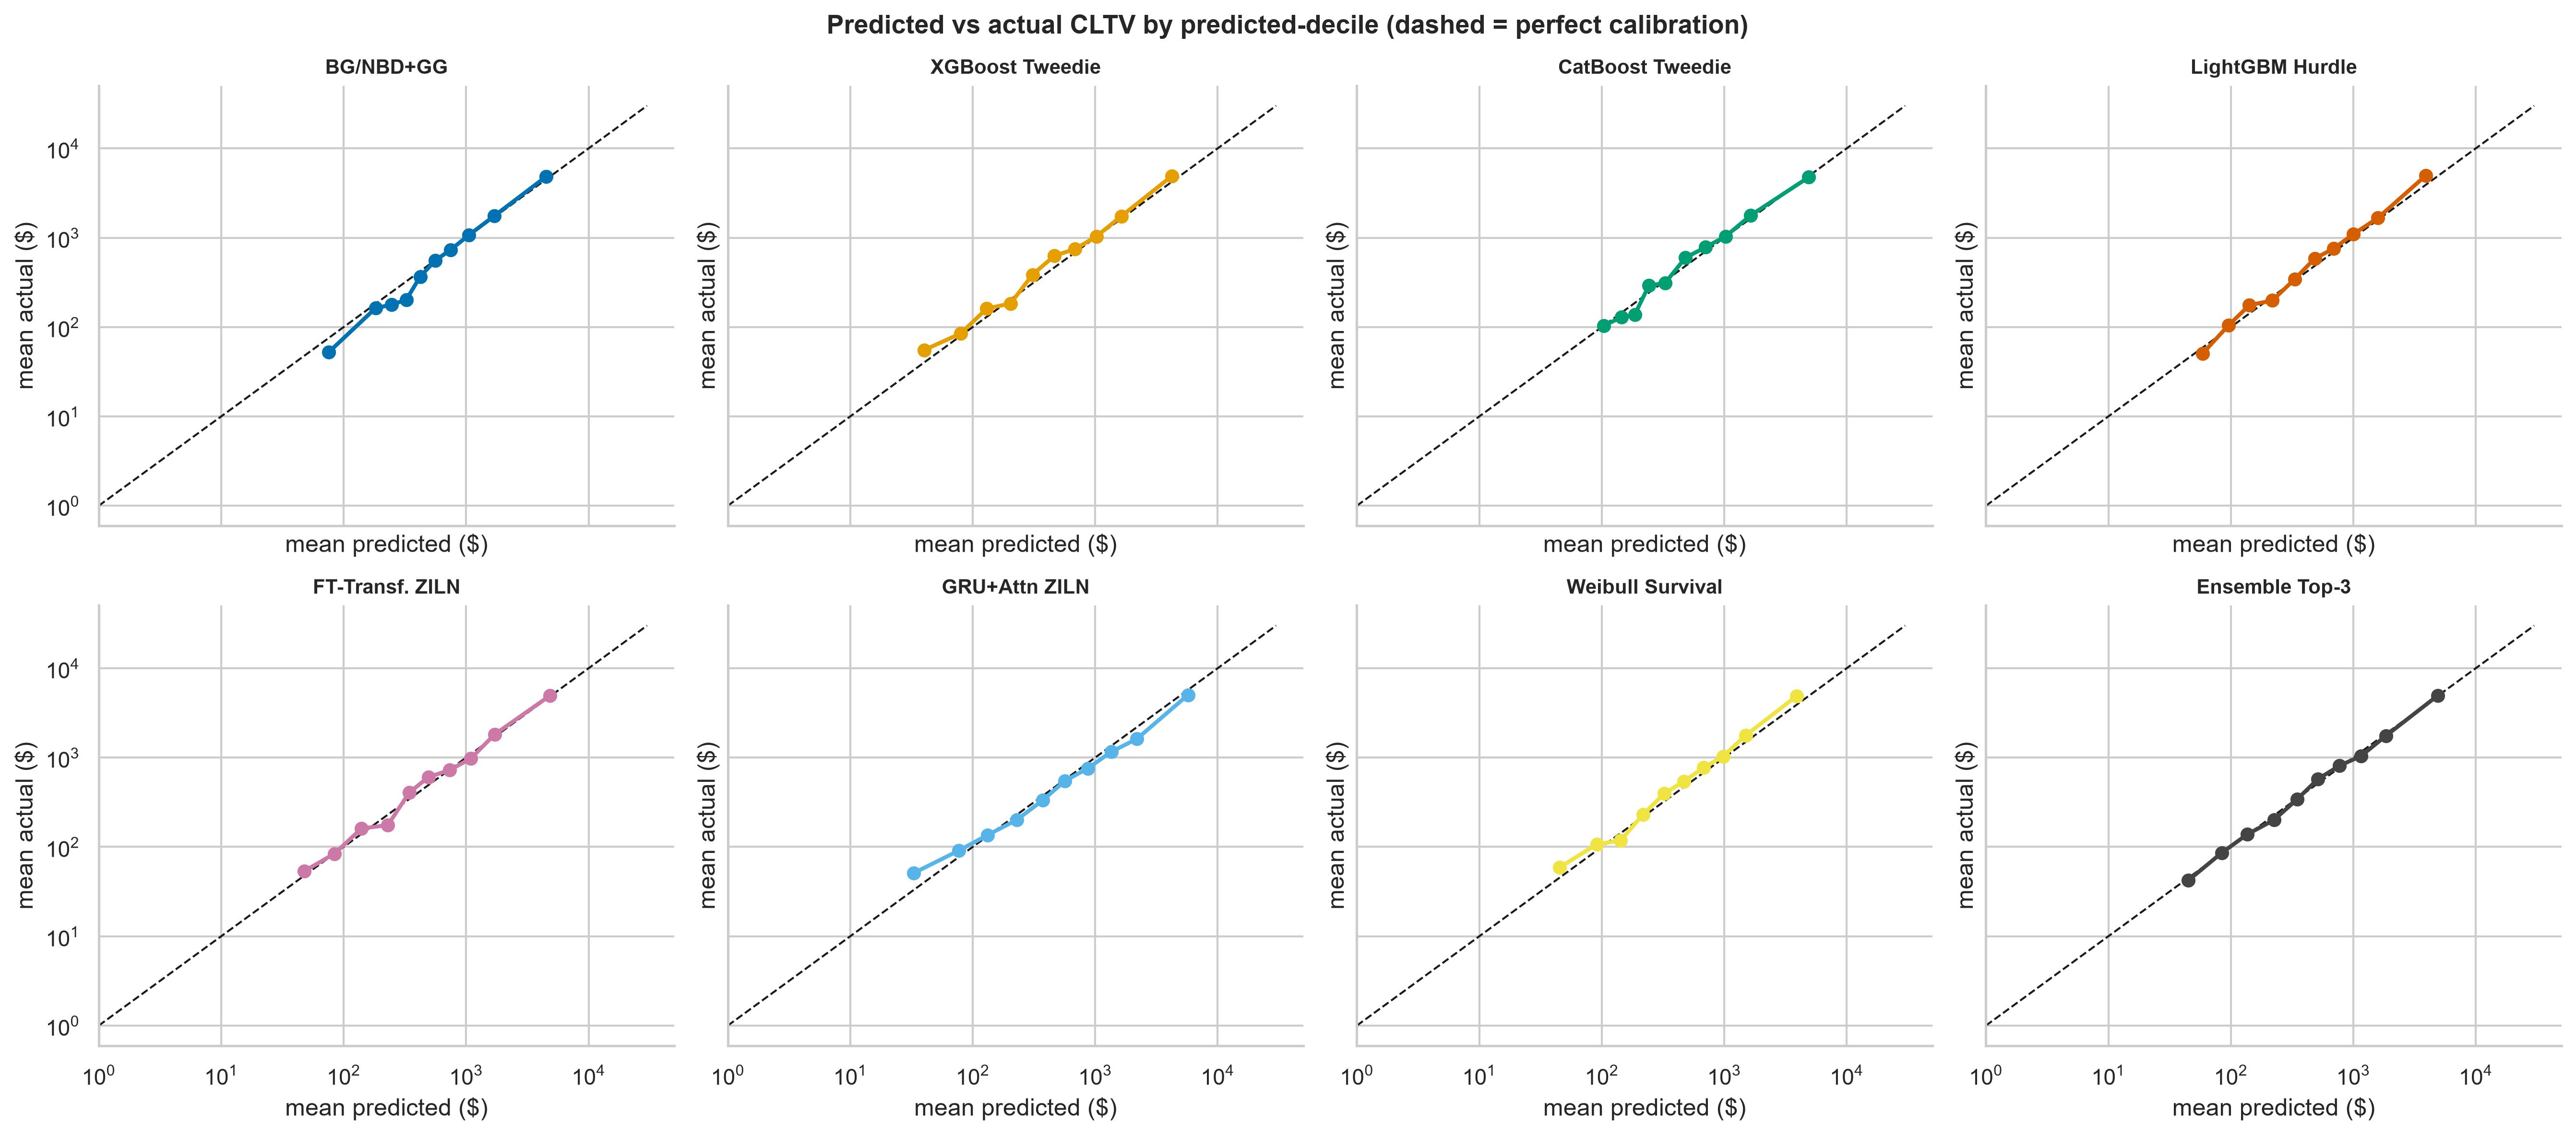

comparisons/calibration_best_model.png


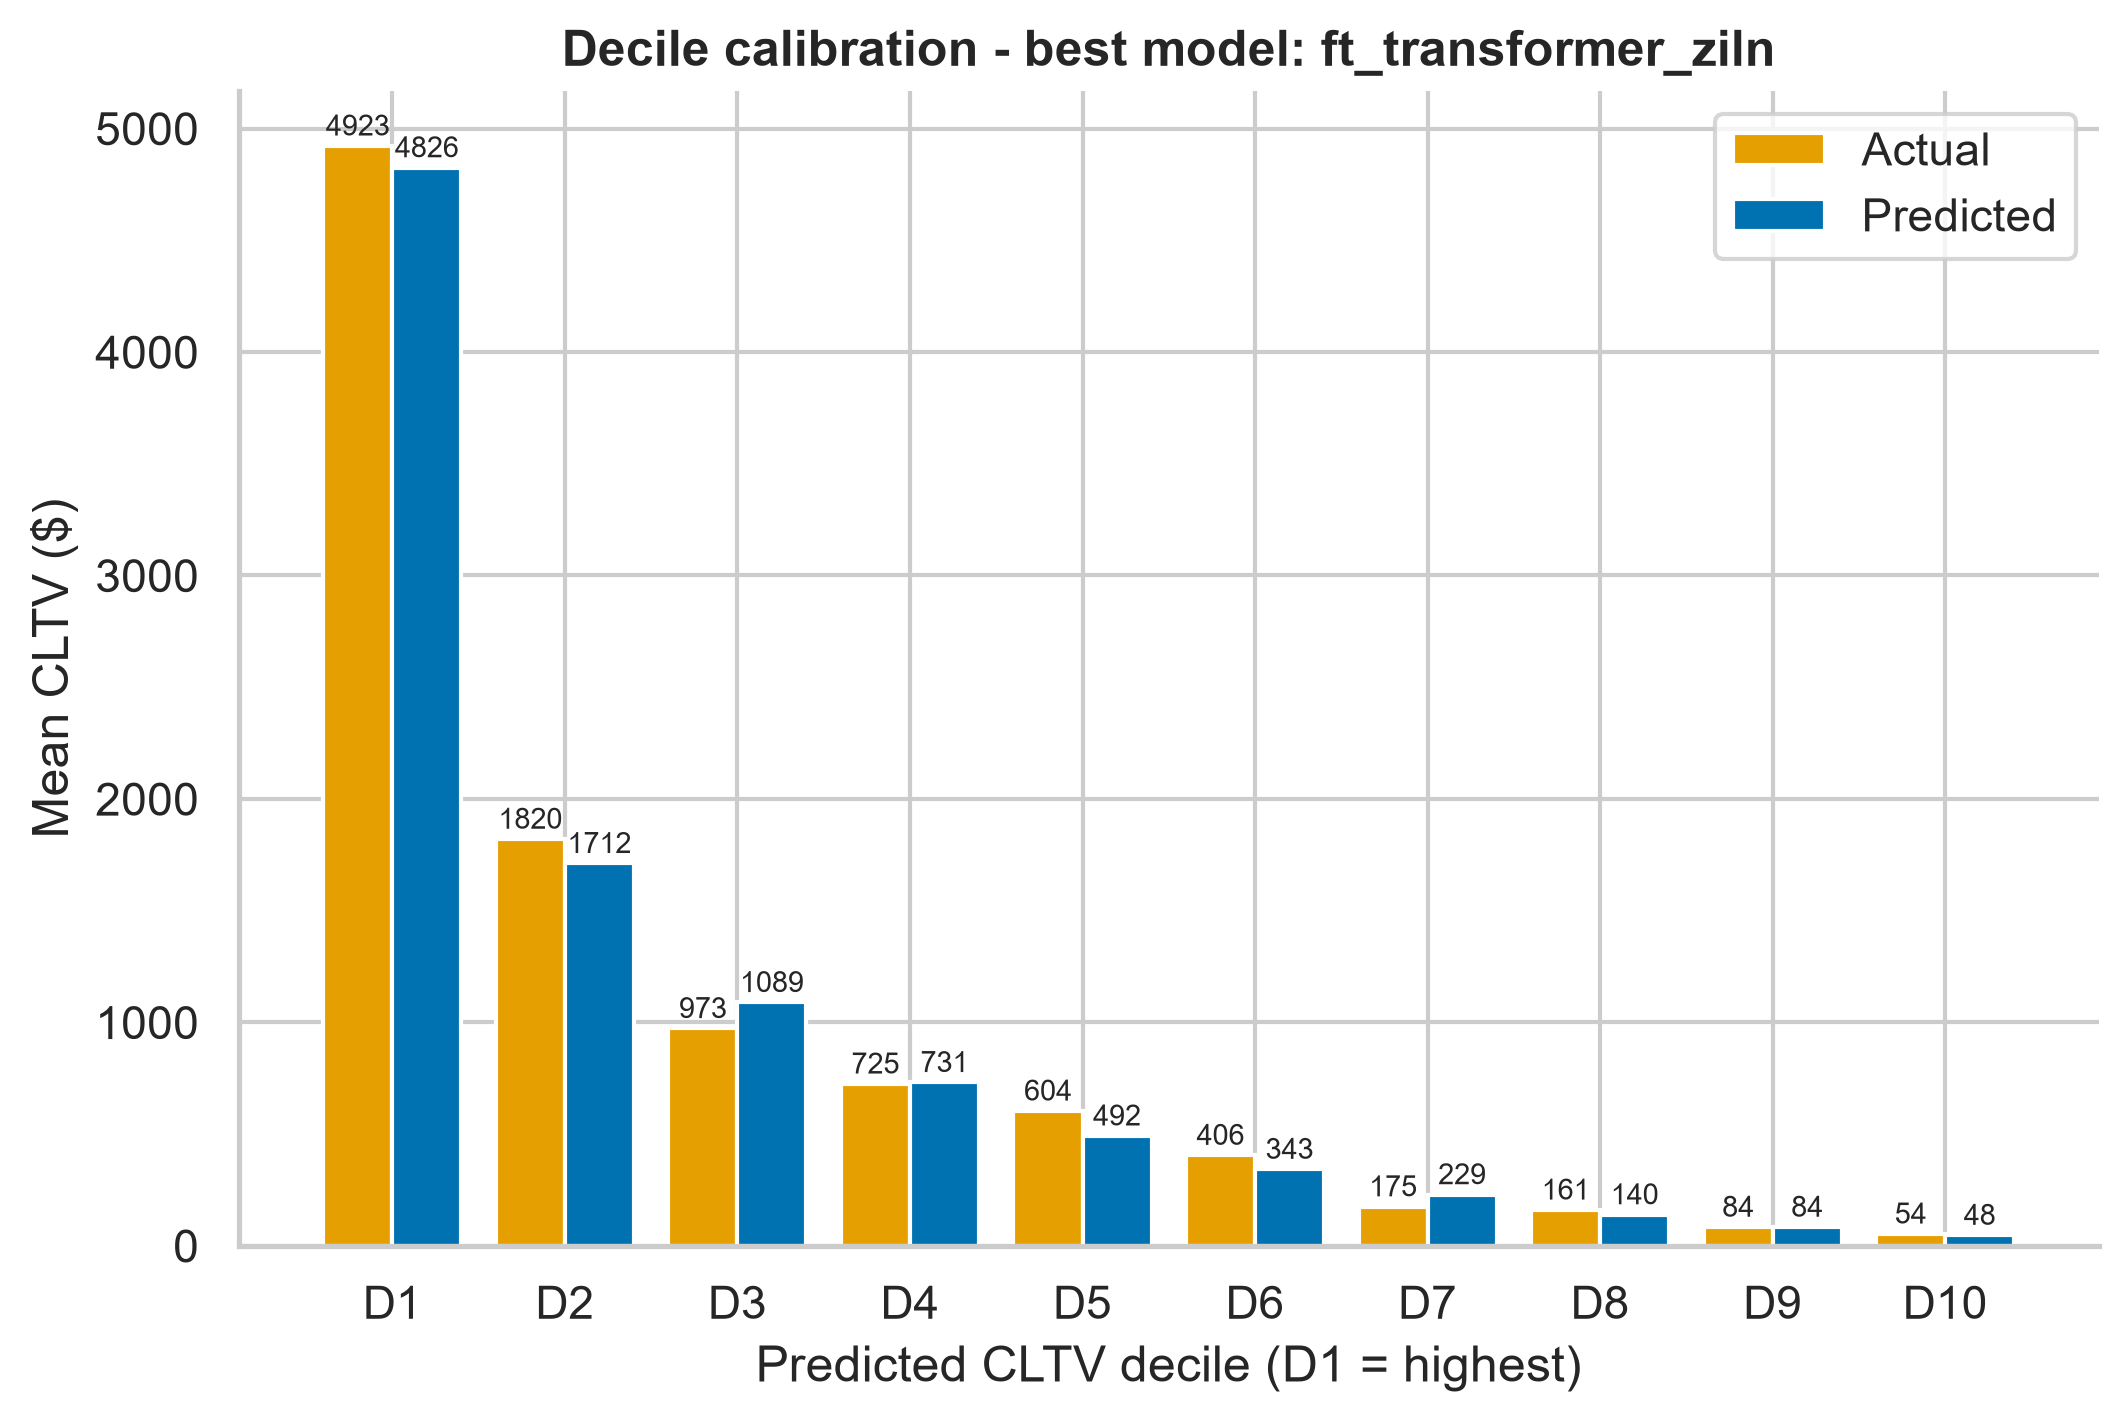

In [21]:
P = cfg['out'] / 'plots'
for p in ['eda/cltv_distribution.png','eda/spend_by_loyalty_tier.png','eda/leadtime_vs_adr.png','eda/retention_decay.png',
          'features/correlation_matrix.png','features/shap_beeswarm.png','features/shap_importance_bar.png',
          'features/permutation_importance.png','features/sequence_attention_heatmap.png',
          'training_loss/training_validation_loss_all_models.png','comparisons/model_comparison_metrics.png',
          'comparisons/model_comparison_secondary.png','comparisons/cumulative_gain_lorenz.png',
          'comparisons/calibration_by_decile.png','comparisons/calibration_best_model.png']:
    print(p); display(Image(filename=str(P / p), width=900))

In [22]:
needed = ['models/best_model.json','models/xgboost_tweedie.json','models/catboost_tweedie.cbm','models/ft_transformer_ziln.pt',
          'models/gru_attention_ziln.pt','models/deep_weibull_survival.pt','models/bgnbd_gg.joblib','models/lightgbm_hurdle.joblib',
          'logs/execution.log','logs/metrics_summary.json','logs/evaluation_report.csv','logs/training_history.jsonl']
missing = [n for n in needed if not (cfg['out'] / n).exists()]
print('missing artifacts:', missing or 'none')

missing artifacts: none
